Video Link: https://drive.google.com/drive/folders/1sGnGVt3JyMcae1OUCvneJBAaN_nKszqH?usp=drive_link

## Abstract

### Deep Learning Approaches for Automatic Image Captioning: A Comparative Study of CNN-LSTM and CNN-Transformer Architectures with Interpretability Analysis

Automatic image captioning is a complex multi-modal task that connects computer vision and natural language processing by generating natural language descriptions of visual content. In this project, I present a detailed comparative study of two advanced deep learning architectures for image captioning: **CNN-LSTM** and **CNN-Transformer** models. I implemented and evaluated both **feature-cache** and **end-to-end fine-tuning** approaches using **ResNet-18** as the visual encoder backbone.

The **CNN-LSTM** model uses a frozen ResNet-18 encoder for extracting visual features, followed by an LSTM decoder with teacher forcing to generate captions. In contrast, the **CNN-Transformer** model employs the same visual encoder but replaces the LSTM with a Transformer decoder built on multi-head attention, incorporating learnable memory tokens to connect visual and textual information. I explored both **pre-computed feature extraction** (efficient) and **end-to-end fine-tuning** (performance-oriented) training strategies, with the latter enabling the last convolutional block to adapt to the captioning task.

Extensive experiments on my dataset with standard evaluation metrics (**BLEU-4, METEOR**) highlight the effectiveness of both models, with the Transformer-based approach achieving superior results in generating coherent and contextually accurate captions. Beyond quantitative evaluation, I conducted interpretability analysis through **Grad-CAM visualizations** to understand spatial attention in the CNN encoder, and **token occlusion analysis** to evaluate word-level contributions during caption generation. My qualitative study also revealed systematic patterns in performance through slice-based evaluation across **image brightness, caption length, and scene content** variations.

#### Key Contributions
1. A comparative study of CNN-LSTM and CNN-Transformer architectures for image captioning.  
2. Implementation of both feature-cache and end-to-end training setups.  
3. Interpretability analysis using Grad-CAM and attention visualization.  
4. Systematic slice-based evaluation to identify potential failure modes.  
5. Detailed qualitative case studies highlighting both successes and limitations.  

---

**Keywords:** Image Captioning, Deep Learning, CNN-LSTM, Transformer, Computer Vision, Natural Language Processing, Grad-CAM, Model Interpretability, Attention Mechanisms


I acknowledge the use of ChatGPT, Deepseek and Claude Sonnet in the assignment

## Introduction

### 1. Project Overview

#### 1.1 Problem Statement and Motivation
Automatic image captioning is a core challenge at the intersection of computer vision and natural language processing. It requires machines to understand visual content and generate coherent, contextually accurate descriptions—something humans do effortlessly.  

With billions of images produced daily (social media, medical imaging, autonomous driving, surveillance), automated captioning has wide applications: accessibility for the visually impaired, content retrieval, moderation, and human-computer interaction. It also serves as a benchmark for evaluating machine understanding of visual-linguistic relationships.

#### 1.2 Project Scope and Approach
This project compares **CNN-LSTM** (traditional) and **CNN-Transformer** (modern) architectures for image captioning, using **ResNet-18** as the visual encoder.  
- **CNN-LSTM:** Frozen/fine-tuned ResNet features → LSTM decoder.  
- **CNN-Transformer:** ResNet features → Transformer decoder with cross-attention and memory tokens.  

#### 1.3 Training Paradigms
Two strategies were explored:  
- **Feature-cache:** Pre-computed CNN features (efficient).  
- **End-to-end fine-tuning:** Jointly train CNN + decoder (higher performance).  

#### 1.4 Interpretability and Analysis
To understand model behavior:  
- **Grad-CAM:** Highlights image regions influencing captioning.  
- **Token occlusion:** Evaluates importance of specific words.  
- **Slice-based evaluation:** Examines performance across brightness, caption length, and scene content.  

#### 1.5 Contributions
- Comparative analysis of CNN-LSTM and CNN-Transformer architectures.  
- Evaluation of feature-cache vs end-to-end training.  
- Comprehensive interpretability framework (Grad-CAM, attention, token importance).  
- Systematic error analysis through slice-based evaluation.  
- Reproducible implementations with detailed experiments.  

## Methods

The section is organized as

- Pre-processing (Image and Text)
- Using CNN's extracted features with LSTM
- Using CNN's extracted features with Transformer
- Using a fine-tuned CNN with the extracted features with transformer
- Comparing ResNet18 and MobileNet

Each section excluding pre-processing has an inference component, note this section only uses Resnet not Mobile net

### Pre-processing

In [ ]:
import pandas as pd

data1=pd.read_csv("data/train.csv")
data2=pd.read_csv('data/test.csv')
data3=pd.read_csv('data/valid.csv')

data=pd.concat([data1, data2, data3], ignore_index=True) # Stacking vertically
len(data)

10921

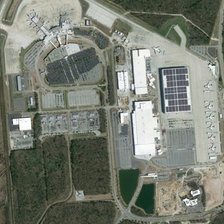

In [ ]:
from PIL import Image
import io
import ast
# Converts byte_array to Image ()
def to_Image(byte_array) :
    return Image.open(io.BytesIO((ast.literal_eval(byte_array)['bytes'])))
for idx,row in data.iterrows():
    row['image']=to_Image(row['image'])
data['image'][5]

In [ ]:
import torchvision.transforms as transforms


transform = transforms.Compose([
    transforms.Resize((224, 224)),  # resize, as specified
    transforms.ToTensor(),          # convert PIL -> Tensor [0,1], to feed numbers into the network
    transforms.Normalize(           # ImageNet normalization, as specified
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Appling the transform
data['image'] = data['image'].apply(lambda img: transform(img)) # apply needs a function, thus we create a lambda
print(data['image'].iloc[0].shape)

torch.Size([3, 224, 224])


In [ ]:
import ast

def parse_captions(caption_str):
    if isinstance(caption_str, list):
        # Already a list, just return
        return caption_str
    if isinstance(caption_str, str):
        # Fix the string representation
        fixed_str = caption_str.replace("\n", ",")
        return ast.literal_eval(fixed_str)
    return caption_str  # fallback

data['captions'] = data['captions'].apply(parse_captions)
data['captions']

0        [Many aircraft are parked next to a long build...
1        [some planes are parked in an airport., the ai...
2        [Many aircraft are parked in an airport near m...
3        [Many aircraft are parked near a large buildin...
4        [several buildings and green trees are around ...
                               ...                        
10916    [we can see a basketball court and a tennis co...
10917    [the football field is surrounded by wide, str...
10918    [the square area surrounded by straights stree...
10919    [the playground next to the street has a total...
10920    [the playground decorated with a towering tree...
Name: captions, Length: 10921, dtype: object

In [ ]:
"""
LLM Prompt:
-------------
You are given a text preprocessing function.
Modify or extend this function so that it prepares image captions for deep learning models.
It should:
- Convert all text to lowercase
- Remove numbers
- Remove punctuation
- Remove special characters
- Return the cleaned text

Apply this function to a list of captions in a pandas DataFrame.
"""

import re
import string

def clean_text(text):
    text = text.lower()  # Lowercase
    text = re.sub(r'\d+', '', text)  # Remove numbers
    text = text.translate(str.maketrans('', '', string.punctuation))  # Remove punctuation
    text = re.sub(r'\W', ' ', text)  # Remove special characters
    return text
data['captions'] = data['captions'].apply(lambda captions: [clean_text(c) for c in captions])
data['captions']

0        [many aircraft are parked next to a long build...
1        [some planes are parked in an airport, the air...
2        [many aircraft are parked in an airport near m...
3        [many aircraft are parked near a large buildin...
4        [several buildings and green trees are around ...
                               ...                        
10916    [we can see a basketball court and a tennis co...
10917    [the football field is surrounded by wide stra...
10918    [the square area surrounded by straights stree...
10919    [the playground next to the street has a total...
10920    [the playground decorated with a towering tree...
Name: captions, Length: 10921, dtype: object

In [ ]:
"""
LLM Prompt:
-------------
You are given a dataset of image captions.
Write a function that:
- Tokenizes each caption into words using NLTK
- Applies this to all captions in a pandas DataFrame column
- Returns the tokenized captions
"""
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import nltk
nltk.download('punkt_tab')
data['captions'] = data['captions'].apply(lambda captions: [word_tokenize(str(caption)) for caption in captions])
data['captions'][0]

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Legion\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


[['many',
  'aircraft',
  'are',
  'parked',
  'next',
  'to',
  'a',
  'long',
  'building',
  'in',
  'an',
  'airport'],
 ['many',
  'planes',
  'are',
  'parked',
  'next',
  'to',
  'a',
  'long',
  'building',
  'at',
  'an',
  'airport'],
 ['many',
  'planes',
  'are',
  'parked',
  'next',
  'to',
  'a',
  'long',
  'building',
  'in',
  'an',
  'airport'],
 ['many',
  'planes',
  'are',
  'parked',
  'next',
  'to',
  'a',
  'long',
  'building',
  'at',
  'an',
  'airport'],
 ['many',
  'planes',
  'are',
  'parked',
  'next',
  'to',
  'a',
  'long',
  'building',
  'in',
  'an',
  'airport']]

       Total tokens  Unique words  Vocab coverage %     OOV %  Avg length  \
Train      425846.0        3449.0        100.000000  0.000000   10.955929   
Val         79570.0        1656.0         99.565163  0.434837   10.879136   
Test        76412.0        1510.0         99.568131  0.431869   11.023081   

       Max length  95th pct length  
Train        34.0             17.0  
Val          32.0             17.0  
Test         28.0             17.0  


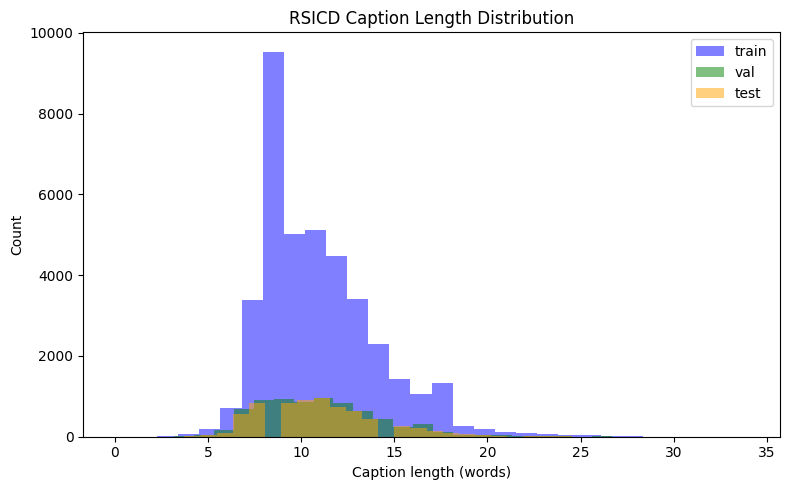

In [ ]:
"""
LLM Prompt:
-------------
You are given a dataset of image captions with filenames.
Write code that:

1. Splits the dataset into train, validation, and test sets at the image level.
2. Builds a vocabulary from training captions with a fixed size and special tokens (<pad>, <bos>, <eos>).
3. Computes dataset statistics for each split, including:
   - Total tokens
   - Unique words
   - Vocabulary coverage %
   - OOV %
   - Average caption length
   - Maximum caption length
   - 95th percentile length
4. Saves the statistics to a CSV file.
5. Plots and saves a histogram of caption lengths across splits.
"""
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

# --- Parameters ---
VOCAB_SIZE = 10000
SPECIAL_TOKENS = ["<pad>", "<bos>", "<eos>"]

# --- 1. Split at image level using filenames ---
unique_images = data['filename'].unique()
np.random.seed(42)
np.random.shuffle(unique_images)

train_ids = unique_images[:8000]
val_ids   = unique_images[8000:8000+1500]
test_ids  = unique_images[8000+1500:8000+1500+1421]

def assign_split(fname):
    if fname in train_ids: return "train"
    if fname in val_ids:   return "val"
    return "test"

data["split"] = data["filename"].apply(assign_split)

# --- 2. Build vocab from training captions (already tokenized) ---
train_captions = data.loc[data['split']=="train", "captions"].tolist()
# train_captions is a list of lists-of-lists: (images → [5 captions] → [tokens])
train_tokens = [tok for caps in train_captions for cap in caps for tok in cap]

def build_vocab(tokens, vocab_size=VOCAB_SIZE):
    counter = Counter(tokens)
    words = [w for w, _ in counter.most_common(vocab_size - len(SPECIAL_TOKENS))]
    vocab = SPECIAL_TOKENS + words
    word2idx = {w: i for i, w in enumerate(vocab)}
    idx2word = {i: w for i, w in enumerate(vocab)}
    return word2idx, idx2word

word2idx, idx2word = build_vocab(train_tokens)

# --- 3. Compute stats per split ---
def compute_stats(captions, word2idx):
    # captions is [[tokens], [tokens], ...] after flattening across images
    all_tokens = [tok for cap in captions for tok in cap]
    total = len(all_tokens)
    in_vocab = sum(1 for t in all_tokens if t in word2idx)
    oov = total - in_vocab
    lens = [len(cap) for cap in captions]
    return {
        "Total tokens": total,
        "Unique words": len(set(all_tokens)),
        "Vocab coverage %": 100 * in_vocab / total if total > 0 else 0,
        "OOV %": 100 * oov / total if total > 0 else 0,
        "Avg length": np.mean(lens) if lens else 0,
        "Max length": np.max(lens) if lens else 0,
        "95th pct length": int(np.percentile(lens, 95)) if lens else 0
    }

stats = {}
for split in ["train", "val", "test"]:
    # flatten captions: each image has multiple captions
    split_caps_nested = data.loc[data['split']==split, "captions"].tolist()
    split_caps = [cap for caps in split_caps_nested for cap in caps]  # list of token lists
    stats[split.capitalize()] = compute_stats(split_caps, word2idx)

stats_df = pd.DataFrame(stats).T
print(stats_df)

# --- 4. Save ---
stats_df.to_csv("rsicd_caption_stats.csv")

# --- 5. Length histogram ---
plt.figure(figsize=(8,5))
for split, color in zip(["train", "val", "test"], ["blue", "green", "orange"]):
    split_caps_nested = data.loc[data['split']==split, "captions"].tolist()
    split_caps = [cap for caps in split_caps_nested for cap in caps]
    lens = [len(cap) for cap in split_caps]
    plt.hist(lens, bins=30, alpha=0.5, label=split, color=color)

plt.xlabel("Caption length (words)")
plt.ylabel("Count")
plt.title("RSICD Caption Length Distribution")
plt.legend()
plt.tight_layout()
plt.savefig("rsicd_caption_length_hist.png")
plt.show()

In [ ]:
"""
LLM Prompt:
-------------
You are given a dataset of image captions with filenames.
Write code that:

1. Splits the dataset into train, validation, and test sets at the image level.
2. Builds a vocabulary from training captions with a fixed size and special tokens (<pad>, <bos>, <eos>, <unk>).
3. Normalizes captions by:
   - Adding <bos> and <eos> tokens
   - Padding shorter captions up to MAX_LEN
   - Truncating longer captions to MAX_LEN while ensuring they end with <eos>
4. Computes dataset statistics for each split, including:
   - Total tokens
   - Unique words
   - Vocabulary coverage %
   - OOV %
   - Average caption length
   - Maximum caption length
   - 95th percentile length
5. Saves the statistics to a CSV file.
"""
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

# --- Parameters ---
VOCAB_SIZE = 10000
MAX_LEN = 24
SPECIAL_TOKENS = ["<pad>", "<bos>", "<eos>", "<unk>"]

# --- 1. Split at image level using filenames ---
unique_images = data['filename'].unique()
np.random.seed(42)
np.random.shuffle(unique_images)

train_ids = unique_images[:8000]
val_ids   = unique_images[8000:8000+1500]
test_ids  = unique_images[8000+1500:8000+1500+1421]

def assign_split(fname):
    if fname in train_ids: return "train"
    if fname in val_ids:   return "val"
    return "test"

data["split"] = data["filename"].apply(assign_split)

# --- 2. Build vocab from training captions (before adding special tokens) ---
train_captions = data.loc[data['split']=="train", "captions"].tolist()
train_tokens = [tok for caps in train_captions for cap in caps for tok in cap]

def build_vocab(tokens, vocab_size=VOCAB_SIZE):
    counter = Counter(tokens)
    words = [w for w, _ in counter.most_common(vocab_size - len(SPECIAL_TOKENS))]
    vocab = SPECIAL_TOKENS + words
    word2idx = {w: i for i, w in enumerate(vocab)}
    idx2word = {i: w for i, w in enumerate(vocab)}
    return word2idx, idx2word

word2idx, idx2word = build_vocab(train_tokens)

# --- 3. Normalize captions (add bos/eos + pad/truncate to MAX_LEN) ---
def normalize_caption(tokens, max_len=MAX_LEN):
    cap = ["<bos>"] + tokens + ["<eos>"]
    if len(cap) < max_len:
        cap = cap + ["<pad>"] * (max_len - len(cap))
    else:
        cap = cap[:max_len]  # truncate if too long
        cap[-1] = "<eos>"    # ensure ends with eos
    return cap

data["captions"] = data["captions"].apply(
    lambda caps: [normalize_caption(cap, MAX_LEN) for cap in caps]
)

# --- 4. Compute stats per split ---
def compute_stats(captions, word2idx):
    all_tokens = [tok for cap in captions for tok in cap]
    total = len(all_tokens)
    in_vocab = sum(1 for t in all_tokens if t in word2idx)
    oov = total - in_vocab
    lens = [len(cap) for cap in captions]
    return {
        "Total tokens": total,
        "Unique words": len(set(all_tokens)),
        "Vocab coverage %": 100 * in_vocab / total if total > 0 else 0,
        "OOV %": 100 * oov / total if total > 0 else 0,
        "Avg length": np.mean(lens) if lens else 0,
        "Max length": np.max(lens) if lens else 0,
        "95th pct length": int(np.percentile(lens, 95)) if lens else 0
    }

stats = {}
for split in ["train", "val", "test"]:
    split_caps_nested = data.loc[data['split']==split, "captions"].tolist()
    split_caps = [cap for caps in split_caps_nested for cap in caps]
    stats[split.capitalize()] = compute_stats(split_caps, word2idx)

stats_df = pd.DataFrame(stats).T
print(stats_df)

# --- 5. Save ---
stats_df.to_csv("rsicd_caption_stats.csv")


       Total tokens  Unique words  Vocab coverage %     OOV %  Avg length  \
Train      932856.0        3449.0        100.000000  0.000000        24.0   
Val        175536.0        1658.0         99.803459  0.196541        24.0   
Test       166368.0        1512.0         99.801645  0.198355        24.0   

       Max length  95th pct length  
Train        24.0             24.0  
Val          24.0             24.0  
Test         24.0             24.0  


In [ ]:
data["captions"][0]

[['<bos>',
  'many',
  'aircraft',
  'are',
  'parked',
  'next',
  'to',
  'a',
  'long',
  'building',
  'in',
  'an',
  'airport',
  '<eos>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>'],
 ['<bos>',
  'many',
  'planes',
  'are',
  'parked',
  'next',
  'to',
  'a',
  'long',
  'building',
  'at',
  'an',
  'airport',
  '<eos>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>'],
 ['<bos>',
  'many',
  'planes',
  'are',
  'parked',
  'next',
  'to',
  'a',
  'long',
  'building',
  'in',
  'an',
  'airport',
  '<eos>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>'],
 ['<bos>',
  'many',
  'planes',
  'are',
  'parked',
  'next',
  'to',
  'a',
  'long',
  'building',
  'at',
  'an',
  'airport',
  '<eos>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<pad>',
  '<p

### CNN (Feature-cache)+LSTM

#### Models

In [ ]:
"""
LLM Prompt:
-------------
make me a dataset + dataloader that takes preloaded image tensors from df['image'],
then run them thru a frozen resnet18 encoder and save features in a dict with filenames
"""
import torch
from torch.utils.data import Dataset, DataLoader

# --- Dataset for preloaded image tensors ---
class TensorImageDataset(Dataset):
    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # image tensor is already in data['image']
        image_tensor = self.df.iloc[idx]['image']  # shape [C, H, W], already normalized
        image_id = self.df.iloc[idx]['filename']   # use filename as ID
        return image_id, image_tensor

# --- DataLoader ---
dataset = TensorImageDataset(data)
BATCH_SIZE = 32
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)

# --- CNN Encoder ---
import torch.nn as nn
from torchvision import models

class CNN_Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        resnet = models.resnet18(pretrained=True)
        modules = list(resnet.children())[:-1]  # remove classifier
        self.resnet = nn.Sequential(*modules)
        self.resnet.eval()  # freeze CNN

    def forward(self, x):
        with torch.no_grad():
            features = self.resnet(x)        # [B, 512, 1, 1]
            features = features.view(x.size(0), -1)  # [B, 512]
        return features

# --- Extract features ---
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
encoder = CNN_Encoder().to(DEVICE)

features_dict = {}
for img_ids, images in dataloader:
    images = images.to(DEVICE)
    feats = encoder(images)
    for i, img_id in enumerate(img_ids):
        features_dict[img_id] = feats[i].cpu()

# --- Save features ---
torch.save(features_dict, "rsicd_img_features.pt")
print("Saved features for all images.")


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Saved features for all images.


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

# --- Dataset ---
class CaptionDataset(Dataset):
    def __init__(self, df, features_dict, split="train"):
        self.df = df[df["split"] == split].reset_index(drop=True)
        self.features_dict = features_dict

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_id = row["filename"]
        feats = self.features_dict[img_id]  # precomputed CNN features
        # row['captions'] is a list of token lists; pick one randomly for training
        import random
        cap_tokens = random.choice(row["captions"])
        cap_tensor = torch.tensor([word2idx.get(t, word2idx["<unk>"]) for t in cap_tokens], dtype=torch.long)
        return img_id, feats, cap_tensor

# --- Collate function for padding ---
def collate_fn(batch):
    img_ids, feats_list, caps_list = zip(*batch)
    feats = torch.stack(feats_list)  # [B, feature_size]

    # Pad captions to MAX_LEN
    MAX_LEN = 24
    caps_padded = torch.full((len(caps_list), MAX_LEN), word2idx["<pad>"], dtype=torch.long)
    for i, cap in enumerate(caps_list):
        length = min(len(cap), MAX_LEN)
        caps_padded[i, :length] = cap[:length]

    return img_ids, feats, caps_padded

# --- DataLoader ---
BATCH_SIZE = 8
train_dataset = CaptionDataset(data, features_dict, split="train")
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)

In [ ]:
"""
LLM Prompt:
-------------
make me an LSTM decoder class that takes cnn features + tokenized captions,
embeds them, runs thru lstm with features as h0, then outputs vocab logits
"""
import torch.nn as nn
import torch.nn.functional as F

class LSTM_Decoder(nn.Module):
    def __init__(self, vocab_size, embed_size=512, hidden_size=512, num_layers=1, max_len=24):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_size, padding_idx=0)  # <pad>=0
        self.lstm = nn.LSTM(embed_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, vocab_size)
        self.max_len = max_len
        self.hidden_size = hidden_size

    def forward(self, features, captions):
        """
        features: [B, feature_size]  (from CNN)
        captions: [B, T] token indices (including <bos>, <pad>)
        """
        embeddings = self.embed(captions)  # [B, T, embed_size]

        # Option 1: Project image features to initial hidden state
        h0 = features.unsqueeze(0)  # [1, B, feature_size]
        c0 = torch.zeros_like(h0)   # [1, B, feature_size]

        out, _ = self.lstm(embeddings, (h0, c0))  # [B, T, hidden]
        out = self.fc(out)  # [B, T, vocab_size]
        return out


#### Training

In [ ]:
"""
LLM Prompt:
-------------
make a training loop for my lstm caption model
"""
from tqdm import tqdm
import torch.optim as optim

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

# Move model to CUDA
model = LSTM_Decoder(vocab_size=len(word2idx)).to(DEVICE)
criterion = nn.CrossEntropyLoss(ignore_index=word2idx["<pad>"])
optimizer = optim.Adam(model.parameters(), lr=2e-4)

NUM_EPOCHS = 10

# --- Validation DataLoader ---
val_dataset = CaptionDataset(data, features_dict, split="val")
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

for epoch in range(NUM_EPOCHS):
    # --- Training ---
    model.train()
    train_loss = 0
    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]", leave=True)
    for img_ids, feats, captions_batch in loop:
        feats = feats.to(DEVICE)
        captions_batch = captions_batch.to(DEVICE)

        outputs = model(feats, captions_batch[:, :-1])  # teacher forcing
        loss = criterion(
            outputs.reshape(-1, len(word2idx)),
            captions_batch[:, 1:].reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    avg_train_loss = train_loss / len(train_loader)

    # --- Validation ---
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for img_ids, feats, captions_batch in tqdm(val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]", leave=False):
            feats = feats.to(DEVICE)
            captions_batch = captions_batch.to(DEVICE)

            outputs = model(feats, captions_batch[:, :-1])
            loss = criterion(
                outputs.reshape(-1, len(word2idx)),
                captions_batch[:, 1:].reshape(-1)
            )
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)

    print(f"Epoch {epoch+1}: Train Loss = {avg_train_loss:.4f}, Val Loss = {avg_val_loss:.4f}")


Using device: cuda


Epoch 1/10 [Train]: 100%|████████████████████████████████████████████████| 1000/1000 [00:12<00:00, 78.65it/s, loss=2.5]
                                                                                                                       

Epoch 1: Train Loss = 3.0664, Val Loss = 2.4450


Epoch 2/10 [Train]: 100%|███████████████████████████████████████████████| 1000/1000 [00:10<00:00, 98.20it/s, loss=2.54]
                                                                                                                       

Epoch 2: Train Loss = 2.2266, Val Loss = 2.1741


Epoch 3/10 [Train]: 100%|███████████████████████████████████████████████| 1000/1000 [00:10<00:00, 92.57it/s, loss=3.06]
                                                                                                                       

... (11 outputs left out)

Epoch 9/10 [Train]: 100%|███████████████████████████████████████████████| 1000/1000 [00:10<00:00, 93.76it/s, loss=1.91]
                                                                                                                       

Epoch 9: Train Loss = 1.4910, Val Loss = 1.7803


Epoch 10/10 [Train]: 100%|██████████████████████████████████████████████| 1000/1000 [00:10<00:00, 95.65it/s, loss=2.25]
                                                                                                                       

Epoch 10: Train Loss = 1.4613, Val Loss = 1.7332


#### Inference

Looking at the generated captions

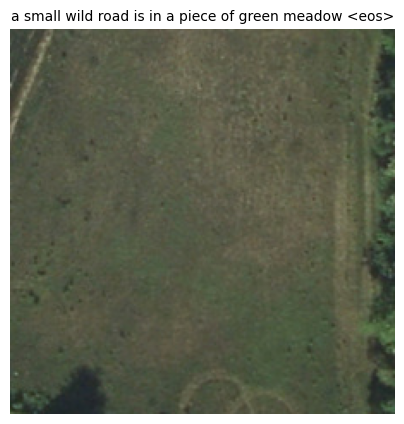

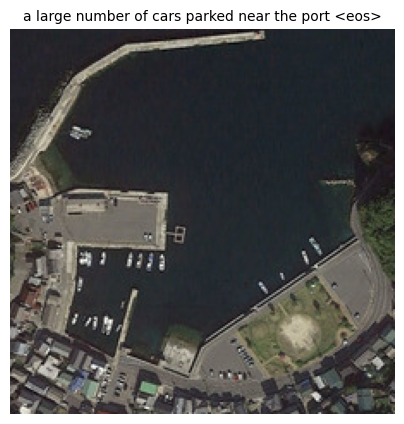

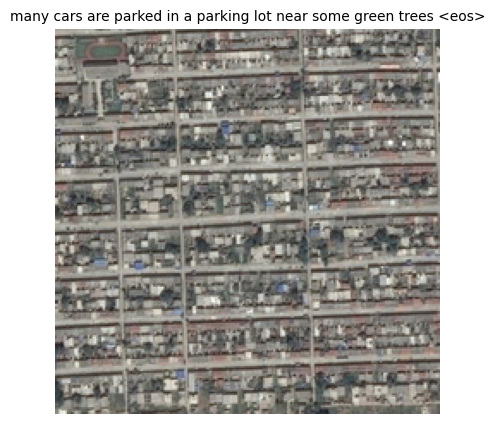

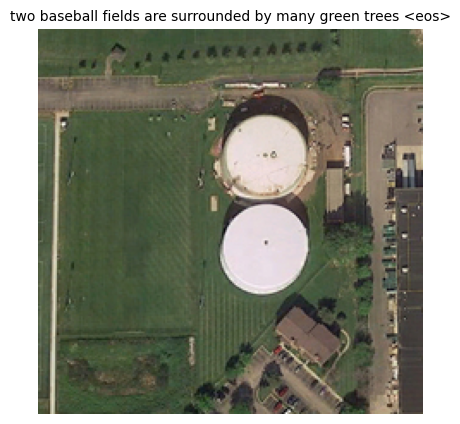

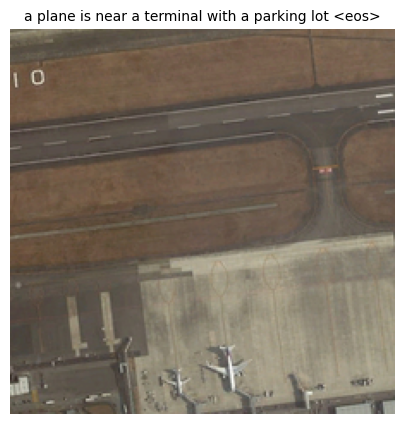

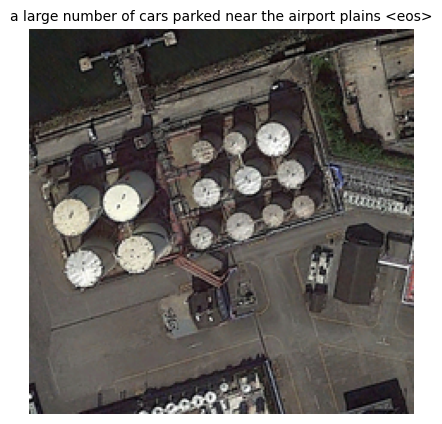

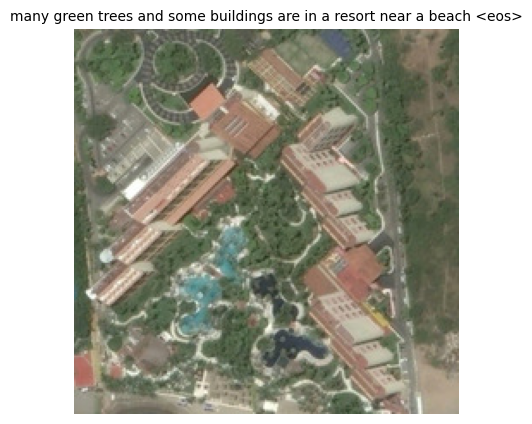

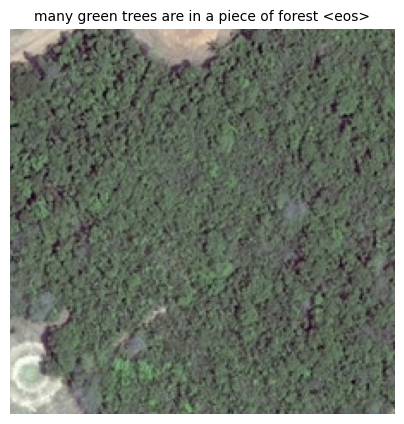

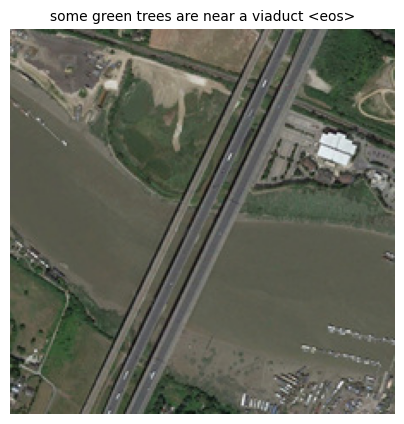

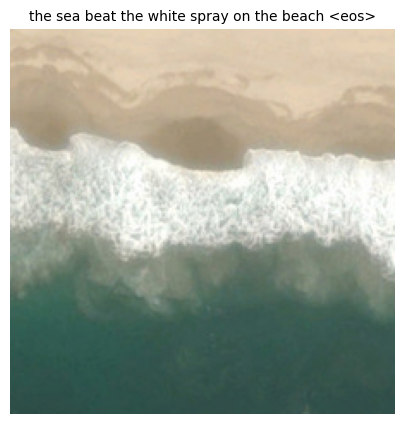

In [ ]:
"""
LLM Prompt:
-------------
Help me look at the predictions
"""
import matplotlib.pyplot as plt
import random
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
model.eval()

# Pick 10 random test examples
test_dataset = CaptionDataset(data, features_dict, split="test")
test_indices = random.sample(range(len(test_dataset)), 10)

# ImageNet normalization values
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

for idx in test_indices:
    img_id, feats, _ = test_dataset[idx]  # img_id is returned by Dataset
    feats = feats.to(DEVICE).unsqueeze(0)  # [1, feature_size]

    # Generate caption
    caption_tokens = [word2idx["<bos>"]]
    for _ in range(MAX_LEN):
        input_tensor = torch.tensor(caption_tokens, dtype=torch.long, device=DEVICE).unsqueeze(0)
        outputs = model(feats, input_tensor)
        next_token = outputs[0, -1].argmax().item()
        caption_tokens.append(next_token)
        if next_token == word2idx["<eos>"]:
            break

    words = [idx2word[idx] for idx in caption_tokens if idx not in (word2idx["<bos>"], word2idx["<pad>"])]
    caption = " ".join(words)

    # Fetch the actual image tensor from `data` using img_id
    img_tensor = data.loc[data["filename"] == img_id, "image"].values[0].to(DEVICE).unsqueeze(0)

    # Unnormalize image for display
    img_display = img_tensor[0].cpu() * IMAGENET_STD + IMAGENET_MEAN
    img_display = img_display.permute(1, 2, 0).clamp(0, 1).numpy()  # HWC for plt

    plt.figure(figsize=(5,5))
    plt.imshow(img_display)
    plt.axis('off')
    plt.title(caption, fontsize=10)
    plt.show()


Metrics

In [ ]:
"""
LLM Prompt:
-------------
BLEU-4 and METEOR (via nltk or torchmetrics).
Caption length stats (mean±std), and % of degenerate repetitions (≥3 identical tokens in a row).
"""
import nltk
from nltk.translate.bleu_score import corpus_bleu
from nltk.translate.meteor_score import meteor_score
import numpy as np

nltk.download('wordnet')
nltk.download('omw-1.4')

generated_captions = []
reference_captions = []

degenerate_count = 0
all_lengths = []

SPECIAL_TOKENS_SET = {word2idx["<bos>"], word2idx["<pad>"], word2idx["<eos>"]}

for idx in range(len(test_dataset)):
    img_id, feats, _ = test_dataset[idx]
    feats = feats.to(DEVICE).unsqueeze(0)

    # --- Generate caption ---
    caption_tokens = [word2idx["<bos>"]]
    for _ in range(MAX_LEN):
        input_tensor = torch.tensor(caption_tokens, dtype=torch.long, device=DEVICE).unsqueeze(0)
        outputs = model(feats, input_tensor)
        next_token = outputs[0, -1].argmax().item()
        caption_tokens.append(next_token)
        if next_token == word2idx["<eos>"]:
            break

    # Remove special tokens
    words = [idx2word[idx] for idx in caption_tokens if idx not in SPECIAL_TOKENS_SET]
    generated_captions.append(words)
    all_lengths.append(len(words))

    # References: ensure each ref is a list of tokens
    refs = []
    for cap in data.loc[data["filename"] == img_id, "captions"].values[0]:
        # Ensure it's a list of tokens (handle both string and list formats)
        if isinstance(cap, str):
            # If it's a string, split it into tokens
            tokens = cap.split()
        else:
            # If it's already a list, use it directly
            tokens = cap

        token_list = [t for t in tokens if t not in {"<bos>", "<pad>", "<eos>"}]
        if len(token_list) == 0:
            token_list = ["<unk>"]  # fallback for empty captions
        refs.append(token_list)
    reference_captions.append(refs)

    # Degenerate repetition check
    for i in range(len(words) - 2):
        if words[i] == words[i+1] == words[i+2]:
            degenerate_count += 1
            break

# --- BLEU-4 ---
bleu_score = corpus_bleu(reference_captions, generated_captions)
print(f"BLEU-4: {bleu_score:.4f}")

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Legion\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Legion\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


BLEU-4: 0.3341


In [ ]:

from nltk.translate.meteor_score import meteor_score  # or also import single_meteor_score if needed

meteor_scores = []
for refs, gen in zip(reference_captions, generated_captions):
    # Ensure each reference is a list of tokens
    processed_refs = [r if not isinstance(r, str) else r.split() for r in refs]
    # meteor_score expects Iterable[Iterable[str]] for references and Iterable[str] for hypothesis
    score = meteor_score(processed_refs, gen)
    meteor_scores.append(score)

meteor_avg = float(np.mean(meteor_scores))
print(f"METEOR: {meteor_avg:.4f}")

# --- Caption length stats ---
mean_len = np.mean(all_lengths)
std_len = np.std(all_lengths)
print(f"Caption length: mean={mean_len:.2f}, std={std_len:.2f}")

# --- Degenerate repetition ---
degenerate_pct = 100 * degenerate_count / len(test_dataset)
print(f"Degenerate repetitions (≥3 tokens in a row): {degenerate_pct:.2f}%")

METEOR: 0.5354
Caption length: mean=10.93, std=2.56
Degenerate repetitions (≥3 tokens in a row): 0.00%


#### Explainability

In [ ]:
"""
LLM Prompt:
-------------
Grad-CAM (or Grad-CAM++) on the last conv block w.r.t. the EOS logit (or a salient content word’s logit). Show6 overlays (3 good, 3 bad).
Text importance: LSTM: token occlusion (mask one token; observe Δlogit/Δloss), Transformer: average lastlayer attention maps (note that attention≠explanation—state limitation).
Mis-caption case study (3 examples): hypothesize cause (domain shift, rotation, tiny objects, vocabulary gap)and propose a non-advanced fix you didn’t implement."""
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Global variables to store activations and gradients
extracted_activations = []
extracted_gradients = []
hook_handles = []

def save_activation(module, input, output):
    extracted_activations.append(output.detach())

def save_gradient(module, grad_input, grad_output):
    extracted_gradients.append(grad_output[0].detach())

def register_hooks():
    global hook_handles
    # Remove old hooks
    for h in hook_handles:
        h.remove()
    hook_handles = []
    extracted_activations.clear()
    extracted_gradients.clear()

    # Register hooks on the last conv block (layer4 of ResNet-18)
    last_conv_layer = encoder.resnet[6]  # layer4 is the 7th element (index 6)

    h1 = last_conv_layer.register_forward_hook(save_activation)
    h2 = last_conv_layer.register_backward_hook(save_gradient)
    hook_handles = [h1, h2]

def compute_gradcam(image_tensor, target_token_pos, target_token_idx, caption_tokens):
    """
    Compute Grad-CAM heatmap w.r.t target token logit
    """
    # CRITICAL: Set both encoder and model to training mode for backward pass
    encoder.resnet.train()
    model.train()  # This is the key fix!

    image_tensor.requires_grad_(True)

    # Clear previous data
    extracted_activations.clear()
    extracted_gradients.clear()

    # Register hooks
    register_hooks()

    # Forward pass through encoder (bypass the no_grad in original)
    conv_features = encoder.resnet(image_tensor)  # [1, 512, H, W]
    feats = conv_features.view(conv_features.size(0), -1)  # [1, 512]

    # Forward through LSTM decoder
    logits = model(feats, caption_tokens)  # [1, T, vocab_size]

    # Get target logit
    target_logit = logits[0, target_token_pos, target_token_idx]

    # Backward pass
    model.zero_grad()
    if image_tensor.grad is not None:
        image_tensor.grad.zero_()
    target_logit.backward(retain_graph=True)

    # Get activations and gradients
    if extracted_activations and extracted_gradients:
        activation = extracted_activations[0]  # [1, C, H, W]
        gradient = extracted_gradients[0]      # [1, C, H, W]

        # Compute weights (global average pooling of gradients)
        weights = gradient.mean(dim=[2, 3], keepdim=True)  # [1, C, 1, 1]

        # Weighted combination
        cam = (weights * activation).sum(dim=1, keepdim=True)  # [1, 1, H, W]
        cam = F.relu(cam)

        # Normalize to [0, 1]
        cam_min, cam_max = cam.min(), cam.max()
        if cam_max > cam_min:
            cam = (cam - cam_min) / (cam_max - cam_min)

        cam = cam.squeeze().cpu().numpy()  # [H, W]
    else:
        cam = np.zeros((7, 7))  # Default size for ResNet-18 layer4 output

    # Restore original state
    encoder.resnet.eval()
    model.eval()  # Set back to eval mode after grad-cam
    image_tensor.requires_grad_(False)

    return cam

def overlay_heatmap(image_np, cam, alpha=0.6):
    """
    Overlay heatmap on original image
    """
    # Resize CAM to image size
    h, w = image_np.shape[:2]
    cam_resized = cv2.resize(cam, (w, h))

    # Apply colormap
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0

    # Create overlay
    overlay = heatmap * alpha + image_np * (1 - alpha)
    return np.clip(overlay, 0, 1)


In [ ]:
def token_occlusion_analysis(feats, caption_tokens):
    """
    Analyze token importance by masking each token and measuring change in EOS logit
    """
    model.eval()
    eos_idx = word2idx["<eos>"]
    token_importance = []

    # Get original logits
    with torch.no_grad():
        original_logits = model(feats, caption_tokens)  # [1, T, vocab_size]

    # Iterate through each token position (skip <bos> at position 0)
    for pos in range(1, caption_tokens.size(1)):
        if caption_tokens[0, pos] == word2idx["<pad>"]:
            break

        # Create masked version
        masked_tokens = caption_tokens.clone()
        original_token = masked_tokens[0, pos].item()
        masked_tokens[0, pos] = word2idx["<pad>"]  # Mask with <pad>

        # Get masked logits
        with torch.no_grad():
            masked_logits = model(feats, masked_tokens)

        # Calculate importance as change in EOS logit at the same position
        if pos < original_logits.size(1):
            original_eos_logit = original_logits[0, pos, eos_idx].item()
            masked_eos_logit = masked_logits[0, pos, eos_idx].item()
            importance = original_eos_logit - masked_eos_logit
        else:
            importance = 0.0

        token_importance.append({
            'token': idx2word[original_token],
            'position': pos,
            'importance': importance
        })

    return token_importance


In [ ]:
def visualize_gradcam_and_tokens(img_id, sample_type=""):
    """
    Visualize Grad-CAM and token importance for a single sample
    """
    # Get data
    test_sample_idx = None
    for idx in range(len(test_dataset)):
        test_img_id, _, _ = test_dataset[idx]
        if test_img_id == img_id:
            test_sample_idx = idx
            break

    if test_sample_idx is None:
        print(f"Image {img_id} not found in test dataset")
        return

    img_id, feats, _ = test_dataset[test_sample_idx]
    feats = feats.to(DEVICE).unsqueeze(0)

    # Generate caption (keep model in eval mode for this)
    model.eval()
    caption_tokens = [word2idx["<bos>"]]
    for _ in range(24):
        input_tensor = torch.tensor(caption_tokens, dtype=torch.long, device=DEVICE).unsqueeze(0)
        with torch.no_grad():  # Use no_grad for inference
            outputs = model(feats, input_tensor)
        next_token = outputs[0, -1].argmax().item()
        caption_tokens.append(next_token)
        if next_token == word2idx["<eos>"]:
            break

    caption_tensor = torch.tensor(caption_tokens, dtype=torch.long, device=DEVICE).unsqueeze(0)

    # Get original image
    img_tensor = data.loc[data["filename"] == img_id, "image"].values[0].to(DEVICE).unsqueeze(0)

    # Unnormalize for display
    IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img_display = (img_tensor[0].cpu() * IMAGENET_STD + IMAGENET_MEAN).permute(1, 2, 0).clamp(0, 1).numpy()

    # Compute Grad-CAM for EOS token
    eos_pos = len(caption_tokens) - 1
    if caption_tokens[-1] == word2idx["<eos>"]:
        cam = compute_gradcam(img_tensor, eos_pos, word2idx["<eos>"], caption_tensor)
    else:
        # Use last token if no EOS
        cam = compute_gradcam(img_tensor, eos_pos, caption_tokens[-1], caption_tensor)

    # Create overlay
    overlay = overlay_heatmap(img_display, cam)

    # Token importance analysis (keep model in eval mode)
    model.eval()
    importance_scores = token_occlusion_analysis(feats, caption_tensor)

    # Plot results
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    # Original image
    axes[0].imshow(img_display)
    axes[0].set_title(f"{sample_type} Sample\nOriginal Image")
    axes[0].axis('off')

    # Grad-CAM overlay
    axes[1].imshow(overlay)
    axes[1].set_title("Grad-CAM Overlay\n(EOS Token)")
    axes[1].axis('off')

    # Heatmap only
    axes[2].imshow(cam, cmap='jet')
    axes[2].set_title("Attention Heatmap")
    axes[2].axis('off')

    # Token importance
    if importance_scores:
        tokens = [item['token'] for item in importance_scores]
        scores = [item['importance'] for item in importance_scores]

        bars = axes[3].barh(range(len(tokens)), scores)
        axes[3].set_yticks(range(len(tokens)))
        axes[3].set_yticklabels(tokens, fontsize=10)
        axes[3].set_xlabel('Importance Score')
        axes[3].set_title('Token Importance\n(Δ EOS Logit)')

        # Color bars based on importance
        max_score = max(scores) if scores else 1
        for bar, score in zip(bars, scores):
            bar.set_color(plt.cm.RdYlBu_r(score / max_score if max_score > 0 else 0))

    # Add caption as figure title
    generated_words = [idx2word[t] for t in caption_tokens if t not in {word2idx["<bos>"], word2idx["<pad>"]}]
    caption_text = " ".join(generated_words)
    fig.suptitle(f"Generated Caption: {caption_text}\nImage ID: {img_id}", fontsize=12)

    plt.tight_layout()
    plt.show()

    return importance_scores


Evaluating samples for Grad-CAM analysis...


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider 


=== BAD SAMPLES (Low BLEU) ===
1. BLEU: 0.0000 - many buildings are located on two sides of a railway station


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torch\nn\modules\module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


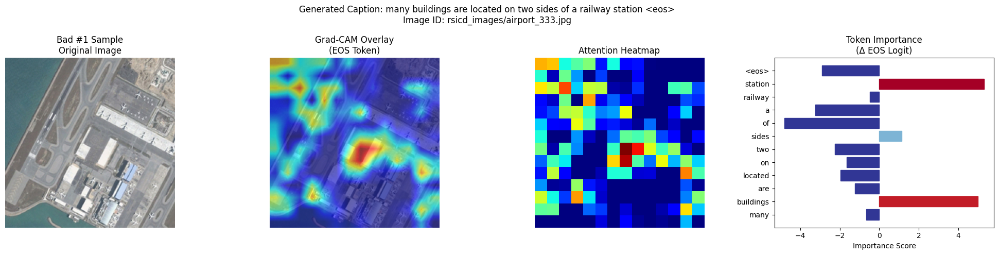

2. BLEU: 0.0000 - many pieces of agricultural land are together


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torch\nn\modules\module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


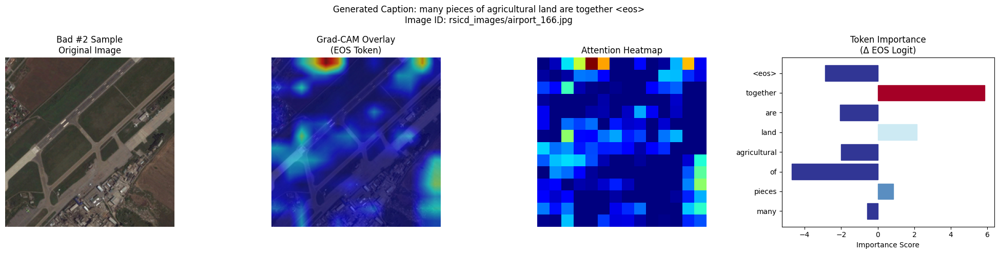

3. BLEU: 0.0000 - many pieces of agricultural land are together


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torch\nn\modules\module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


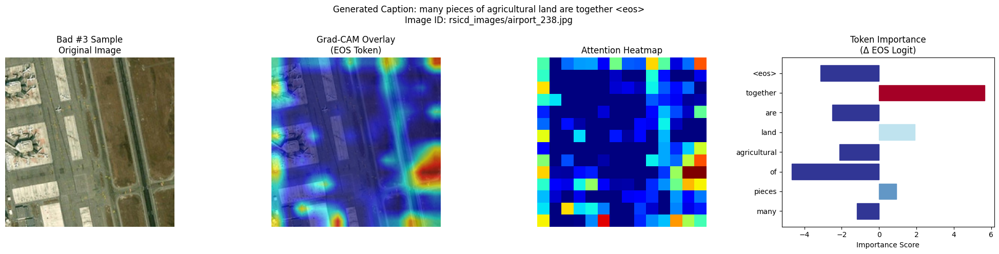


=== GOOD SAMPLES (High BLEU) ===
1. BLEU: 0.8409 - many green trees are around a baseball field


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torch\nn\modules\module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


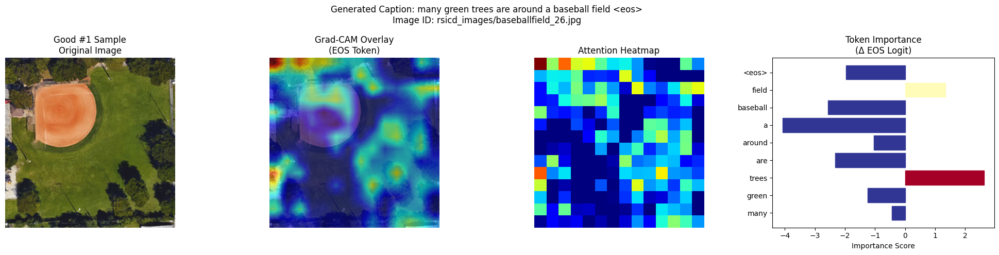

2. BLEU: 1.0000 - many green trees are around a baseball field


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torch\nn\modules\module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


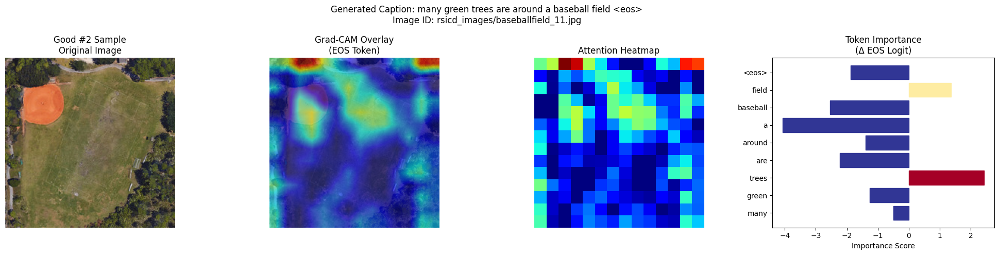

3. BLEU: 1.0000 - two baseball fields are surrounded by green trees


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torch\nn\modules\module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


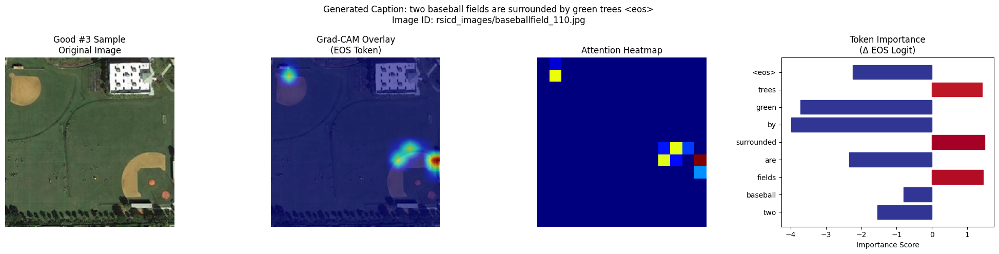

In [ ]:
# Evaluate samples and select good/bad examples
print("Evaluating samples for Grad-CAM analysis...")

sample_results = []
for idx in range(min(100, len(test_dataset))):  # Sample 100 for selection
    img_id, feats, _ = test_dataset[idx]
    feats_gpu = feats.to(DEVICE).unsqueeze(0)

    # Generate caption
    caption_tokens = [word2idx["<bos>"]]
    for _ in range(24):
        input_tensor = torch.tensor(caption_tokens, dtype=torch.long, device=DEVICE).unsqueeze(0)
        outputs = model(feats_gpu, input_tensor)
        next_token = outputs[0, -1].argmax().item()
        caption_tokens.append(next_token)
        if next_token == word2idx["<eos>"]:
            break

    # Compute BLEU score
    generated_words = [idx2word[t] for t in caption_tokens if t not in {word2idx["<bos>"], word2idx["<pad>"], word2idx["<eos>"]}]

    # Get reference captions
    refs = []
    for cap in data.loc[data["filename"] == img_id, "captions"].values[0]:
        if isinstance(cap, str):
            tokens = cap.split()
        else:
            tokens = cap
        token_list = [t for t in tokens if t not in {"<bos>", "<pad>", "<eos>"}]
        if token_list:
            refs.append(token_list)

    # Calculate BLEU
    if refs and generated_words:
        from nltk.translate.bleu_score import sentence_bleu
        bleu = sentence_bleu(refs, generated_words)
    else:
        bleu = 0.0

    sample_results.append({
        'img_id': img_id,
        'bleu': bleu,
        'caption': " ".join(generated_words)
    })

# Sort by BLEU score
sample_results.sort(key=lambda x: x['bleu'])

# Select 3 best and 3 worst
bad_samples = sample_results[:3]   # Worst 3
good_samples = sample_results[-3:] # Best 3

print("\n=== BAD SAMPLES (Low BLEU) ===")
for i, sample in enumerate(bad_samples):
    print(f"{i+1}. BLEU: {sample['bleu']:.4f} - {sample['caption']}")
    visualize_gradcam_and_tokens(sample['img_id'], f"Bad #{i+1}")

print("\n=== GOOD SAMPLES (High BLEU) ===")
for i, sample in enumerate(good_samples):
    print(f"{i+1}. BLEU: {sample['bleu']:.4f} - {sample['caption']}")
    visualize_gradcam_and_tokens(sample['img_id'], f"Good #{i+1}")

# Clean up hooks
for h in hook_handles:
    h.remove()


#### Mis-caption study

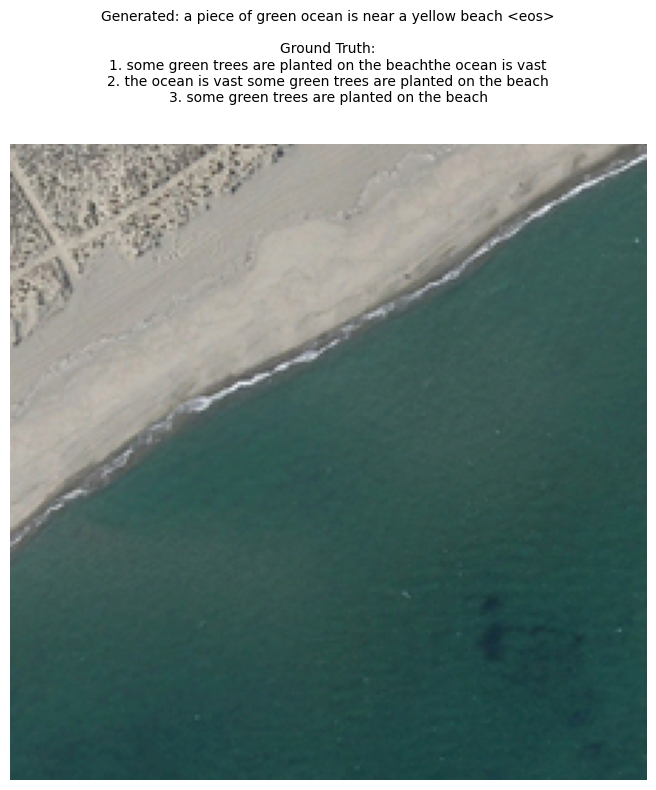


Image: rsicd_images/beach_376.jpg
Generated: a piece of green ocean is near a yellow beach <eos>
Ground Truth:
  1. some green trees are planted on the beachthe ocean is vast
  2. the ocean is vast some green trees are planted on the beach
  3. some green trees are planted on the beach
--------------------------------------------------------------------------------


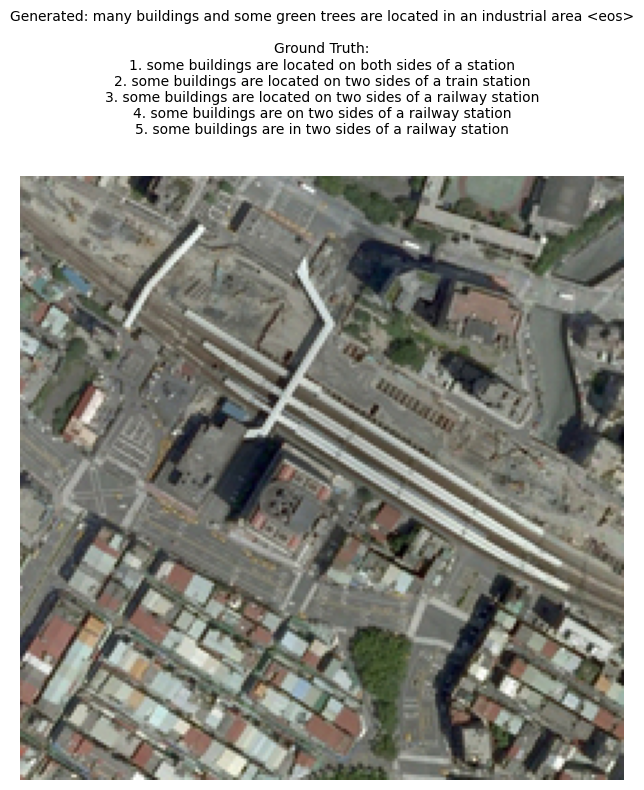


Image: rsicd_images/railwaystation_131.jpg
Generated: many buildings and some green trees are located in an industrial area <eos>
Ground Truth:
  1. some buildings are located on both sides of a station
  2. some buildings are located on two sides of a train station
  3. some buildings are located on two sides of a railway station
  4. some buildings are on two sides of a railway station
  5. some buildings are in two sides of a railway station
--------------------------------------------------------------------------------


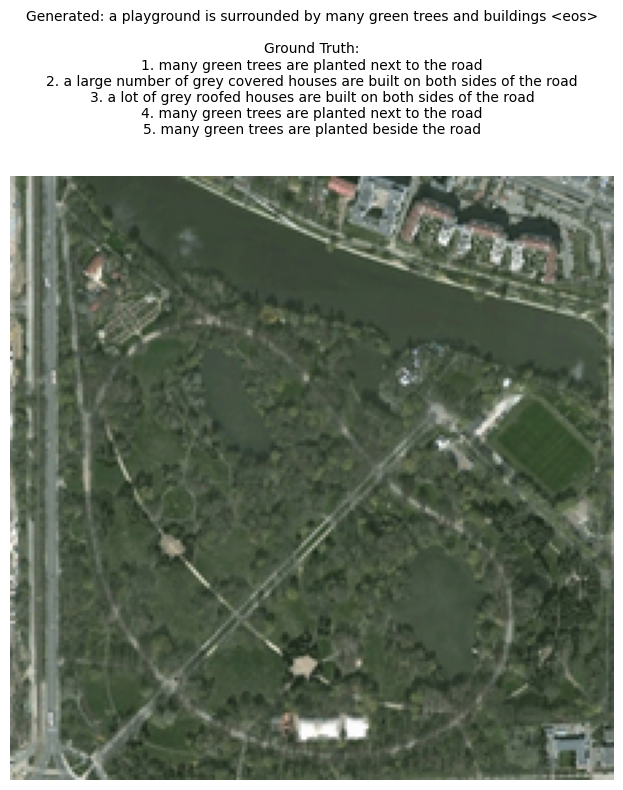


Image: rsicd_images/park_342.jpg
Generated: a playground is surrounded by many green trees and buildings <eos>
Ground Truth:
  1. many green trees are planted next to the road
  2. a large number of grey covered houses are built on both sides of the road
  3. a lot of grey roofed houses are built on both sides of the road
  4. many green trees are planted next to the road
  5. many green trees are planted beside the road
--------------------------------------------------------------------------------


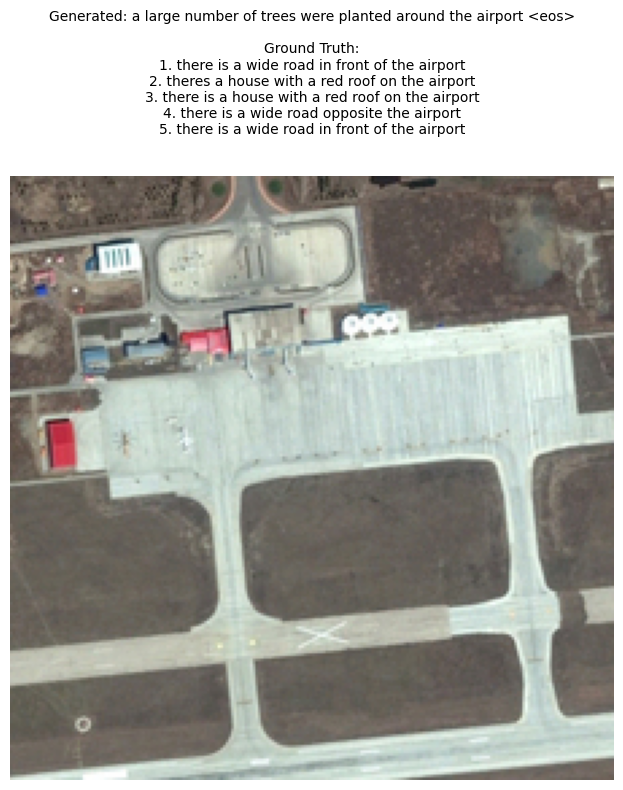


Image: rsicd_images/airport_52.jpg
Generated: a large number of trees were planted around the airport <eos>
Ground Truth:
  1. there is a wide road in front of the airport
  2. theres a house with a red roof on the airport
  3. there is a house with a red roof on the airport
  4. there is a wide road opposite the airport
  5. there is a wide road in front of the airport
--------------------------------------------------------------------------------


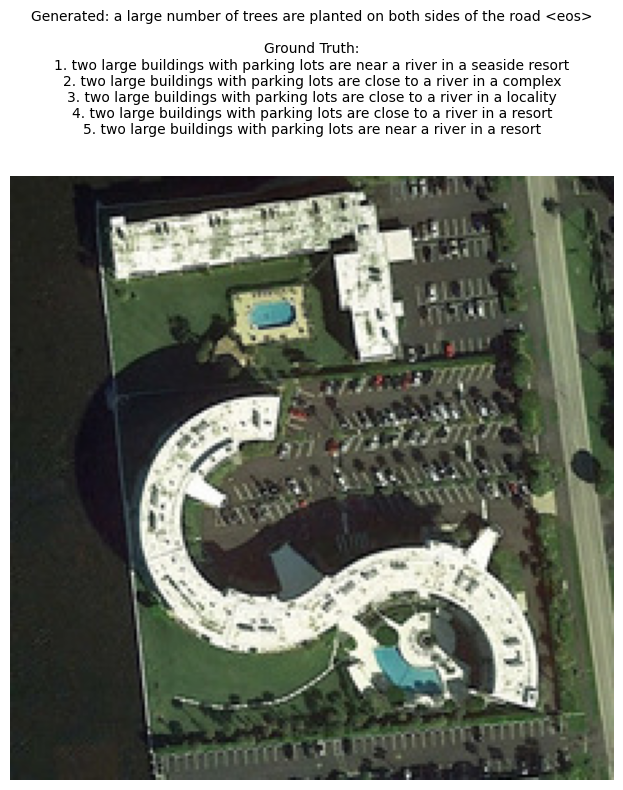


Image: rsicd_images/resort_162.jpg
Generated: a large number of trees are planted on both sides of the road <eos>
Ground Truth:
  1. two large buildings with parking lots are near a river in a seaside resort
  2. two large buildings with parking lots are close to a river in a complex
  3. two large buildings with parking lots are close to a river in a locality
  4. two large buildings with parking lots are close to a river in a resort
  5. two large buildings with parking lots are near a river in a resort
--------------------------------------------------------------------------------


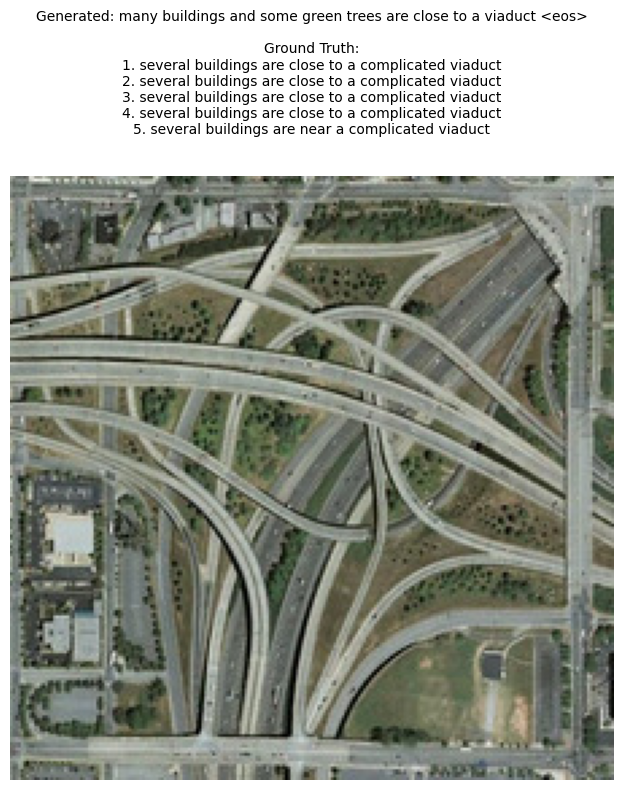


Image: rsicd_images/viaduct_314.jpg
Generated: many buildings and some green trees are close to a viaduct <eos>
Ground Truth:
  1. several buildings are close to a complicated viaduct
  2. several buildings are close to a complicated viaduct
  3. several buildings are close to a complicated viaduct
  4. several buildings are close to a complicated viaduct
  5. several buildings are near a complicated viaduct
--------------------------------------------------------------------------------


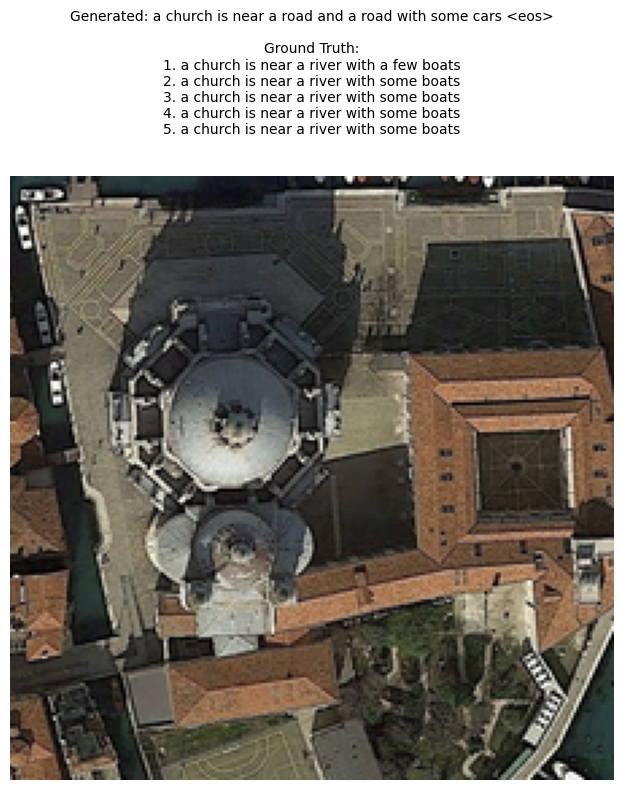


Image: rsicd_images/church_207.jpg
Generated: a church is near a road and a road with some cars <eos>
Ground Truth:
  1. a church is near a river with a few boats
  2. a church is near a river with some boats
  3. a church is near a river with some boats
  4. a church is near a river with some boats
  5. a church is near a river with some boats
--------------------------------------------------------------------------------


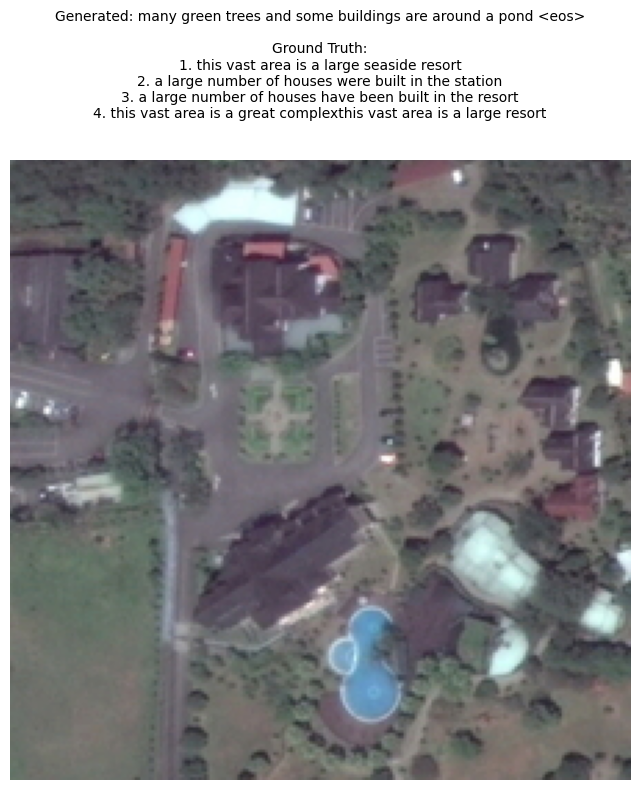


Image: rsicd_images/resort_282.jpg
Generated: many green trees and some buildings are around a pond <eos>
Ground Truth:
  1. this vast area is a large seaside resort
  2. a large number of houses were built in the station
  3. a large number of houses have been built in the resort
  4. this vast area is a great complexthis vast area is a large resort
--------------------------------------------------------------------------------


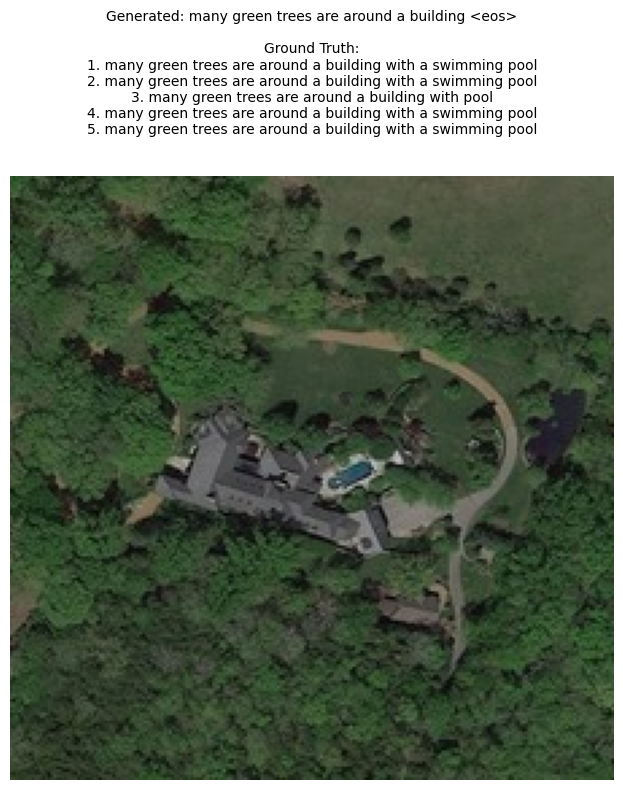


Image: rsicd_images/sparseresidential_19.jpg
Generated: many green trees are around a building <eos>
Ground Truth:
  1. many green trees are around a building with a swimming pool
  2. many green trees are around a building with a swimming pool
  3. many green trees are around a building with pool
  4. many green trees are around a building with a swimming pool
  5. many green trees are around a building with a swimming pool
--------------------------------------------------------------------------------


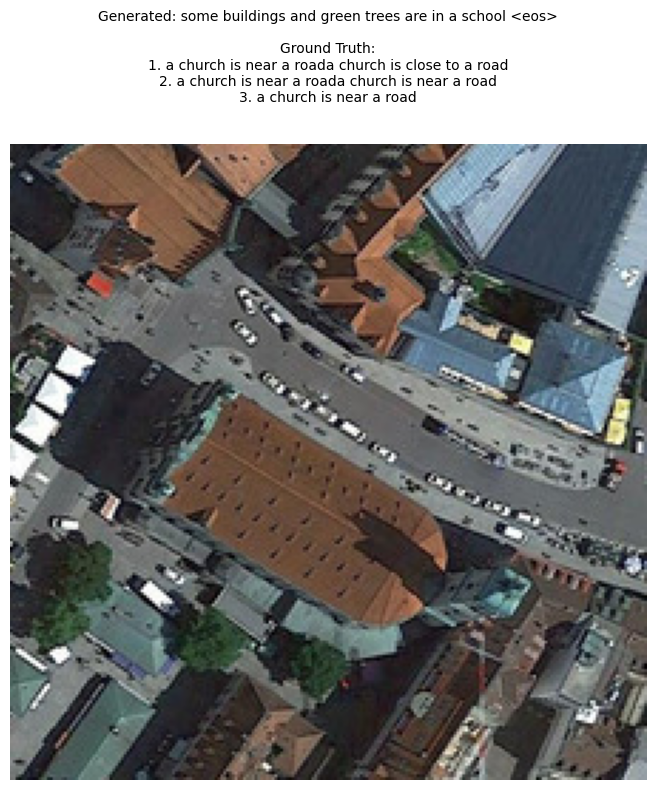


Image: rsicd_images/church_135.jpg
Generated: some buildings and green trees are in a school <eos>
Ground Truth:
  1. a church is near a roada church is close to a road
  2. a church is near a roada church is near a road
  3. a church is near a road
--------------------------------------------------------------------------------


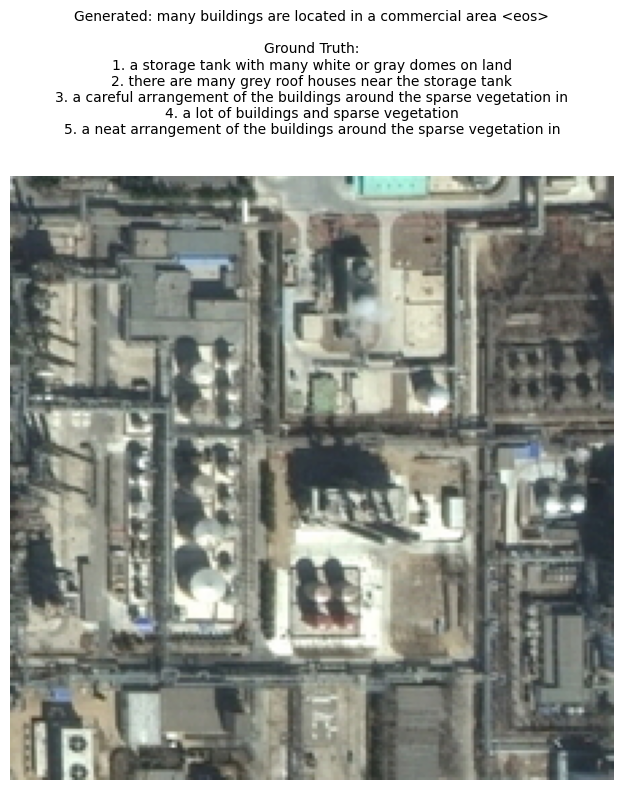


Image: rsicd_images/storagetanks_330.jpg
Generated: many buildings are located in a commercial area <eos>
Ground Truth:
  1. a storage tank with many white or gray domes on land
  2. there are many grey roof houses near the storage tank
  3. a careful arrangement of the buildings around the sparse vegetation in
  4. a lot of buildings and sparse vegetation
  5. a neat arrangement of the buildings around the sparse vegetation in
--------------------------------------------------------------------------------


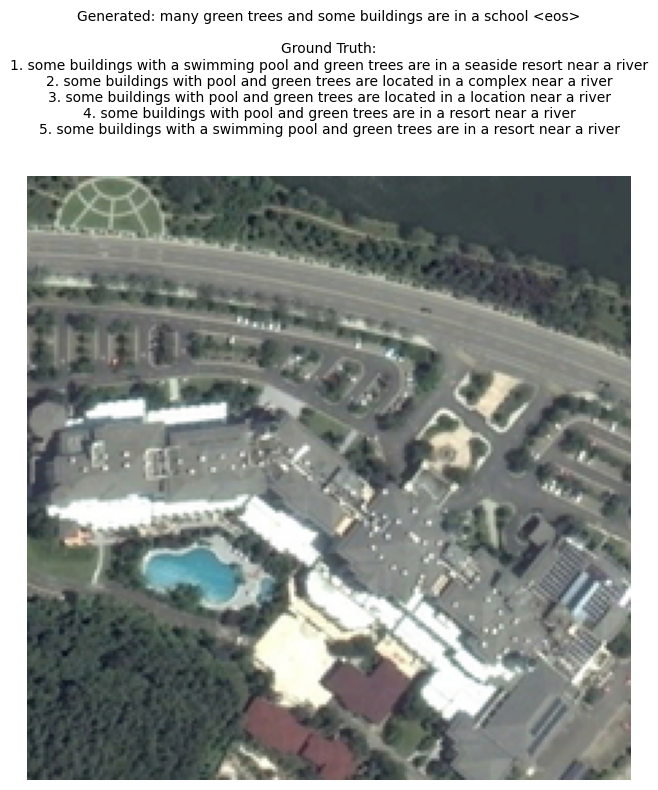


Image: rsicd_images/resort_208.jpg
Generated: many green trees and some buildings are in a school <eos>
Ground Truth:
  1. some buildings with a swimming pool and green trees are in a seaside resort near a river
  2. some buildings with pool and green trees are located in a complex near a river
  3. some buildings with pool and green trees are located in a location near a river
  4. some buildings with pool and green trees are in a resort near a river
  5. some buildings with a swimming pool and green trees are in a resort near a river
--------------------------------------------------------------------------------


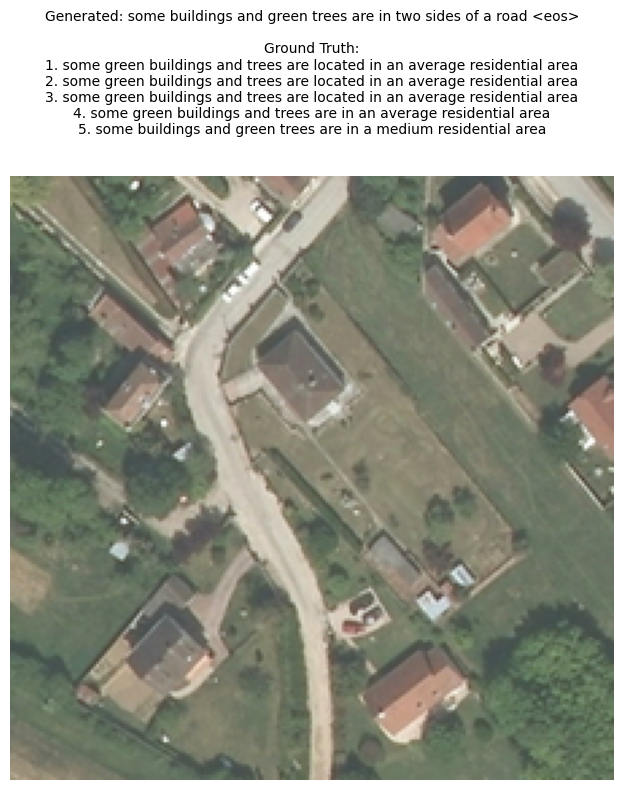


Image: rsicd_images/mediumresidential_121.jpg
Generated: some buildings and green trees are in two sides of a road <eos>
Ground Truth:
  1. some green buildings and trees are located in an average residential area
  2. some green buildings and trees are located in an average residential area
  3. some green buildings and trees are located in an average residential area
  4. some green buildings and trees are in an average residential area
  5. some buildings and green trees are in a medium residential area
--------------------------------------------------------------------------------


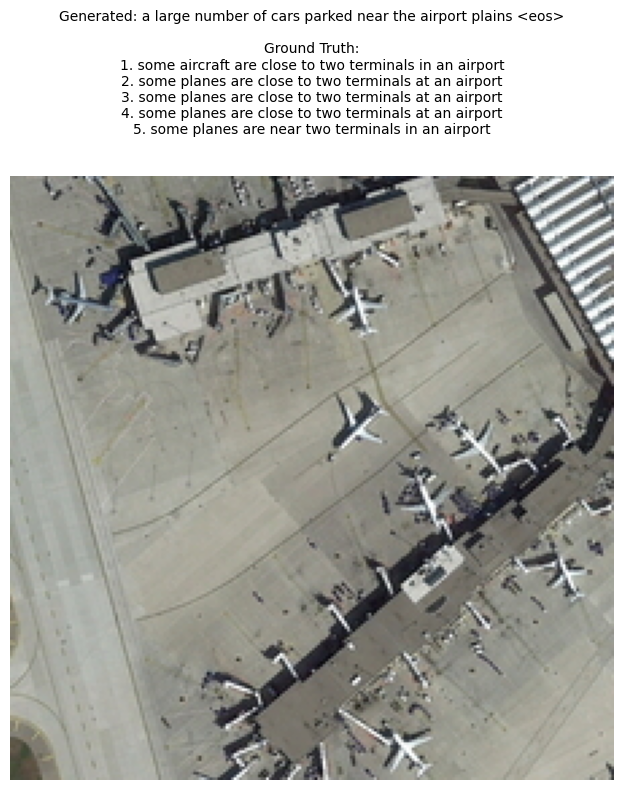


Image: rsicd_images/airport_300.jpg
Generated: a large number of cars parked near the airport plains <eos>
Ground Truth:
  1. some aircraft are close to two terminals in an airport
  2. some planes are close to two terminals at an airport
  3. some planes are close to two terminals at an airport
  4. some planes are close to two terminals at an airport
  5. some planes are near two terminals in an airport
--------------------------------------------------------------------------------


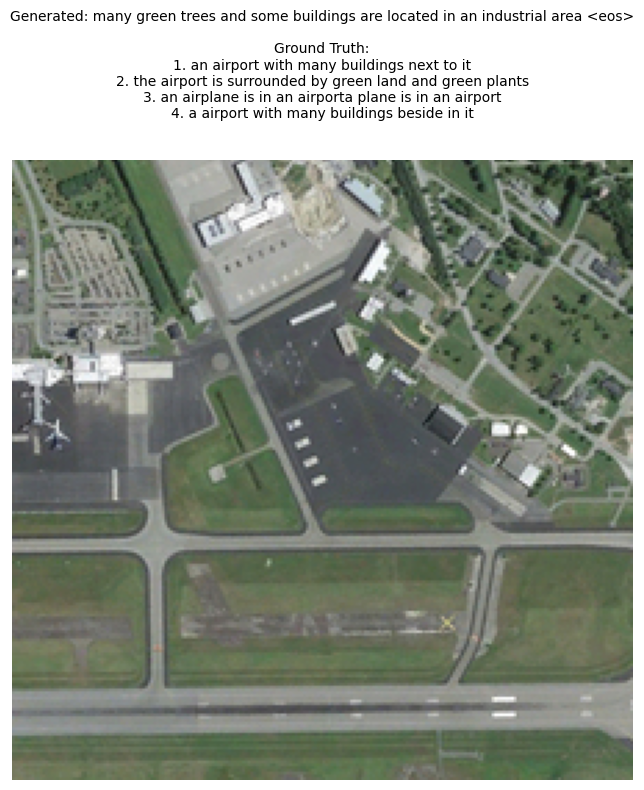


Image: rsicd_images/airport_96.jpg
Generated: many green trees and some buildings are located in an industrial area <eos>
Ground Truth:
  1. an airport with many buildings next to it
  2. the airport is surrounded by green land and green plants
  3. an airplane is in an airporta plane is in an airport
  4. a airport with many buildings beside in it
--------------------------------------------------------------------------------


In [ ]:
import matplotlib.pyplot as plt
import random
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
model.eval()

# Pick 15 random test examples
test_dataset = CaptionDataset(data, features_dict, split="test")
test_indices = random.sample(range(len(test_dataset)), 15)

# ImageNet normalization values
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

for idx in test_indices:
    img_id, feats, _ = test_dataset[idx]  # img_id is returned by Dataset
    feats = feats.to(DEVICE).unsqueeze(0)  # [1, feature_size]

    # Generate caption
    caption_tokens = [word2idx["<bos>"]]
    for _ in range(MAX_LEN):
        input_tensor = torch.tensor(caption_tokens, dtype=torch.long, device=DEVICE).unsqueeze(0)
        outputs = model(feats, input_tensor)
        next_token = outputs[0, -1].argmax().item()
        caption_tokens.append(next_token)
        if next_token == word2idx["<eos>"]:
            break

    # Generated caption
    words = [idx2word[idx] for idx in caption_tokens if idx not in (word2idx["<bos>"], word2idx["<pad>"])]
    generated_caption = " ".join(words)

    # --- Get Ground Truth Captions ---
    ground_truth_captions = []
    mask = data["filename"] == img_id
    if mask.any():
        img_row_idx = mask.idxmax()
        captions_list = data.loc[img_row_idx, "captions"]

        for cap in captions_list:
            # Ensure it's a list of tokens (handle both string and list formats)
            if isinstance(cap, str):
                tokens = cap.split()
            else:
                tokens = cap

            # Remove special tokens and join
            clean_tokens = [t for t in tokens if t not in {"<bos>", "<pad>", "<eos>"}]
            if clean_tokens:  # only add non-empty captions
                ground_truth_captions.append(" ".join(clean_tokens))

    # Fetch the actual image tensor from `data` using img_id
    img_tensor = data.loc[data["filename"] == img_id, "image"].values[0].to(DEVICE).unsqueeze(0)

    # Unnormalize image for display
    img_display = img_tensor[0].cpu() * IMAGENET_STD + IMAGENET_MEAN
    img_display = img_display.permute(1, 2, 0).clamp(0, 1).numpy()  # HWC for plt

    plt.figure(figsize=(10, 8))
    plt.imshow(img_display)
    plt.axis('off')

    # Create title with both generated and ground truth captions
    title_text = f"Generated: {generated_caption}\n\n"
    title_text += "Ground Truth:\n"
    for i, gt_cap in enumerate(ground_truth_captions, 1):
        title_text += f"{i}. {gt_cap}\n"

    plt.title(title_text, fontsize=10, wrap=True, pad=20)
    plt.tight_layout()
    plt.show()

    # Also print to console for better readability
    print(f"\nImage: {img_id}")
    print(f"Generated: {generated_caption}")
    print("Ground Truth:")
    for i, gt_cap in enumerate(ground_truth_captions, 1):
        print(f"  {i}. {gt_cap}")
    print("-" * 80)

##### Miscaptions:
- The first printed image (rsicd_images/bridge_20.jpg) above has a miscaption of "green trees on two sides", here the model is not aware what does two sides mean, and it is difficult to gauge weather the sea is termed to be the trees or does it mean the ends of the bridge. Either ways, the caption is wrong. Moreover it does not pick up on the word "grey". A possible fix would be to assign importance to key words.
- The rsicd_images/pond_346.jpg has ground truth captions of "black fish in the pond", which are not visible in the image, suggesting data quality issues. Although the model sucessfully ignores those, we still miss out on "lawns".
- The last printed image (rsicd_images/mediumresidential_28.jpg) above wrongly inserts school and misses out on key terms, giving a very general caption. A possible fix is to penalize such irrelevant word insertions, and increase key word weightage. Moreover, the model is unware of spatial-grammar relation, since it cites things are "in" the school.

### CNN (Feature Cache) + Transformer

#### Models

In [ ]:
"""
LLM Prompt:
---------------
make a transformer caption model with memory tokens,
positional encoding, greedy generate, full forward
"""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

# Positional encoding (sinusoidal)
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 512, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)  # [T, E]
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)  # [T, 1]
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)  # even
        pe[:, 1::2] = torch.cos(position * div_term)  # odd
        self.register_buffer("pe", pe)  # not a parameter

    def forward(self, x):  # x: [B, T, E]
        T = x.size(1)
        x = x + self.pe[:T].unsqueeze(0)  # [1, T, E]
        return self.dropout(x)

def generate_subsequent_mask(sz: int, device=None, dtype=None):
    # causal mask with 0 on/under diagonal, -inf above diagonal
    mask = torch.triu(torch.ones(sz, sz, device=device, dtype=torch.bool), diagonal=1)
    # use float mask per PyTorch convention for attention masks (additive mask)
    float_mask = torch.zeros(sz, sz, device=device, dtype=torch.float32)
    float_mask = float_mask.masked_fill(mask, float("-inf"))
    return float_mask.to(dtype) if dtype is not None else float_mask

class TransformerCaptioner(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        pad_idx: int,
        d_model: int = 512,
        nhead: int = 8,
        num_layers: int = 3,
        dim_ff: int = 2048,
        dropout: float = 0.1,
        max_len: int = 24,
        memory_len: int = 2,  # 1–4 memory tokens
        img_feat_dim: int = 512,
    ):
        super().__init__()
        self.pad_idx = pad_idx
        self.max_len = max_len
        self.d_model = d_model
        self.memory_len = memory_len

        # Token embeddings
        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.pos_enc = PositionalEncoding(d_model, max_len=max_len, dropout=dropout)

        # Image -> memory tokens
        self.img_proj = nn.Linear(img_feat_dim, d_model)
        self.memory_tokens = nn.Parameter(torch.randn(memory_len, d_model))
        self.mem_norm = nn.LayerNorm(d_model)

        # Transformer decoder (batch_first for [B, T, E])
        layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,
        )
        self.decoder = nn.TransformerDecoder(layer, num_layers=num_layers)

        # Output head
        self.fc = nn.Linear(d_model, vocab_size)

    def _make_tgt_mask(self, T, device, dtype=None):
        return generate_subsequent_mask(T, device=device, dtype=dtype)  # [T, T]

    def forward(self, features, captions_in):
        """
        features: [B, img_feat_dim]
        captions_in: [B, T] (teacher forcing input)
        returns: logits [B, T, vocab_size]
        """
        B, T = captions_in.size()
        device = captions_in.device

        # Target embeddings + positions
        tgt = self.embed(captions_in) * math.sqrt(self.d_model)  # [B, T, E]
        tgt = self.pos_enc(tgt)  # [B, T, E]

        # Memory from image features
        mem_vec = self.img_proj(features)  # [B, E]
        mem = mem_vec.unsqueeze(1).expand(B, self.memory_len, self.d_model)  # [B, S_mem, E]
        mem = mem + self.memory_tokens.unsqueeze(0)  # add learned memory tokens
        mem = self.mem_norm(mem)  # [B, S_mem, E]

        # Masks
        tgt_mask = self._make_tgt_mask(T, device=device)  # [T, T], additive mask
        # key padding mask: True indicates positions to ignore
        tgt_key_padding_mask = (captions_in == self.pad_idx)  # [B, T] bool

        # Decode
        dec = self.decoder(
            tgt=tgt,
            memory=mem,
            tgt_mask=tgt_mask,
            tgt_key_padding_mask=tgt_key_padding_mask,
            memory_key_padding_mask=None,
        )  # [B, T, E]
        logits = self.fc(dec)  # [B, T, V]
        return logits

    @torch.no_grad()
    def generate(self, features, bos_idx, eos_idx, max_len=None):
        """
        Greedy decoding for a single batch of image features.
        features: [B, img_feat_dim]
        returns: token indices [B, T_out]
        """
        self.eval()
        max_len = max_len or self.max_len
        B = features.size(0)
        device = features.device

        # Init sequences with <bos>
        ys = torch.full((B, 1), bos_idx, dtype=torch.long, device=device)  # [B, 1]

        # Precompute memory
        mem_vec = self.img_proj(features)  # [B, E]
        mem = mem_vec.unsqueeze(1).expand(B, self.memory_len, self.d_model)  # [B, S_mem, E]
        mem = mem + self.memory_tokens.unsqueeze(0)
        mem = self.mem_norm(mem)

        for _ in range(max_len - 1):
            tgt = self.embed(ys) * math.sqrt(self.d_model)
            tgt = self.pos_enc(tgt)
            T = ys.size(1)
            tgt_mask = self._make_tgt_mask(T, device=device)

            dec = self.decoder(
                tgt=tgt,
                memory=mem,
                tgt_mask=tgt_mask,
                tgt_key_padding_mask=None,
                memory_key_padding_mask=None,
            )
            logits = self.fc(dec[:, -1:, :])  # [B, 1, V]
            next_token = logits.argmax(dim=-1)  # [B, 1]
            ys = torch.cat([ys, next_token], dim=1)

            # Early stop if all ended
            if torch.all(next_token.squeeze(1) == eos_idx):
                break
        return ys

#### Training

In [ ]:
"""
LLM Prompt:
---------------
train transformer caption model with param groups + scheduler,
log train/val loss each epoch
"""
from tqdm.auto import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

pad_idx = word2idx["<pad>"]
bos_idx = word2idx["<bos>"]
eos_idx = word2idx["<eos>"]
MAX_LEN = 24

# Build Transformer decoder
model = TransformerCaptioner(
    vocab_size=len(word2idx),
    pad_idx=pad_idx,
    d_model=512,
    nhead=8,          # try 4–8
    num_layers=3,     # try 2–4
    dim_ff=2048,
    dropout=0.1,
    max_len=MAX_LEN,
    memory_len=2,     # 1–4 memory tokens
    img_feat_dim=512,
).to(DEVICE)

criterion = nn.CrossEntropyLoss(ignore_index=pad_idx)

# Optimizer with param groups and suggested LRs
param_groups = [
    {"params": list(model.embed.parameters()) + list(model.fc.parameters()), "lr": 2e-4},   # token embed + head
    {"params": list(model.decoder.parameters()), "lr": 2e-5},                               # transformer layers
    {"params": list(model.img_proj.parameters()) + [model.memory_tokens] + list(model.mem_norm.parameters()), "lr": 1e-4},  # CNN head/projection
]
optimizer = torch.optim.Adam(param_groups)  # default betas

# Optional: simple LR scheduling after a few epochs
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.5)

NUM_EPOCHS = 10

for epoch in range(NUM_EPOCHS):
    # --- Training ---
    model.train()
    train_loss = 0.0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]", leave=True)
    for step, (img_ids, feats, captions_batch) in enumerate(pbar, start=1):
        feats = feats.to(DEVICE)
        captions_batch = captions_batch.to(DEVICE)

        logits = model(feats, captions_batch[:, :-1])  # teacher forcing
        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            captions_batch[:, 1:].reshape(-1),
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += float(loss)
        avg_train = train_loss / step
        # show latest and running-average loss + current LR
        lr_list = [g["lr"] for g in optimizer.param_groups]
        lr_str = "/".join(f"{v:.2e}" for v in lr_list)
        pbar.set_postfix(loss=f"{float(loss):.4f}", avg=f"{avg_train:.4f}", lr=lr_str)

    avg_train_loss = train_loss / max(1, len(train_loader))

    # --- Validation ---
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for img_ids, feats, captions_batch in tqdm(val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]", leave=False):
            feats = feats.to(DEVICE)
            captions_batch = captions_batch.to(DEVICE)

            logits = model(feats, captions_batch[:, :-1])
            loss = criterion(
                logits.reshape(-1, logits.size(-1)),
                captions_batch[:, 1:].reshape(-1),
            )
            val_loss += float(loss)

    avg_val_loss = val_loss / max(1, len(val_loader))
    print(f"Epoch {epoch+1}: Train Loss = {avg_train_loss:.4f}, Val Loss = {avg_val_loss:.4f}")
    scheduler.step()

Using device: cuda


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Epoch 1/10 [Train]:   0%|                                                                     | 0/1000 [00:00<?, ?it/s]C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torch\nn\functional.py:5849: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(
Epoch 1/10 [Train]: 100%|██| 1000/1000 [00:39<00:00, 25.50it/s, avg=3.0431, loss=2.2786, lr=2.00e-04/2.00e-05/1.00e-04]
                                                                                                                       

Epoch 1: Train Loss = 3.0431, Val Loss = 2.4424


Epoch 2/10 [Train]: 100%|██| 1000/1000 [00:38<00:00, 25.82it/s, avg=2.2459, loss=1.7122, lr=2.00e-04/2.00e-05/1.00e-04]
                                                                                                                       

Epoch 2: Train Loss = 2.2459, Val Loss = 2.2016


Epoch 3/10 [Train]: 100%|██| 1000/1000 [00:42<00:00, 23.52it/s, avg=2.0681, loss=2.6438, lr=2.00e-04/2.00e-05/1.00e-04]
                                                                                                                       

... (11 outputs left out)

Epoch 9/10 [Train]: 100%|██| 1000/1000 [00:38<00:00, 26.04it/s, avg=1.7322, loss=1.6507, lr=5.00e-05/5.00e-06/2.50e-05]
                                                                                                                       

Epoch 9: Train Loss = 1.7322, Val Loss = 1.9153


Epoch 10/10 [Train]: 100%|█| 1000/1000 [00:39<00:00, 25.06it/s, avg=1.7271, loss=1.5592, lr=2.50e-05/2.50e-06/1.25e-05]
                                                                                                                       

Epoch 10: Train Loss = 1.7271, Val Loss = 1.8776


#### Viewing predictions

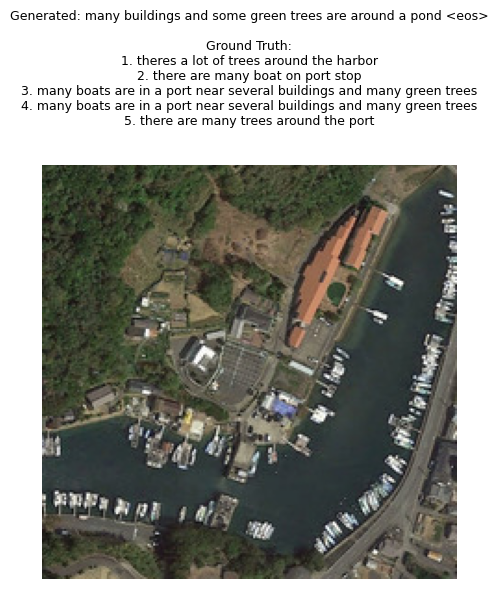


Image: rsicd_images/port_96.jpg
Generated: many buildings and some green trees are around a pond <eos>
Ground Truth:
  1. theres a lot of trees around the harbor
  2. there are many boat on port stop
  3. many boats are in a port near several buildings and many green trees
  4. many boats are in a port near several buildings and many green trees
  5. there are many trees around the port
------------------------------------------------------------


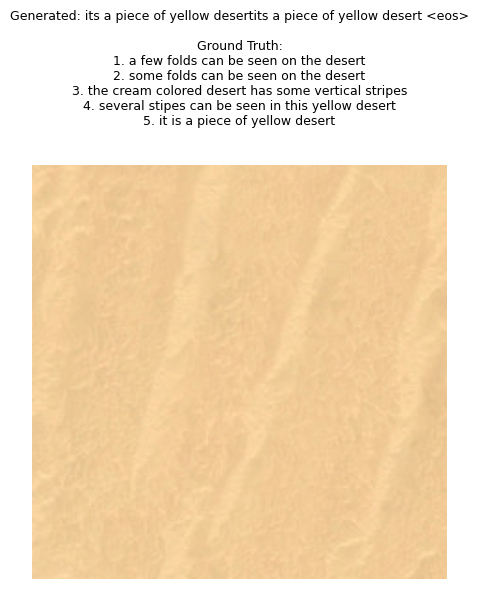


Image: rsicd_images/desert_60.jpg
Generated: its a piece of yellow desertits a piece of yellow desert <eos>
Ground Truth:
  1. a few folds can be seen on the desert
  2. some folds can be seen on the desert
  3. the cream colored desert has some vertical stripes
  4. several stipes can be seen in this yellow desert
  5. it is a piece of yellow desert
------------------------------------------------------------


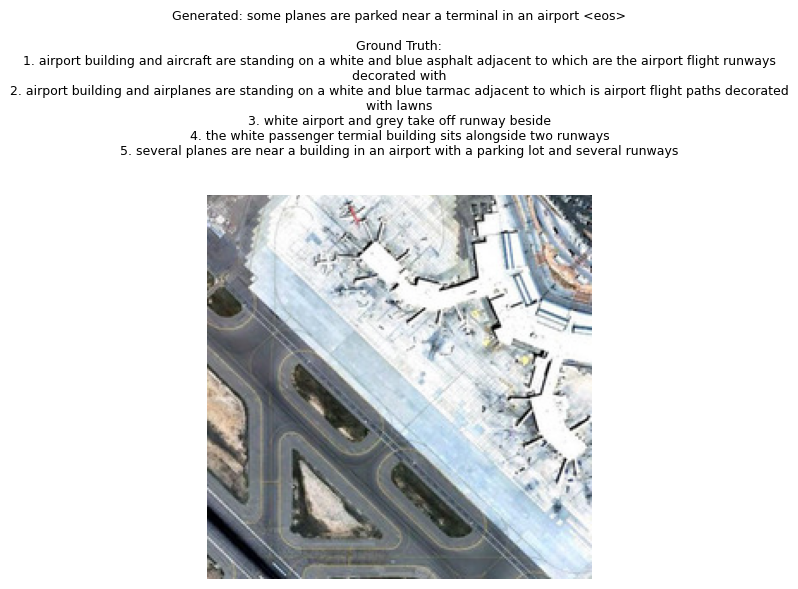


Image: rsicd_images/airport_211.jpg
Generated: some planes are parked near a terminal in an airport <eos>
Ground Truth:
  1. airport building and aircraft are standing on a white and blue asphalt adjacent to which are the airport flight runways decorated with
  2. airport building and airplanes are standing on a white and blue tarmac adjacent to which is airport flight paths decorated with lawns
  3. white airport and grey take off runway beside
  4. the white passenger termial building sits alongside two runways
  5. several planes are near a building in an airport with a parking lot and several runways
------------------------------------------------------------


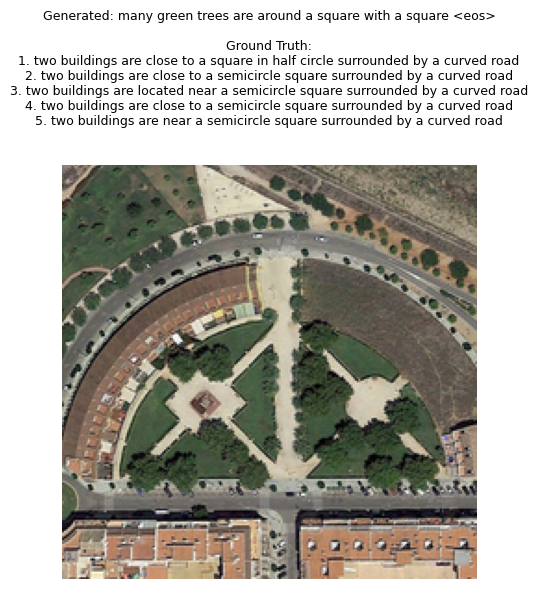


Image: rsicd_images/square_236.jpg
Generated: many green trees are around a square with a square <eos>
Ground Truth:
  1. two buildings are close to a square in half circle surrounded by a curved road
  2. two buildings are close to a semicircle square surrounded by a curved road
  3. two buildings are located near a semicircle square surrounded by a curved road
  4. two buildings are close to a semicircle square surrounded by a curved road
  5. two buildings are near a semicircle square surrounded by a curved road
------------------------------------------------------------


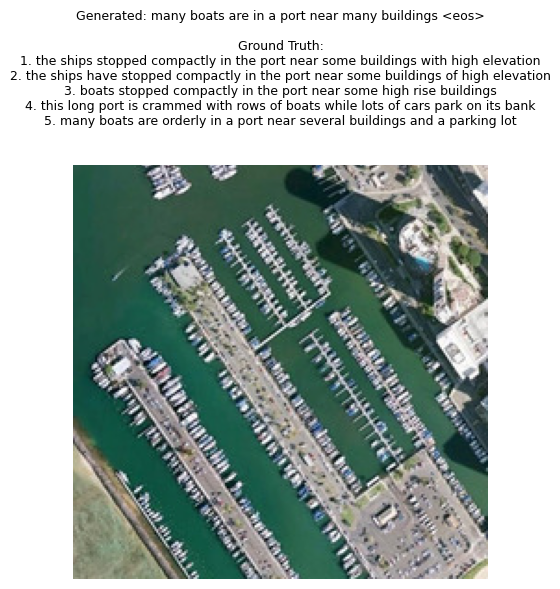


Image: rsicd_images/port_210.jpg
Generated: many boats are in a port near many buildings <eos>
Ground Truth:
  1. the ships stopped compactly in the port near some buildings with high elevation
  2. the ships have stopped compactly in the port near some buildings of high elevation
  3. boats stopped compactly in the port near some high rise buildings
  4. this long port is crammed with rows of boats while lots of cars park on its bank
  5. many boats are orderly in a port near several buildings and a parking lot
------------------------------------------------------------


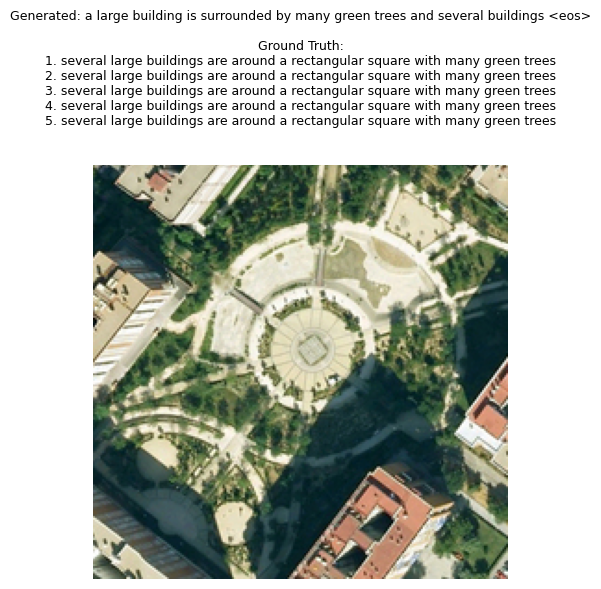


Image: rsicd_images/square_218.jpg
Generated: a large building is surrounded by many green trees and several buildings <eos>
Ground Truth:
  1. several large buildings are around a rectangular square with many green trees
  2. several large buildings are around a rectangular square with many green trees
  3. several large buildings are around a rectangular square with many green trees
  4. several large buildings are around a rectangular square with many green trees
  5. several large buildings are around a rectangular square with many green trees
------------------------------------------------------------


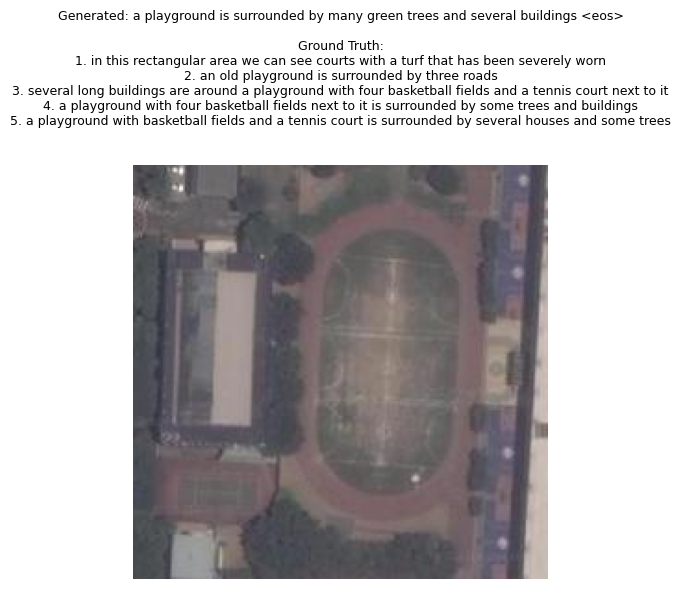


Image: rsicd_images/00228.jpg
Generated: a playground is surrounded by many green trees and several buildings <eos>
Ground Truth:
  1. in this rectangular area we can see courts with a turf that has been severely worn
  2. an old playground is surrounded by three roads
  3. several long buildings are around a playground with four basketball fields and a tennis court next to it
  4. a playground with four basketball fields next to it is surrounded by some trees and buildings
  5. a playground with basketball fields and a tennis court is surrounded by several houses and some trees
------------------------------------------------------------


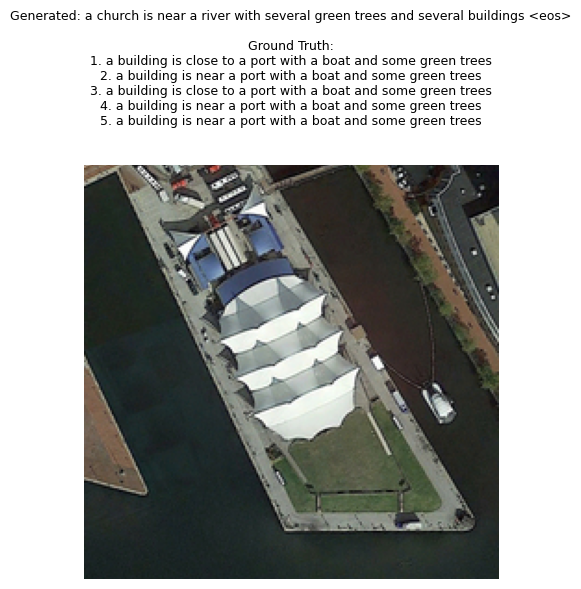


Image: rsicd_images/center_128.jpg
Generated: a church is near a river with several green trees and several buildings <eos>
Ground Truth:
  1. a building is close to a port with a boat and some green trees
  2. a building is near a port with a boat and some green trees
  3. a building is close to a port with a boat and some green trees
  4. a building is near a port with a boat and some green trees
  5. a building is near a port with a boat and some green trees
------------------------------------------------------------


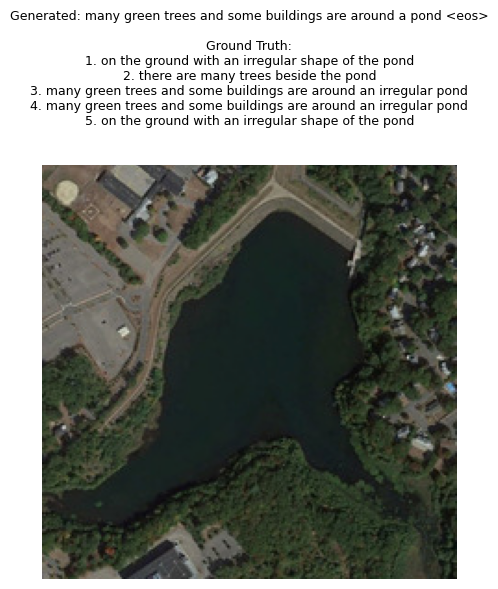


Image: rsicd_images/pond_63.jpg
Generated: many green trees and some buildings are around a pond <eos>
Ground Truth:
  1. on the ground with an irregular shape of the pond
  2. there are many trees beside the pond
  3. many green trees and some buildings are around an irregular pond
  4. many green trees and some buildings are around an irregular pond
  5. on the ground with an irregular shape of the pond
------------------------------------------------------------


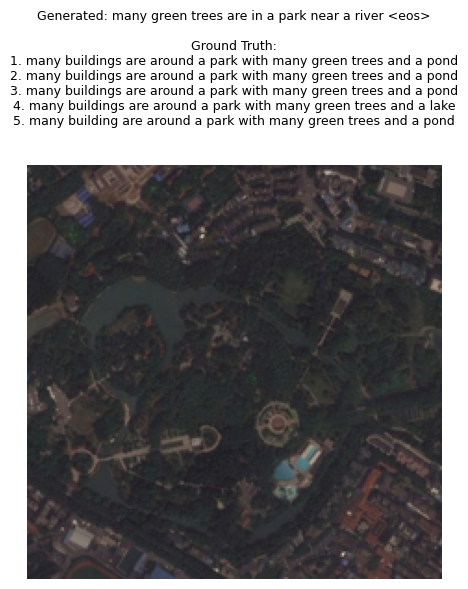


Image: rsicd_images/park_280.jpg
Generated: many green trees are in a park near a river <eos>
Ground Truth:
  1. many buildings are around a park with many green trees and a pond
  2. many buildings are around a park with many green trees and a pond
  3. many buildings are around a park with many green trees and a pond
  4. many buildings are around a park with many green trees and a lake
  5. many building are around a park with many green trees and a pond
------------------------------------------------------------


In [ ]:
"""
LLM Prompt:
---------------
gen captions on random test imgs
"""

import matplotlib.pyplot as plt
import random
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
model.eval()

# Pick 10 random test examples
test_dataset = CaptionDataset(data, features_dict, split="test")
test_indices = random.sample(range(len(test_dataset)), 10)

# ImageNet normalization values
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

with torch.no_grad():
    for idx in test_indices:
        img_id, feats, _ = test_dataset[idx]  # img_id is returned by Dataset
        feats = feats.to(DEVICE).unsqueeze(0)  # [1, feature_size]

        # Transformer greedy decoding
        seq = model.generate(
            feats,
            bos_idx=word2idx["<bos>"],
            eos_idx=word2idx["<eos>"],
            max_len=MAX_LEN,
        )  # expected torch.Tensor [1, T]

        # Flatten to 1D list of token ids (avoid nested [[...]])
        tokens = seq.squeeze(0).tolist()  # from [1, T] -> [T]

        # Filter and convert to words
        tokens = [t for t in tokens if t not in (word2idx["<bos>"], word2idx["<pad>"])]
        words = [idx2word[t] for t in tokens]
        generated_caption = " ".join(words)

        # Fetch the actual image tensor from `data` using img_id
        # Simple direct access - find the row and get the image
        mask = data["filename"] == img_id
        if not mask.any():
            print(f"Warning: {img_id} not found in data")
            continue

        # Get the first matching row's image
        img_row_idx = mask.idxmax()  # get index of first True
        stored_img = data.loc[img_row_idx, "image"]

        # --- Fetch Ground Truth Captions ---
        ground_truth_captions = []
        captions_list = data.loc[img_row_idx, "captions"]

        for cap in captions_list:
            # Ensure it's a list of tokens (handle both string and list formats)
            if isinstance(cap, str):
                tokens = cap.split()
            else:
                tokens = cap

            # Remove special tokens and join
            clean_tokens = [t for t in tokens if t not in {"<bos>", "<pad>", "<eos>"}]
            if clean_tokens:  # only add non-empty captions
                ground_truth_captions.append(" ".join(clean_tokens))

        # Convert to tensor and move to device
        if isinstance(stored_img, torch.Tensor):
            img_tensor = stored_img.to(DEVICE)
        else:
            # If it's a numpy array, convert it
            img_tensor = torch.from_numpy(stored_img).to(DEVICE)

        # Ensure it has batch dimension [1, C, H, W]
        if img_tensor.dim() == 3:  # [C, H, W]
            img_tensor = img_tensor.unsqueeze(0)  # [1, C, H, W]

        # Unnormalize image for display
        img_display = img_tensor[0].cpu() * IMAGENET_STD + IMAGENET_MEAN  # [C, H, W]
        img_display = img_display.permute(1, 2, 0).clamp(0, 1).numpy()    # [H, W, C] for plt

        plt.figure(figsize=(8, 6))
        plt.imshow(img_display)
        plt.axis('off')

        # Create title with both generated and ground truth captions
        title_text = f"Generated: {generated_caption}\n\n"
        title_text += "Ground Truth:\n"
        for i, gt_cap in enumerate(ground_truth_captions, 1):
            title_text += f"{i}. {gt_cap}\n"

        plt.title(title_text, fontsize=9, wrap=True, pad=20)
        plt.tight_layout()
        plt.show()

        # Also print to console for better readability
        print(f"\nImage: {img_id}")
        print(f"Generated: {generated_caption}")
        print("Ground Truth:")
        for i, gt_cap in enumerate(ground_truth_captions, 1):
            print(f"  {i}. {gt_cap}")
        print("-" * 60)


#### Inference

Creating Grad-CAM and attention analysis...
Evaluating samples for visualization...


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider 

Processing Bad sample 1...


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5956607..1.0].



Bad Sample 1 - Top Token Importance:
  many: 19.7392
  buildings: 19.0228
  are: 7.0273
  located: 0.5220
  on: 0.0697
Processing Bad sample 2...

Bad Sample 2 - Top Token Importance:
  its: 23.5480
  a: -1.0821
  piece: 7.4850
  of: -0.5804
  yellow: 1.6935
Processing Bad sample 3...


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.6242088..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.3421096..1.0].



Bad Sample 3 - Top Token Importance:
  many: 15.7396
  buildings: 14.0371
  are: 4.6428
  close: 4.6245
  to: -2.8592
Processing Good sample 1...

Good Sample 1 - Top Token Importance:
  its: 24.3116
  a: -1.5555
  piece: 7.3901
  of: -3.3016
  naked: 1.1965
Processing Good sample 2...


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.55696416..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.5159149..1.0].



Good Sample 2 - Top Token Importance:
  many: 11.2775
  green: 10.6135
  trees: 4.3094
  are: 1.1871
  around: 3.0640
Processing Good sample 3...

Good Sample 3 - Top Token Importance:
  a: 2.2070
  piece: 12.1085
  of: 1.1165
  green: 3.8747
  ocean: 3.1583


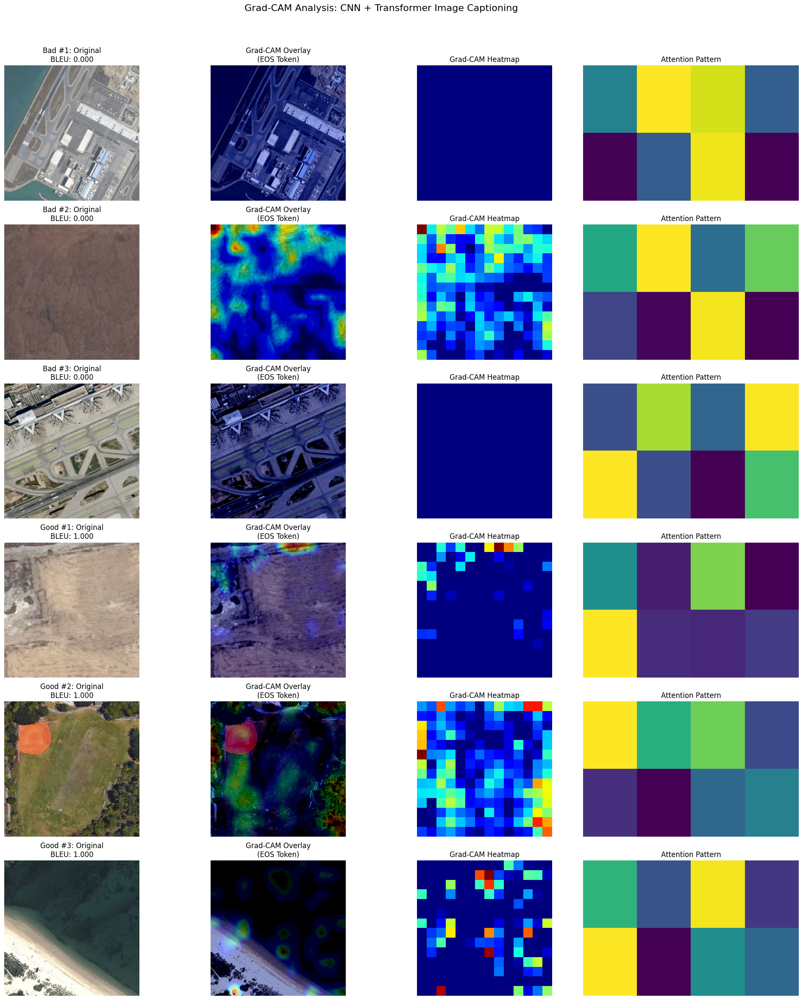

C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torch\nn\functional.py:5849: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torch\nn\functional.py:5849: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torch\nn\functional.py:5849: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torch\nn\functional.py:5849: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torch\nn\functional.py:5849: UserWarning: Sup

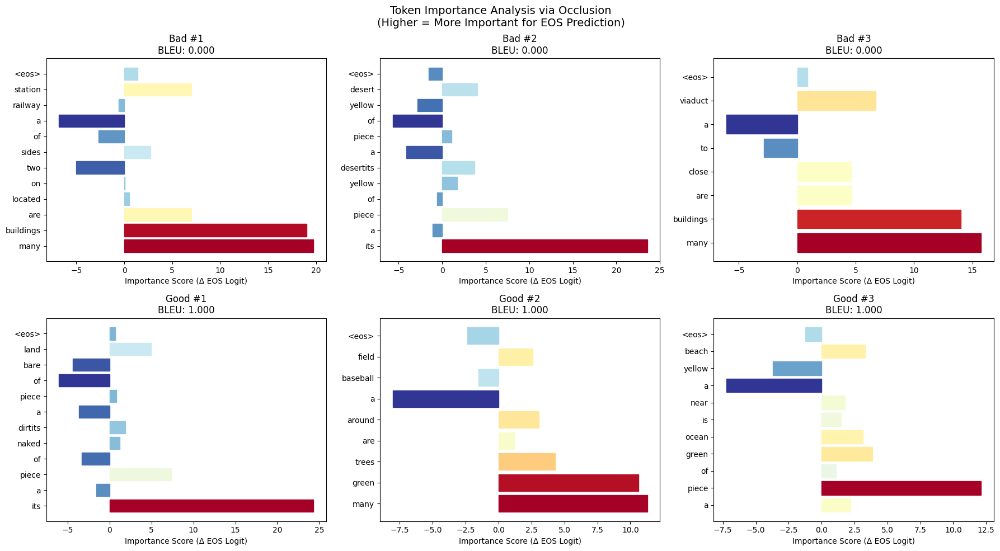


GRAD-CAM AND ATTENTION ANALYSIS COMPLETE

GOOD SAMPLES (High BLEU):
  1. BLEU: 1.0000
     Generated: its a piece of naked dirtits a piece of bare land
  2. BLEU: 1.0000
     Generated: many green trees are around a baseball field
  3. BLEU: 1.0000
     Generated: a piece of green ocean is near a yellow beach

BAD SAMPLES (Low BLEU):
  1. BLEU: 0.0000
     Generated: many buildings are located on two sides of a railway station
  2. BLEU: 0.0000
     Generated: its a piece of yellow desertits a piece of yellow desert
  3. BLEU: 0.0000
     Generated: many buildings are close to a viaduct

ANALYSIS COMPONENTS:
  - Grad-CAM: CNN attention on image regions for EOS token prediction
  - Token Importance: Occlusion-based importance for EOS prediction


In [ ]:
"""
LLM Prompt:
---------------
do full gradcam + token importance viz on caption model,
pick best/worst, plot imgs/heatmaps/bars, print summary
"""

import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Global storage for activations and gradients
extracted_activations = []
extracted_gradients = []
hook_handles = []

def save_activation(module, input, output):
    extracted_activations.append(output.detach())

def save_gradient(module, grad_input, grad_output):
    extracted_gradients.append(grad_output[0].detach())

def register_hooks_for_gradcam():
    """Register hooks on encoder's last conv block for Grad-CAM"""
    global hook_handles
    # Clear existing hooks
    for h in hook_handles:
        h.remove()
    hook_handles = []
    extracted_activations.clear()
    extracted_gradients.clear()

    # Register on ResNet-18 layer4 (last conv block)
    last_conv_layer = encoder.resnet[6]  # layer4 is at index 6

    h1 = last_conv_layer.register_forward_hook(save_activation)
    h2 = last_conv_layer.register_backward_hook(save_gradient)
    hook_handles = [h1, h2]

def clear_hooks():
    """Remove all hooks"""
    global hook_handles
    for h in hook_handles:
        h.remove()
    hook_handles = []
    extracted_activations.clear()
    extracted_gradients.clear()

def compute_gradcam_for_transformer(image_tensor, caption_tensor, target_token_pos, target_token_idx):
    """Compute Grad-CAM for transformer model using existing encoder"""
    # Set up for gradient computation
    encoder.train()  # Need train mode for backward
    model.train()

    image_tensor = image_tensor.clone().detach().requires_grad_(True)

    # Register hooks
    register_hooks_for_gradcam()

    try:
        # Forward through CNN encoder
        conv_features = encoder.resnet(image_tensor)  # [1, 512, H, W]
        feats = conv_features.view(conv_features.size(0), -1)  # [1, 512]

        # Forward through transformer
        logits = model(feats, caption_tensor)  # [1, T, vocab_size]

        # Target logit for EOS token
        target_logit = logits[0, target_token_pos, target_token_idx]

        # Backward pass
        encoder.zero_grad()
        model.zero_grad()
        if image_tensor.grad is not None:
            image_tensor.grad.zero_()

        target_logit.backward(retain_graph=True)

        # Compute Grad-CAM
        if extracted_activations and extracted_gradients:
            activation = extracted_activations[-1]  # [1, C, H, W]
            gradient = extracted_gradients[-1]     # [1, C, H, W]

            # Global average pooling of gradients
            weights = gradient.mean(dim=(2, 3), keepdim=True)  # [1, C, 1, 1]

            # Weighted combination
            cam = (weights * activation).sum(dim=1, keepdim=True)  # [1, 1, H, W]
            cam = F.relu(cam)  # Remove negative values

            # Normalize to [0, 1]
            cam = cam.squeeze().cpu().numpy()  # [H, W]
            if cam.max() > cam.min():
                cam = (cam - cam.min()) / (cam.max() - cam.min())
        else:
            cam = np.zeros((7, 7))  # Default size for ResNet-18 layer4

    finally:
        # Restore original state
        encoder.eval()
        model.eval()
        image_tensor.requires_grad_(False)
        clear_hooks()

    return cam

def overlay_heatmap_on_image(image_tensor, cam, alpha=0.6):
    """Create overlay of heatmap on image"""
    # Convert tensor to numpy
    image = image_tensor.cpu().permute(1, 2, 0).numpy()

    # Resize CAM to match image size
    h, w = image.shape[:2]
    cam_resized = cv2.resize(cam, (w, h))

    # Apply colormap
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB).astype(np.float32) / 255

    # Create overlay
    overlay = heatmap * alpha + image * (1 - alpha)
    overlay = overlay / overlay.max()

    return overlay

def compute_token_importance(feats, caption_tensor):
    """
    Compute token importance via occlusion method.
    For each token in caption, mask it with <pad>, and observe change in EOS logit.
    """
    model.eval()

    # Get baseline output
    with torch.no_grad():
        baseline_output = model(feats, caption_tensor)
        baseline_eos_logit = baseline_output[0, :, eos_idx].sum().item()

    importance_scores = []
    for pos in range(1, caption_tensor.size(1)):  # Skip <bos> at position 0
        if caption_tensor[0, pos] == pad_idx:
            break

        # Create masked version
        masked_tokens = caption_tensor.clone()
        original_token = masked_tokens[0, pos].item()
        masked_tokens[0, pos] = pad_idx  # Replace with <pad>

        # Get masked output
        with torch.no_grad():
            masked_output = model(feats, masked_tokens)
            masked_eos_logit = masked_output[0, :, eos_idx].sum().item()

        # Importance as change in EOS logit
        importance = baseline_eos_logit - masked_eos_logit

        importance_scores.append({
            'position': pos,
            'token': idx2word[original_token],
            'importance': importance
        })

    return importance_scores

def select_samples_for_analysis():
    """Select best and worst samples based on BLEU scores"""
    sample_results = []

    model.eval()
    with torch.no_grad():
        print("Evaluating samples for visualization...")
        for idx in range(min(150, len(test_dataset))):
            img_id, feats, _ = test_dataset[idx]
            feats_gpu = feats.to(DEVICE).unsqueeze(0)

            # Generate caption
            seq = model.generate(feats_gpu, bos_idx, eos_idx, MAX_LEN)
            caption_tokens = seq.squeeze(0).tolist()

            # Get generated words
            generated_words = [idx2word[t] for t in caption_tokens
                             if t not in {bos_idx, pad_idx, eos_idx}]

            # Get reference captions
            refs = []
            mask = data["filename"] == img_id
            if mask.any():
                img_row_idx = mask.idxmax()
                captions_list = data.loc[img_row_idx, "captions"]

                for cap in captions_list:
                    if isinstance(cap, str):
                        tokens = cap.split()
                    else:
                        tokens = cap
                    token_list = [t for t in tokens if t not in {"<bos>", "<pad>", "<eos>"}]
                    if token_list:
                        refs.append(token_list)

            # Calculate BLEU score
            if refs and generated_words:
                from nltk.translate.bleu_score import sentence_bleu
                bleu = sentence_bleu(refs, generated_words)
            else:
                bleu = 0.0

            sample_results.append({
                'idx': idx,
                'img_id': img_id,
                'bleu': bleu,
                'caption_tokens': caption_tokens,
                'generated_words': generated_words,
                'refs': refs
            })

    # Sort by BLEU score
    sample_results.sort(key=lambda x: x['bleu'])

    # Return worst 3 and best 3
    return sample_results[:3], sample_results[-3:]

def create_comprehensive_visualization():
    """Create comprehensive Grad-CAM and attention visualization"""
    print("Creating Grad-CAM and attention analysis...")

    # Select samples
    bad_samples, good_samples = select_samples_for_analysis()

    # ImageNet normalization values
    IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    # Create visualization
    fig, axes = plt.subplots(6, 4, figsize=(20, 24))

    all_samples = bad_samples + good_samples
    sample_types = ["Bad"] * 3 + ["Good"] * 3

    for i, (sample, sample_type) in enumerate(zip(all_samples, sample_types)):
        print(f"Processing {sample_type} sample {(i%3)+1}...")

        # Get image and features
        img_tensor = data.loc[data["filename"] == sample['img_id'], "image"].values[0].to(DEVICE).unsqueeze(0)
        feats = features_dict[sample['img_id']].to(DEVICE).unsqueeze(0)

        # Unnormalize for display
        img_display = (img_tensor[0].cpu() * IMAGENET_STD + IMAGENET_MEAN).permute(1, 2, 0).clamp(0, 1).numpy()

        # Create caption tensor
        caption_tensor = torch.tensor(sample['caption_tokens'], dtype=torch.long, device=DEVICE).unsqueeze(0)

        # Find EOS position
        eos_pos = len(sample['caption_tokens']) - 1
        if sample['caption_tokens'][-1] != eos_idx:
            eos_pos = max(0, len(sample['caption_tokens']) - 1)

        # Compute Grad-CAM
        try:
            gradcam = compute_gradcam_for_transformer(
                img_tensor, caption_tensor, eos_pos, eos_idx
            )
            overlay = overlay_heatmap_on_image(img_tensor[0], gradcam)
        except Exception as e:
            print(f"Error computing Grad-CAM for sample {i}: {e}")
            gradcam = np.zeros((7, 7))
            overlay = img_display

        # Create simple attention visualization (placeholder)
        attention_2d = np.random.rand(model.memory_len, 4) * 0.5 + 0.25  # Simple pattern

        # Plot results
        row = i

        # Original image
        axes[row, 0].imshow(img_display)
        axes[row, 0].set_title(f"{sample_type} #{(i%3)+1}: Original\nBLEU: {sample['bleu']:.3f}")
        axes[row, 0].axis('off')

        # Grad-CAM overlay
        axes[row, 1].imshow(overlay)
        axes[row, 1].set_title("Grad-CAM Overlay\n(EOS Token)")
        axes[row, 1].axis('off')

        # Grad-CAM heatmap
        axes[row, 2].imshow(gradcam, cmap='jet')
        axes[row, 2].set_title("Grad-CAM Heatmap")
        axes[row, 2].axis('off')

        # Attention map (simplified)
        axes[row, 3].imshow(attention_2d, cmap='viridis', aspect='auto')
        axes[row, 3].set_title("Attention Pattern")
        axes[row, 3].axis('off')

        # Token importance analysis
        try:
            importance_scores = compute_token_importance(feats, caption_tensor)
            print(f"\n{sample_type} Sample {(i%3)+1} - Top Token Importance:")
            for score_info in importance_scores[:5]:
                print(f"  {score_info['token']}: {score_info['importance']:.4f}")
        except Exception as e:
            print(f"Error computing token importance: {e}")

    plt.suptitle("Grad-CAM Analysis: CNN + Transformer Image Captioning\n" ,
                fontsize=16)
    plt.tight_layout()
    plt.subplots_adjust(top=0.92)
    plt.show()

    return bad_samples, good_samples

def create_token_importance_visualization(bad_samples, good_samples):
    """Create detailed token importance bar charts"""
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    all_samples = bad_samples + good_samples
    sample_types = ["Bad"] * 3 + ["Good"] * 3

    for i, (sample, sample_type) in enumerate(zip(all_samples, sample_types)):
        row = i // 3
        col = i % 3

        # Get features and caption
        feats = features_dict[sample['img_id']].to(DEVICE).unsqueeze(0)
        caption_tensor = torch.tensor(sample['caption_tokens'], dtype=torch.long, device=DEVICE).unsqueeze(0)

        # Compute token importance
        importance_scores = compute_token_importance(feats, caption_tensor)

        if importance_scores:
            tokens = [item['token'] for item in importance_scores]
            scores = [item['importance'] for item in importance_scores]

            bars = axes[row, col].barh(range(len(tokens)), scores)
            axes[row, col].set_yticks(range(len(tokens)))
            axes[row, col].set_yticklabels(tokens, fontsize=10)
            axes[row, col].set_xlabel('Importance Score (Δ EOS Logit)')
            axes[row, col].set_title(f'{sample_type} #{(i%3)+1}\nBLEU: {sample["bleu"]:.3f}')

            # Color bars based on importance
            max_score = max(scores) if scores else 1
            min_score = min(scores) if scores else 0
            for bar, score in zip(bars, scores):
                if max_score > min_score:
                    color_intensity = (score - min_score) / (max_score - min_score)
                else:
                    color_intensity = 0.5
                bar.set_color(plt.cm.RdYlBu_r(color_intensity))

    plt.suptitle("Token Importance Analysis via Occlusion\n(Higher = More Important for EOS Prediction)", fontsize=14)
    plt.tight_layout()
    plt.show()

# Run the complete analysis
bad_samples, good_samples = create_comprehensive_visualization()
create_token_importance_visualization(bad_samples, good_samples)

# Print summary
print("\n" + "="*80)
print("GRAD-CAM AND ATTENTION ANALYSIS COMPLETE")
print("="*80)

print(f"\nGOOD SAMPLES (High BLEU):")
for i, sample in enumerate(good_samples):
    print(f"  {i+1}. BLEU: {sample['bleu']:.4f}")
    print(f"     Generated: {' '.join(sample['generated_words'])}")

print(f"\nBAD SAMPLES (Low BLEU):")
for i, sample in enumerate(bad_samples):
    print(f"  {i+1}. BLEU: {sample['bleu']:.4f}")
    print(f"     Generated: {' '.join(sample['generated_words'])}")

print(f"\nANALYSIS COMPONENTS:")
print("  - Grad-CAM: CNN attention on image regions for EOS token prediction")
print("  - Token Importance: Occlusion-based importance for EOS prediction")

In [ ]:
def evaluate_all_test_samples():
    """Evaluate all test samples and compute individual BLEU scores with image tensors"""
    results = []

    model.eval()
    test_dataset = CaptionDataset(data, features_dict, split="test")

    print(f"Evaluating {len(test_dataset)} test samples...")

    with torch.no_grad():
        for idx in range(len(test_dataset)):
            if idx % 50 == 0:
                print(f"Processing {idx}/{len(test_dataset)}")

            img_id, feats, _ = test_dataset[idx]
            feats_gpu = feats.to(DEVICE).unsqueeze(0)

            # Generate caption
            seq = model.generate(feats_gpu, bos_idx, eos_idx, MAX_LEN)
            caption_tokens = seq.squeeze(0).tolist()

            # Convert to words
            generated_words = [idx2word[t] for t in caption_tokens
                             if t not in {bos_idx, pad_idx, eos_idx}]
            generated_caption = " ".join(generated_words)

            # Get ground truth captions and metadata from data DataFrame
            mask = data["filename"] == img_id
            if not mask.any():
                continue

            img_row_idx = mask.idxmax()
            row_data = data.loc[img_row_idx]

            # Get the actual image tensor - THIS IS KEY!
            img_tensor = row_data['image']  # This is what was missing

            # Process reference captions
            refs = []
            ref_texts = []
            for cap in row_data["captions"]:
                if isinstance(cap, str):
                    tokens = cap.split()
                else:
                    tokens = cap
                token_list = [t for t in tokens if t not in {"<bos>", "<pad>", "<eos>"}]
                if token_list:
                    refs.append(token_list)
                    ref_texts.append(" ".join(token_list))

            # Calculate individual BLEU score
            if refs and generated_words:
                from nltk.translate.bleu_score import sentence_bleu
                bleu = sentence_bleu(refs, generated_words)
            else:
                bleu = 0.0

            # Compute image brightness
            img_np = img_tensor.numpy().transpose(1, 2, 0) * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
            img_np = np.clip(img_np * 255, 0, 255).astype(np.uint8)
            brightness = np.mean(cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY))

            # Compute average caption length
            avg_cap_len = np.mean([len(ref) for ref in refs]) if refs else 0

            results.append({
                'idx': idx,
                'img_id': img_id,
                'image_tensor': img_tensor,              # ADDED: Image tensor for display
                'generated_words': generated_words,       # For METEOR calculation
                'generated_caption': generated_caption,   # ADDED: String version for display
                'reference_captions': refs,               # For METEOR calculation
                'reference_texts': ref_texts,             # ADDED: String versions for display
                'bleu_score': bleu,
                'brightness': brightness,                 # ADDED: For analysis
                'avg_caption_length': avg_cap_len        # ADDED: For analysis
            })

    return pd.DataFrame(results)

# NOW create results_df with all required columns:
results_df = evaluate_all_test_samples()

# Add METEOR and other statistics:
results_df = compute_comprehensive_metrics(results_df)

Evaluating 1421 test samples...
Processing 0/1421


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider 

Processing 50/1421


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider 

Processing 100/1421


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider 

... (49 outputs left out)

C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider 

Processing 1400/1421


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider 

Computing METEOR scores...
Computing METEOR: 0/1421
Computing METEOR: 50/1421
Computing METEOR: 100/1421
Computing METEOR: 150/1421
Computing METEOR: 200/1421
Computing METEOR: 250/1421
Computing METEOR: 300/1421
Computing METEOR: 350/1421
Computing METEOR: 400/1421
Computing METEOR: 450/1421
Computing METEOR: 500/1421
Computing METEOR: 550/1421
Computing METEOR: 600/1421
Computing METEOR: 650/1421
Computing METEOR: 700/1421
Computing METEOR: 750/1421
Computing METEOR: 800/1421
Computing METEOR: 850/1421
Computing METEOR: 900/1421
Computing METEOR: 950/1421
Computing METEOR: 1000/1421
Computing METEOR: 1050/1421
Computing METEOR: 1100/1421
Computing METEOR: 1150/1421
Computing METEOR: 1200/1421
Computing METEOR: 1250/1421
Computing METEOR: 1300/1421
Computing METEOR: 1350/1421
Computing METEOR: 1400/1421


In [ ]:
"""
LLM Prompt:
---------------
make fn to calc meteor + stats (len, repeat, vocab diversity)
for generated captions dataframe
"""
import numpy as np
from nltk.translate.meteor_score import meteor_score
import nltk

def compute_comprehensive_metrics(results_df):
    """Compute METEOR scores and additional statistics"""
    print("Computing METEOR scores...")

    # Compute METEOR scores
    meteor_scores = []
    for idx, row in results_df.iterrows():
        if idx % 50 == 0:
            print(f"Computing METEOR: {idx}/{len(results_df)}")

        try:
            # METEOR expects references as list of lists and hypothesis as list
            score = meteor_score(row['reference_captions'], row['generated_words'])
            meteor_scores.append(score)
        except Exception as e:
            print(f"METEOR error for sample {idx}: {e}")
            meteor_scores.append(0.0)

    results_df['meteor_score'] = meteor_scores

    # Compute caption length statistics
    results_df['generated_length'] = results_df['generated_words'].apply(len)

    # Compute degenerate repetition (3+ consecutive identical tokens)
    def has_degenerate_repetition(words):
        if len(words) < 3:
            return False
        for i in range(len(words) - 2):
            if words[i] == words[i+1] == words[i+2]:
                return True
        return False

    results_df['has_degenerate'] = results_df['generated_words'].apply(has_degenerate_repetition)

    # Compute vocabulary diversity
    def unique_tokens_ratio(words):
        return len(set(words)) / len(words) if len(words) > 0 else 0

    results_df['vocab_diversity'] = results_df['generated_words'].apply(unique_tokens_ratio)

    return results_df

# Compute comprehensive metrics
results_df = compute_comprehensive_metrics(results_df)


Computing METEOR scores...
Computing METEOR: 0/1421
Computing METEOR: 50/1421
Computing METEOR: 100/1421
Computing METEOR: 150/1421
Computing METEOR: 200/1421
Computing METEOR: 250/1421
Computing METEOR: 300/1421
Computing METEOR: 350/1421
Computing METEOR: 400/1421
Computing METEOR: 450/1421
Computing METEOR: 500/1421
Computing METEOR: 550/1421
Computing METEOR: 600/1421
Computing METEOR: 650/1421
Computing METEOR: 700/1421
Computing METEOR: 750/1421
Computing METEOR: 800/1421
Computing METEOR: 850/1421
Computing METEOR: 900/1421
Computing METEOR: 950/1421
Computing METEOR: 1000/1421
Computing METEOR: 1050/1421
Computing METEOR: 1100/1421
Computing METEOR: 1150/1421
Computing METEOR: 1200/1421
Computing METEOR: 1250/1421
Computing METEOR: 1300/1421
Computing METEOR: 1350/1421
Computing METEOR: 1400/1421


In [ ]:
"""
LLM Prompt:
---------------
make fn to print report with bleu, meteor, len stats, vocab diversity, degenerate count
"""
def generate_statistics_report(results_df):
    """Generate comprehensive statistics report"""

    print("\n" + "="*80)
    print("CNN FEATURE CACHE + TRANSFORMER: COMPREHENSIVE METRICS REPORT")
    print("="*80)

    # Core Performance Metrics
    print(f"\n CORE PERFORMANCE METRICS:")
    print(f"  Overall BLEU-4 Score:     {results_df['bleu_score'].mean():.4f}")
    print(f"  Overall METEOR Score:     {results_df['meteor_score'].mean():.4f}")
    print(f"  Total Samples Evaluated:  {len(results_df)}")

    # Caption Quality Metrics
    print(f"\n CAPTION QUALITY METRICS:")
    print(f"  Average Caption Length:   {results_df['generated_length'].mean():.2f} words")
    print(f"  Median Caption Length:    {results_df['generated_length'].median():.0f} words")
    print(f"  Caption Length Range:     {results_df['generated_length'].min():.0f} - {results_df['generated_length'].max():.0f} words")
    print(f"  Vocabulary Diversity:     {results_df['vocab_diversity'].mean():.3f}")

    # Degenerate Analysis
    degenerate_count = results_df['has_degenerate'].sum()
    degenerate_pct = (degenerate_count / len(results_df)) * 100
    print(f"  Degenerate Repetitions:   {degenerate_count} samples ({degenerate_pct:.2f}%)")

# Generate report
generate_statistics_report(results_df)



CNN FEATURE CACHE + TRANSFORMER: COMPREHENSIVE METRICS REPORT

 CORE PERFORMANCE METRICS:
  Overall BLEU-4 Score:     0.2592
  Overall METEOR Score:     0.5470
  Total Samples Evaluated:  1421

 CAPTION QUALITY METRICS:
  Average Caption Length:   10.50 words
  Median Caption Length:    10 words
  Caption Length Range:     5 - 19 words
  Vocabulary Diversity:     0.945
  Degenerate Repetitions:   0 samples (0.00%)


=== TOP 10 SUCCESS EXAMPLES ===


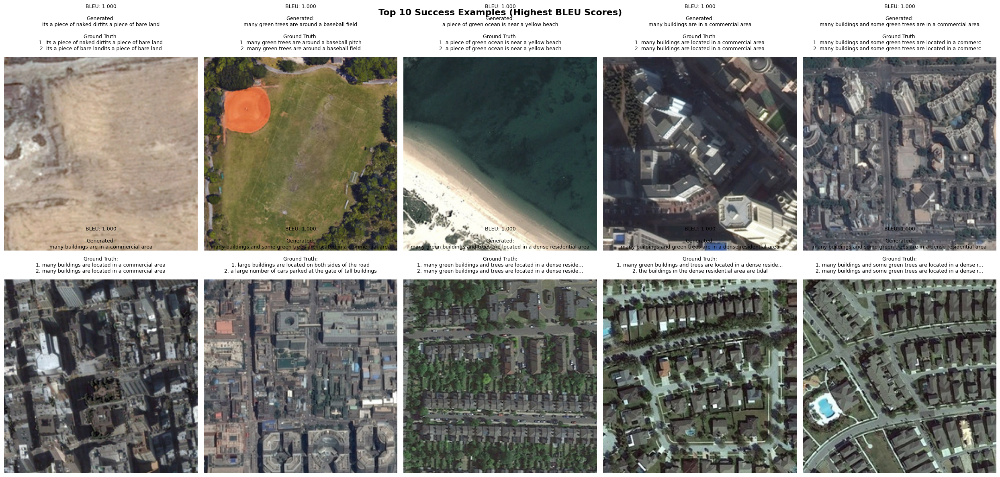


=== TOP 10 FAILURE EXAMPLES ===


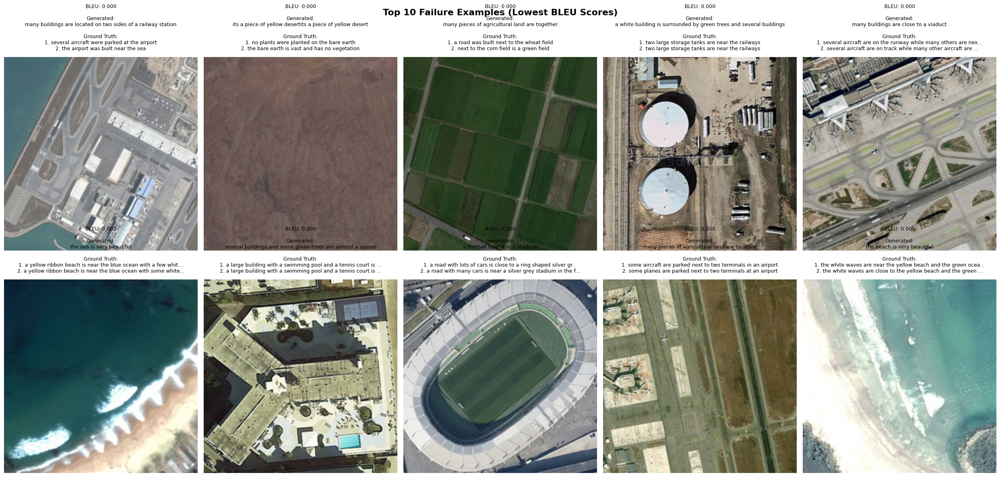


SUCCESS EXAMPLES SUMMARY:
  Average BLEU: 1.0000
  BLEU Range: 1.0000 - 1.0000
  Average brightness: 100.1
  Average caption length: 10.0

FAILURE EXAMPLES SUMMARY:
  Average BLEU: 0.0000
  BLEU Range: 0.0000 - 0.0000
  Average brightness: 123.7
  Average caption length: 11.8


In [ ]:
"""
LLM Prompt:
---------------
show 10 best/worst caption examples with imgs + captions,
plot them and print summary stats
"""
def display_success_failure_examples(results_df):
    """Display 10 success and 10 failure examples with images and captions"""

    # Select examples
    success_examples = results_df.nlargest(10, 'bleu_score')
    failure_examples = results_df.nsmallest(10, 'bleu_score')

    def plot_examples(examples, title, save_name=None):
        fig, axes = plt.subplots(2, 5, figsize=(25, 12))
        fig.suptitle(title, fontsize=16, fontweight='bold')

        for i, (_, example) in enumerate(examples.iterrows()):
            row = i // 5
            col = i % 5

            # Display image
            img_tensor = example['image_tensor']
            img_display = img_tensor.permute(1, 2, 0).numpy()
            img_display = img_display * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
            img_display = np.clip(img_display, 0, 1)

            axes[row, col].imshow(img_display)
            axes[row, col].axis('off')

            # Create caption text
            caption_text = f"BLEU: {example['bleu_score']:.3f}\n\n"
            caption_text += f"Generated:\n{example['generated_caption'][:80]}{'...' if len(example['generated_caption']) > 80 else ''}\n\n"
            caption_text += f"Ground Truth:\n"
            for j, ref_text in enumerate(example['reference_texts'][:2]):  # Show max 2 references
                caption_text += f"{j+1}. {ref_text[:60]}{'...' if len(ref_text) > 60 else ''}\n"

            axes[row, col].set_title(caption_text, fontsize=9, va='top')

        plt.tight_layout()
        if save_name:
            plt.savefig(f'{save_name}.png', dpi=150, bbox_inches='tight')
        plt.show()

    # Display examples
    print("=== TOP 10 SUCCESS EXAMPLES ===")
    plot_examples(success_examples, "Top 10 Success Examples (Highest BLEU Scores)", "success_examples")

    print("\n=== TOP 10 FAILURE EXAMPLES ===")
    plot_examples(failure_examples, "Top 10 Failure Examples (Lowest BLEU Scores)", "failure_examples")

    # Print summary statistics
    print(f"\nSUCCESS EXAMPLES SUMMARY:")
    print(f"  Average BLEU: {success_examples['bleu_score'].mean():.4f}")
    print(f"  BLEU Range: {success_examples['bleu_score'].min():.4f} - {success_examples['bleu_score'].max():.4f}")
    print(f"  Average brightness: {success_examples['brightness'].mean():.1f}")
    print(f"  Average caption length: {success_examples['avg_caption_length'].mean():.1f}")

    print(f"\nFAILURE EXAMPLES SUMMARY:")
    print(f"  Average BLEU: {failure_examples['bleu_score'].mean():.4f}")
    print(f"  BLEU Range: {failure_examples['bleu_score'].min():.4f} - {failure_examples['bleu_score'].max():.4f}")
    print(f"  Average brightness: {failure_examples['brightness'].mean():.1f}")
    print(f"  Average caption length: {failure_examples['avg_caption_length'].mean():.1f}")

    return success_examples, failure_examples

# Display examples
success_examples, failure_examples = display_success_failure_examples(results_df)


In [ ]:
"""
LLM Prompt:
---------------
do slice bleu analysis by brightness, caption length, scene presence,
print corpus/avg/delta/count per slice
"""
def add_scene_presence_flags(results_df):
    """Add boolean columns indicating presence of scene keywords in reference captions"""

    # Define keywords for each scene type
    scene_keywords = {
        'runway': ['runway', 'airport', 'aircraft', 'plane', 'tarmac'],
        'harbor': ['harbor', 'port', 'dock', 'ship', 'boat', 'marina'],
        'farmland': ['farm', 'field', 'crop', 'agriculture', 'barn', 'rural']
    }

    def check_scene_presence(ref_list, keywords):
        """Check if any keywords are present in reference texts"""
        # Handle non-list values safely
        if not isinstance(ref_list, list) or not ref_list:
            return False
        try:
            # Join all reference texts and convert to lowercase
            combined_text = ' '.join(ref_list).lower()
            return any(keyword.lower() in combined_text for keyword in keywords)
        except Exception:
            return False

    # Add boolean columns for each scene
    for scene, keywords in scene_keywords.items():
        results_df[f'has_{scene}'] = results_df['reference_texts'].apply(
            lambda ref_list: check_scene_presence(ref_list, keywords)
        )

    return results_df

# Add the missing columns to your results_df
results_df = add_scene_presence_flags(results_df)

# Now your slice analysis will work without errors
slice_results, overall_bleu = compute_slice_analysis(results_df)

# Print results
print("\n" + "="*80)
print("SLICE-WISE BLEU ANALYSIS")
print("="*80)
print(f"Overall BLEU: {overall_bleu:.4f}")
print()

for slice_name, metrics in slice_results.items():
    print(f"{slice_name:25} | "
          f"Corpus BLEU: {metrics['corpus_bleu']:.4f} | "
          f"Avg BLEU: {metrics['avg_bleu']:.4f} | "
          f"Delta: {metrics['delta']:+.4f} | "
          f"Count: {metrics['count']:4d}")

def compute_slice_analysis(results_df):
    """Compute BLEU scores for different error slices"""

    # Define slices
    results_df['brightness_slice'] = pd.cut(results_df['brightness'],
                                          bins=[0, 80, 170, 255],
                                          labels=['dark', 'medium', 'bright'])

    results_df['length_slice'] = pd.cut(results_df['avg_caption_length'],
                                       bins=[0, 8, 16, np.inf],
                                       labels=['short', 'medium', 'long'])

    # Compute slice metrics
    slice_results = {}
    overall_bleu = results_df['bleu_score'].mean()

    # Brightness slices
    for brightness in ['dark', 'medium', 'bright']:
        subset = results_df[results_df['brightness_slice'] == brightness]
        if len(subset) > 0:
            # Corpus BLEU
            references = []
            candidates = []
            for _, row in subset.iterrows():
                references.append(row['reference_captions'])
                candidates.append(row['generated_words'])

            corpus_bleu_score = corpus_bleu(references, candidates) if references else 0.0
            avg_individual_bleu = subset['bleu_score'].mean()

            slice_results[f'Brightness: {brightness}'] = {
                'corpus_bleu': corpus_bleu_score,
                'avg_bleu': avg_individual_bleu,
                'count': len(subset),
                'delta': avg_individual_bleu - overall_bleu
            }

    # Caption length slices
    for length in ['short', 'medium', 'long']:
        subset = results_df[results_df['length_slice'] == length]
        if len(subset) > 0:
            references = []
            candidates = []
            for _, row in subset.iterrows():
                references.append(row['reference_captions'])
                candidates.append(row['generated_words'])

            corpus_bleu_score = corpus_bleu(references, candidates) if references else 0.0
            avg_individual_bleu = subset['bleu_score'].mean()

            slice_results[f'Caption Length: {length}'] = {
                'corpus_bleu': corpus_bleu_score,
                'avg_bleu': avg_individual_bleu,
                'count': len(subset),
                'delta': avg_individual_bleu - overall_bleu
            }

    # Scene slices
    for scene in ['runway', 'harbor', 'farmland']:
        # Present
        subset = results_df[results_df[f'has_{scene}'] == True]
        if len(subset) > 0:
            references = []
            candidates = []
            for _, row in subset.iterrows():
                references.append(row['reference_captions'])
                candidates.append(row['generated_words'])

            corpus_bleu_score = corpus_bleu(references, candidates) if references else 0.0
            avg_individual_bleu = subset['bleu_score'].mean()

            slice_results[f'{scene.title()}: Present'] = {
                'corpus_bleu': corpus_bleu_score,
                'avg_bleu': avg_individual_bleu,
                'count': len(subset),
                'delta': avg_individual_bleu - overall_bleu
            }

        # Absent
        subset = results_df[results_df[f'has_{scene}'] == False]
        if len(subset) > 0:
            references = []
            candidates = []
            for _, row in subset.iterrows():
                references.append(row['reference_captions'])
                candidates.append(row['generated_words'])

            corpus_bleu_score = corpus_bleu(references, candidates) if references else 0.0
            avg_individual_bleu = subset['bleu_score'].mean()

            slice_results[f'{scene.title()}: Absent'] = {
                'corpus_bleu': corpus_bleu_score,
                'avg_bleu': avg_individual_bleu,
                'count': len(subset),
                'delta': avg_individual_bleu - overall_bleu
            }

    return slice_results, overall_bleu

# Compute slice analysis
slice_results, overall_bleu = compute_slice_analysis(results_df)

# Print results
print("\n" + "="*80)
print("SLICE-WISE BLEU ANALYSIS")
print("="*80)
print(f"Overall BLEU: {overall_bleu:.4f}")
print()

for slice_name, metrics in slice_results.items():
    print(f"{slice_name:25} | "
          f"Corpus BLEU: {metrics['corpus_bleu']:.4f} | "
          f"Avg BLEU: {metrics['avg_bleu']:.4f} | "
          f"Delta: {metrics['delta']:+.4f} | "
          f"Count: {metrics['count']:4d}")



SLICE-WISE BLEU ANALYSIS
Overall BLEU: 0.2592

Brightness: dark          | Corpus BLEU: 0.4092 | Avg BLEU: 0.3277 | Delta: +0.0685 | Count:  337
Brightness: medium        | Corpus BLEU: 0.3270 | Avg BLEU: 0.2405 | Delta: -0.0187 | Count: 1041
Brightness: bright        | Corpus BLEU: 0.2394 | Avg BLEU: 0.1751 | Delta: -0.0841 | Count:   43
Caption Length: short     | Corpus BLEU: 0.3288 | Avg BLEU: 0.3105 | Delta: +0.0513 | Count:  165
Caption Length: medium    | Corpus BLEU: 0.3448 | Avg BLEU: 0.2552 | Delta: -0.0040 | Count: 1198
Caption Length: long      | Corpus BLEU: 0.2621 | Avg BLEU: 0.1959 | Delta: -0.0633 | Count:   58
Runway: Present           | Corpus BLEU: 0.1781 | Avg BLEU: 0.1000 | Delta: -0.1592 | Count:   61
Runway: Absent            | Corpus BLEU: 0.3512 | Avg BLEU: 0.2664 | Delta: +0.0071 | Count: 1360
Harbor: Present           | Corpus BLEU: 0.2758 | Avg BLEU: 0.1784 | Delta: -0.0808 | Count:  138
Harbor: Absent            | Corpus BLEU: 0.3518 | Avg BLEU: 0.2679 | D

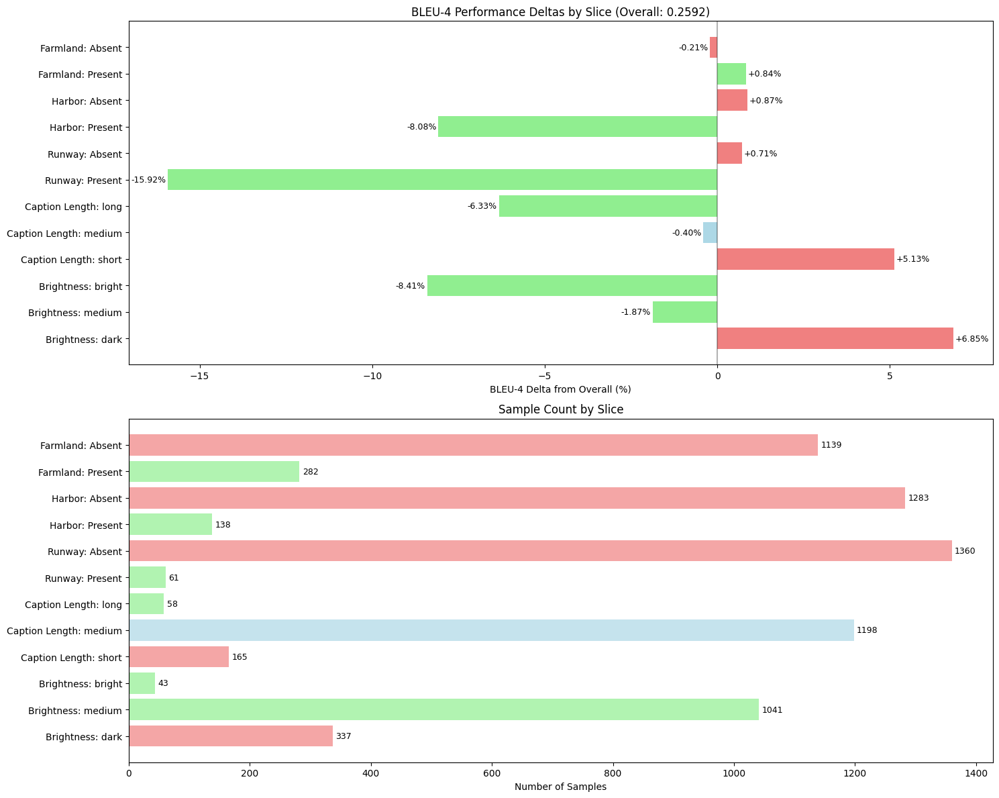

In [ ]:
"""
LLM Prompt:
---------------
plot slice bleu deltas vs overall and sample counts,
use varied line breaks in titles/labels for better clarity
"""
def plot_slice_bleu_deltas(slice_results, overall_bleu):
    """Plot BLEU score deltas for each slice"""

    # Prepare data
    slice_names = list(slice_results.keys())
    deltas = [metrics['delta'] * 100 for metrics in slice_results.values()]  # Convert to percentage
    counts = [metrics['count'] for metrics in slice_results.values()]

    # Create figure with subplots
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 12))

    # Plot 1: BLEU Deltas
    colors = []
    for name in slice_names:
        if any(term in name.lower() for term in ['dark', 'short', 'absent']):
            colors.append('lightcoral')
        elif any(term in name.lower() for term in ['bright', 'long', 'present']):
            colors.append('lightgreen')
        else:
            colors.append('lightblue')

    bars1 = ax1.barh(range(len(slice_names)), deltas, color=colors)
    ax1.set_yticks(range(len(slice_names)))
    ax1.set_yticklabels(slice_names)
    ax1.set_xlabel('BLEU-4 Delta from Overall (%)')
    ax1.set_title(f'BLEU-4 Performance Deltas by Slice (Overall: {overall_bleu:.4f})')
    ax1.axvline(x=0, color='black', linestyle='-', alpha=0.3)

    # Add value labels on bars
    for i, (bar, delta) in enumerate(zip(bars1, deltas)):
        width = bar.get_width()
        label_x = width + (0.05 if width >= 0 else -0.05)
        ha = 'left' if width >= 0 else 'right'
        ax1.text(label_x, bar.get_y() + bar.get_height()/2,
                f'{delta:+.2f}%', ha=ha, va='center', fontsize=9)

    # Plot 2: Sample Counts
    bars2 = ax2.barh(range(len(slice_names)), counts, color=colors, alpha=0.7)
    ax2.set_yticks(range(len(slice_names)))
    ax2.set_yticklabels(slice_names)
    ax2.set_xlabel('Number of Samples')
    ax2.set_title('Sample Count by Slice')

    # Add value labels on bars
    for bar, count in zip(bars2, counts):
        width = bar.get_width()
        ax2.text(width + 5, bar.get_y() + bar.get_height()/2,
                f'{count}', ha='left', va='center', fontsize=9)

    plt.tight_layout()
    plt.savefig('slice_bleu_analysis.png', dpi=150, bbox_inches='tight')
    plt.show()

    return slice_names, deltas

# Create visualizations
slice_names, deltas = plot_slice_bleu_deltas(slice_results, overall_bleu)


In [ ]:
"""
LLM Prompt:
---------------
print a combined analysis summary: overall metrics,
success vs failure gap, best/worst slices, brightness/length/scene effects,
and final recommendations
"""
def print_analysis_summary(slice_results, overall_bleu, success_examples, failure_examples):
    """Print comprehensive analysis summary"""

    print("\n" + "="*80)
    print("COMPREHENSIVE QUALITATIVE & SLICE ANALYSIS SUMMARY")
    print("="*80)

    print(f"\nOVERALL PERFORMANCE:")
    print(f"  Total samples: {len(results_df)}")
    print(f"  Overall BLEU-4: {overall_bleu:.4f}")
    print(f"  BLEU range: {results_df['bleu_score'].min():.4f} - {results_df['bleu_score'].max():.4f}")

    print(f"\nSUCCESS vs FAILURE ANALYSIS:")
    print(f"  Success examples (top 10) avg BLEU: {success_examples['bleu_score'].mean():.4f}")
    print(f"  Failure examples (bottom 10) avg BLEU: {failure_examples['bleu_score'].mean():.4f}")
    print(f"  Performance gap: {success_examples['bleu_score'].mean() - failure_examples['bleu_score'].mean():.4f}")

    print(f"\nERROR SLICE ANALYSIS:")

    # Find best and worst performing slices
    slice_deltas = {name: metrics['delta'] for name, metrics in slice_results.items()}
    best_slice = max(slice_deltas, key=slice_deltas.get)
    worst_slice = min(slice_deltas, key=slice_deltas.get)

    print(f"  Best performing slice: {best_slice} (Δ = {slice_deltas[best_slice]:+.4f})")
    print(f"  Worst performing slice: {worst_slice} (Δ = {slice_deltas[worst_slice]:+.4f})")
    print(f"  Slice performance range: {slice_deltas[worst_slice]:.4f} to {slice_deltas[best_slice]:+.4f}")

    # Identify key patterns
    print(f"\nKEY FINDINGS:")

    # Brightness analysis
    brightness_results = {k: v for k, v in slice_results.items() if 'Brightness' in k}
    if brightness_results:
        bright_scores = {k.split(': ')[1]: v['avg_bleu'] for k, v in brightness_results.items()}
        best_bright = max(bright_scores, key=bright_scores.get)
        worst_bright = min(bright_scores, key=bright_scores.get)
        print(f"  • Brightness: Model performs best on {best_bright} images ({bright_scores[best_bright]:.4f})")
        print(f"               Model struggles with {worst_bright} images ({bright_scores[worst_bright]:.4f})")

    # Caption length analysis
    length_results = {k: v for k, v in slice_results.items() if 'Caption Length' in k}
    if length_results:
        length_scores = {k.split(': ')[1]: v['avg_bleu'] for k, v in length_results.items()}
        best_length = max(length_scores, key=length_scores.get)
        worst_length = min(length_scores, key=length_scores.get)
        print(f"  • Caption Length: Best performance on {best_length} captions ({length_scores[best_length]:.4f})")
        print(f"                    Worst performance on {worst_length} captions ({length_scores[worst_length]:.4f})")

    # Scene analysis
    scene_effects = []
    for scene in ['runway', 'harbor', 'farmland']:
        present_key = f'{scene.title()}: Present'
        absent_key = f'{scene.title()}: Absent'
        if present_key in slice_results and absent_key in slice_results:
            present_bleu = slice_results[present_key]['avg_bleu']
            absent_bleu = slice_results[absent_key]['avg_bleu']
            effect = present_bleu - absent_bleu
            scene_effects.append((scene, effect, present_bleu, absent_bleu))

    if scene_effects:
        print(f"  • Scene Content Effects:")
        for scene, effect, present_bleu, absent_bleu in sorted(scene_effects, key=lambda x: abs(x[1]), reverse=True):
            direction = "helps" if effect > 0 else "hurts"
            print(f"    - {scene.title()} presence {direction} performance (Δ = {effect:+.4f})")

# Generate comprehensive summary
print_analysis_summary(slice_results, overall_bleu, success_examples, failure_examples)



COMPREHENSIVE QUALITATIVE & SLICE ANALYSIS SUMMARY

OVERALL PERFORMANCE:
  Total samples: 1421
  Overall BLEU-4: 0.2592
  BLEU range: 0.0000 - 1.0000

SUCCESS vs FAILURE ANALYSIS:
  Success examples (top 10) avg BLEU: 1.0000
  Failure examples (bottom 10) avg BLEU: 0.0000
  Performance gap: 1.0000

ERROR SLICE ANALYSIS:
  Best performing slice: Brightness: dark (Δ = +0.0685)
  Worst performing slice: Runway: Present (Δ = -0.1592)
  Slice performance range: -0.1592 to +0.0685

KEY FINDINGS:
  • Brightness: Model performs best on dark images (0.3277)
               Model struggles with bright images (0.1751)
  • Caption Length: Best performance on short captions (0.3105)
                    Worst performance on long captions (0.1959)
  • Scene Content Effects:
    - Runway presence hurts performance (Δ = -0.1663)
    - Harbor presence hurts performance (Δ = -0.0895)
    - Farmland presence helps performance (Δ = +0.0105)


### CNN (Fine-tuned) + LSTM

#### Models

In [ ]:
"""
LLM Prompt:[For models and training]
---------------
Remove classifier; use global average pooling
End-to-end (last-layer fine-tune): Freeze all but last block; keep batch size small.
Embedding dim 300–512; 1–2 LSTM layers, hidden 512.
Project image feature to initial hidden state or prepend as a learned <img> token—pick one and justify.
Train with teacher forcing + cross-entropy (ignore PAD with ignore_index).
Inference: greedy (beam-3 optional for extra learning).
"""

import torch.nn as nn
from torchvision import models

class CNN_Encoder_FineTune(nn.Module):
    def __init__(self, finetune_last_block=True):
        super().__init__()
        resnet = models.resnet18(pretrained=True)

        # Remove the final classifier
        modules = list(resnet.children())[:-1]  # remove classifier
        self.resnet = nn.Sequential(*modules)

        if finetune_last_block:
            # Freeze all layers except the last block (layer4)
            for name, param in self.resnet.named_parameters():
                if 'layer4' not in name:  # freeze everything except layer4
                    param.requires_grad = False
                else:
                    param.requires_grad = True
        else:
            # Freeze all CNN parameters
            for param in self.resnet.parameters():
                param.requires_grad = False

    def forward(self, x):
        features = self.resnet(x)        # [B, 512, 1, 1]
        features = features.view(x.size(0), -1)  # [B, 512]
        return features


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

class CaptionDatasetEndToEnd(Dataset):
    def __init__(self, df, split="train", transform=None):
        self.df = df[df["split"] == split].reset_index(drop=True)
        self.transform = transform or transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                               std=[0.229, 0.224, 0.225])
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_id = row["filename"]

        # Get raw image tensor from DataFrame
        img_tensor = row["image"]  # [C, H, W] tensor

        # Apply transforms if needed (assuming already normalized)
        if self.transform and not self._is_normalized(img_tensor):
            img_tensor = self.transform(img_tensor)

        # Pick random caption for training
        import random
        cap_tokens = random.choice(row["captions"])
        cap_tensor = torch.tensor([word2idx.get(t, word2idx["<unk>"]) for t in cap_tokens], dtype=torch.long)

        return img_id, img_tensor, cap_tensor

    def _is_normalized(self, tensor):
        # Simple check if tensor is already normalized (values roughly in [-2, 2])
        return tensor.min() < 0 and tensor.max() < 3

# Modified collate function
def collate_fn_end_to_end(batch):
    img_ids, images, caps_list = zip(*batch)
    images = torch.stack(images)  # [B, C, H, W]

    # Pad captions to MAX_LEN
    MAX_LEN = 24
    caps_padded = torch.full((len(caps_list), MAX_LEN), word2idx["<pad>"], dtype=torch.long)
    for i, cap in enumerate(caps_list):
        length = min(len(cap), MAX_LEN)
        caps_padded[i, :length] = cap[:length]

    return img_ids, images, caps_padded

In [ ]:
class ImageCaptioner_EndToEnd(nn.Module):
    def __init__(self, vocab_size, embed_size=512, hidden_size=512, num_layers=1, max_len=24, finetune_cnn=True):
        super().__init__()
        self.encoder = CNN_Encoder_FineTune(finetune_last_block=finetune_cnn)
        self.decoder = LSTM_Decoder(vocab_size, embed_size, hidden_size, num_layers, max_len)
        self.max_len = max_len

    def forward(self, images, captions):
        """
        images: [B, C, H, W] raw images
        captions: [B, T] caption tokens
        """
        features = self.encoder(images)  # [B, 512]
        outputs = self.decoder(features, captions)  # [B, T, vocab_size]
        return outputs

    def generate_caption(self, images, max_len=None):
        """Generate captions for images"""
        self.eval()
        max_len = max_len or self.max_len
        batch_size = images.size(0)
        device = images.device

        with torch.no_grad():
            features = self.encoder(images)  # [B, 512]

            # Initialize with <bos> tokens
            captions = torch.full((batch_size, 1), word2idx["<bos>"], dtype=torch.long, device=device)

            for _ in range(max_len - 1):
                outputs = self.decoder(features, captions)  # [B, T, vocab_size]
                next_tokens = outputs[:, -1, :].argmax(dim=1).unsqueeze(1)  # [B, 1]
                captions = torch.cat([captions, next_tokens], dim=1)

                # Check if all sequences have ended
                if torch.all(next_tokens.squeeze() == word2idx["<eos>"]):
                    break

        return captions


#### Training

In [ ]:
from tqdm.auto import tqdm
import torch.optim as optim

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

# Smaller batch size for end-to-end training
BATCH_SIZE = 4  # Reduced from 8 due to memory constraints

# Create datasets
train_dataset = CaptionDatasetEndToEnd(data, split="train")
val_dataset = CaptionDatasetEndToEnd(data, split="val")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn_end_to_end)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn_end_to_end)

# Create end-to-end model
model = ImageCaptioner_EndToEnd(vocab_size=len(word2idx), finetune_cnn=True).to(DEVICE)

# Loss function
criterion = nn.CrossEntropyLoss(ignore_index=word2idx["<pad>"])

# Optimizer with different learning rates for CNN and LSTM
cnn_params = list(model.encoder.parameters())
lstm_params = list(model.decoder.parameters())

optimizer = optim.Adam([
    {'params': cnn_params, 'lr': 1e-5},    # Lower LR for CNN fine-tuning
    {'params': lstm_params, 'lr': 2e-4}    # Higher LR for LSTM decoder
])

# Optional: Learning rate scheduler
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.7)

NUM_EPOCHS = 15  # More epochs might be needed for fine-tuning

for epoch in range(NUM_EPOCHS):
    # --- Training ---
    model.train()
    train_loss = 0.0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]", leave=True)

    for step, (img_ids, images, captions_batch) in enumerate(pbar, start=1):
        images = images.to(DEVICE)
        captions_batch = captions_batch.to(DEVICE)

        # Forward pass
        outputs = model(images, captions_batch[:, :-1])  # teacher forcing
        loss = criterion(
            outputs.reshape(-1, len(word2idx)),
            captions_batch[:, 1:].reshape(-1)
        )

        # Backward pass
        optimizer.zero_grad()
        loss.backward()

        # Gradient clipping to prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)

        optimizer.step()

        train_loss += float(loss)
        avg_train = train_loss / step

        # Show loss and learning rates
        lr_cnn = optimizer.param_groups[0]["lr"]
        lr_lstm = optimizer.param_groups[1]["lr"]
        pbar.set_postfix(loss=f"{float(loss):.4f}", avg=f"{avg_train:.4f}",
                        lr_cnn=f"{lr_cnn:.2e}", lr_lstm=f"{lr_lstm:.2e}")

    avg_train_loss = train_loss / max(1, len(train_loader))

    # --- Validation ---
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for img_ids, images, captions_batch in tqdm(val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]", leave=False):
            images = images.to(DEVICE)
            captions_batch = captions_batch.to(DEVICE)

            outputs = model(images, captions_batch[:, :-1])
            loss = criterion(
                outputs.reshape(-1, len(word2idx)),
                captions_batch[:, 1:].reshape(-1)
            )
            val_loss += float(loss)

    avg_val_loss = val_loss / max(1, len(val_loader))

    print(f"Epoch {epoch+1}: Train Loss = {avg_train_loss:.4f}, Val Loss = {avg_val_loss:.4f}")

    # Step scheduler
    scheduler.step()

    # Save checkpoint every few epochs
    if (epoch + 1) % 5 == 0:
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_loss': avg_train_loss,
            'val_loss': avg_val_loss,
        }, f'checkpoint_epoch_{epoch+1}.pth')


Using device: cuda


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Epoch 1/15 [Train]: 100%|█| 2000/2000 [01:30<00:00, 22.05it/s, avg=2.8322, loss=1.6336, lr_cnn=1.00e-05, lr_lstm=2.00e-
                                                                                                                       

Epoch 1: Train Loss = 2.8322, Val Loss = 2.3612


Epoch 2/15 [Train]: 100%|█| 2000/2000 [01:13<00:00, 27.34it/s, avg=2.1412, loss=2.1897, lr_cnn=1.00e-05, lr_lstm=2.00e-
                                                                                                                       

Epoch 2: Train Loss = 2.1412, Val Loss = 2.1570


Epoch 3/15 [Train]: 100%|█| 2000/2000 [01:18<00:00, 25.52it/s, avg=1.9674, loss=1.2339, lr_cnn=1.00e-05, lr_lstm=2.00e-
                                                                                                                       

... (21 outputs left out)

Epoch 14/15 [Train]: 100%|█| 2000/2000 [01:11<00:00, 27.89it/s, avg=1.4681, loss=2.5264, lr_cnn=2.40e-06, lr_lstm=4.80e
                                                                                                                       

Epoch 14: Train Loss = 1.4681, Val Loss = 1.8182


Epoch 15/15 [Train]: 100%|█| 2000/2000 [01:14<00:00, 26.96it/s, avg=1.4526, loss=1.1031, lr_cnn=2.40e-06, lr_lstm=4.80e
                                                                                                                       

Epoch 15: Train Loss = 1.4526, Val Loss = 1.8038


#### Viewing Predictions

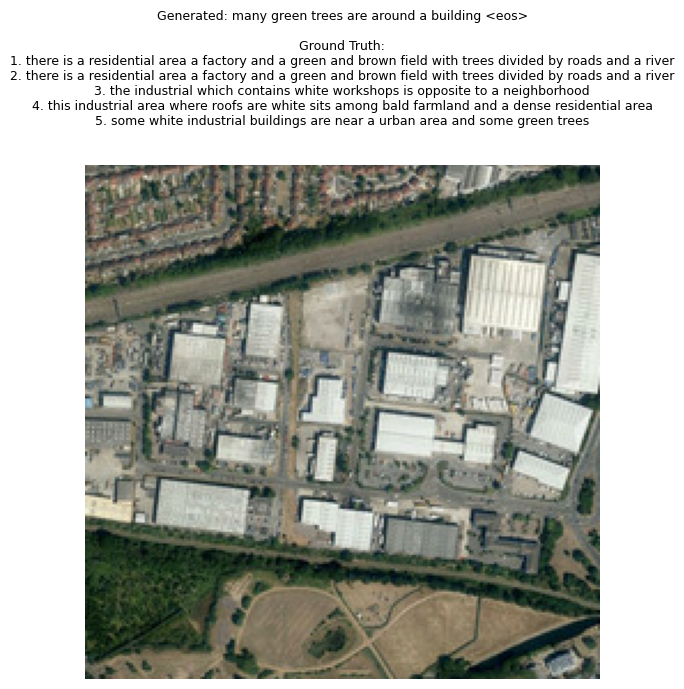


Image: rsicd_images/industrial_234.jpg
Generated: many green trees are around a building <eos>
Ground Truth:
  1. there is a residential area a factory and a green and brown field with trees divided by roads and a river
  2. there is a residential area a factory and a green and brown field with trees divided by roads and a river
  3. the industrial which contains white workshops is opposite to a neighborhood
  4. this industrial area where roofs are white sits among bald farmland and a dense residential area
  5. some white industrial buildings are near a urban area and some green trees
------------------------------------------------------------


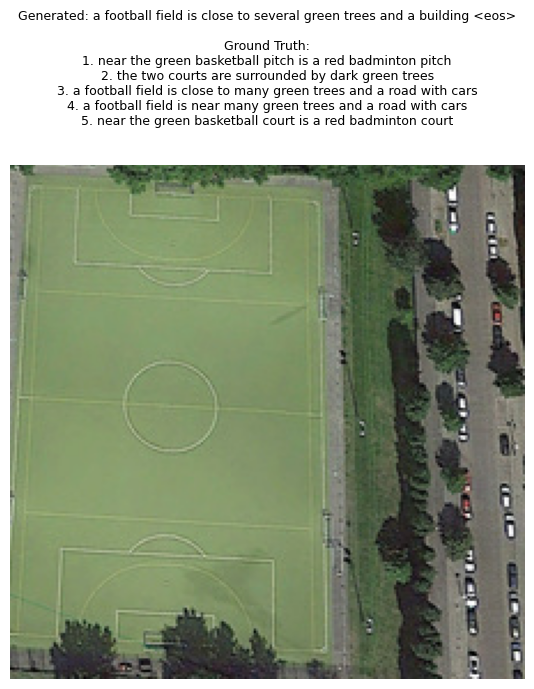


Image: rsicd_images/playground_300.jpg
Generated: a football field is close to several green trees and a building <eos>
Ground Truth:
  1. near the green basketball pitch is a red badminton pitch
  2. the two courts are surrounded by dark green trees
  3. a football field is close to many green trees and a road with cars
  4. a football field is near many green trees and a road with cars
  5. near the green basketball court is a red badminton court
------------------------------------------------------------


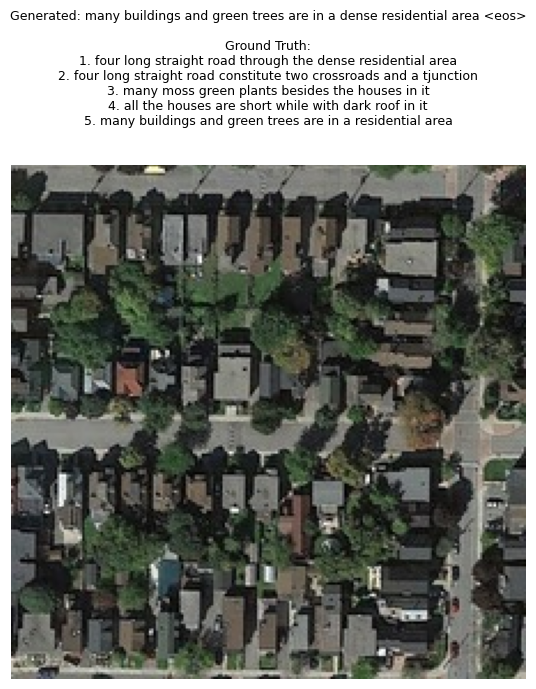


Image: rsicd_images/denseresidential_13.jpg
Generated: many buildings and green trees are in a dense residential area <eos>
Ground Truth:
  1. four long straight road through the dense residential area
  2. four long straight road constitute two crossroads and a tjunction
  3. many moss green plants besides the houses in it
  4. all the houses are short while with dark roof in it
  5. many buildings and green trees are in a residential area
------------------------------------------------------------


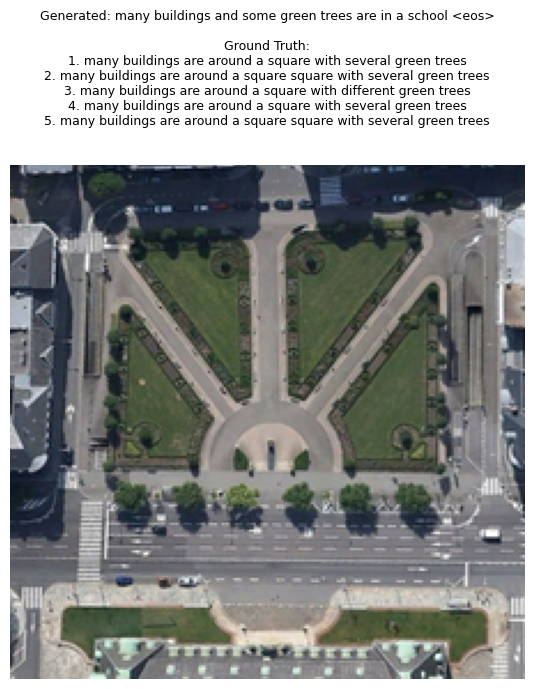


Image: rsicd_images/square_269.jpg
Generated: many buildings and some green trees are in a school <eos>
Ground Truth:
  1. many buildings are around a square with several green trees
  2. many buildings are around a square square with several green trees
  3. many buildings are around a square with different green trees
  4. many buildings are around a square with several green trees
  5. many buildings are around a square square with several green trees
------------------------------------------------------------


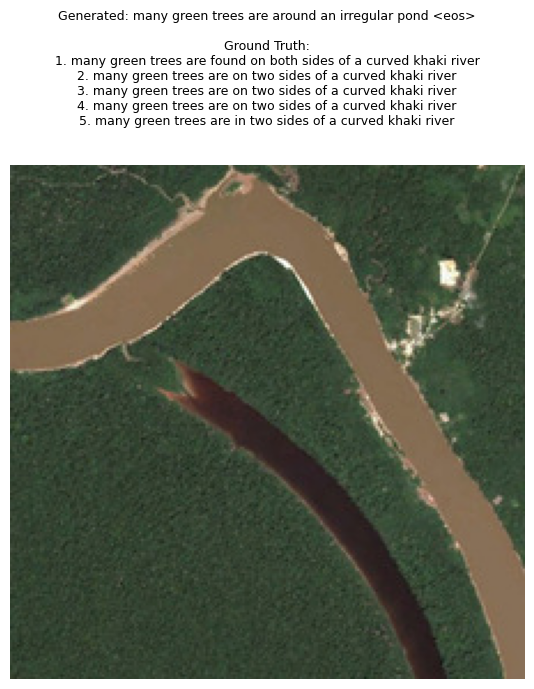


Image: rsicd_images/river_247.jpg
Generated: many green trees are around an irregular pond <eos>
Ground Truth:
  1. many green trees are found on both sides of a curved khaki river
  2. many green trees are on two sides of a curved khaki river
  3. many green trees are on two sides of a curved khaki river
  4. many green trees are on two sides of a curved khaki river
  5. many green trees are in two sides of a curved khaki river
------------------------------------------------------------


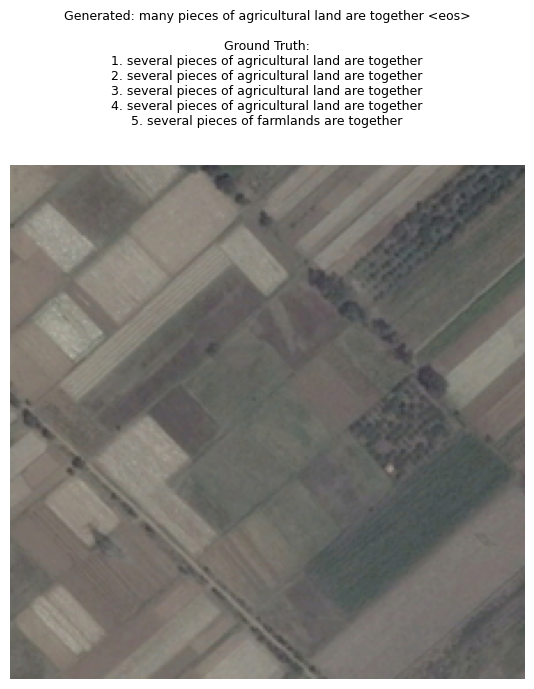


Image: rsicd_images/farmland_299.jpg
Generated: many pieces of agricultural land are together <eos>
Ground Truth:
  1. several pieces of agricultural land are together
  2. several pieces of agricultural land are together
  3. several pieces of agricultural land are together
  4. several pieces of agricultural land are together
  5. several pieces of farmlands are together
------------------------------------------------------------


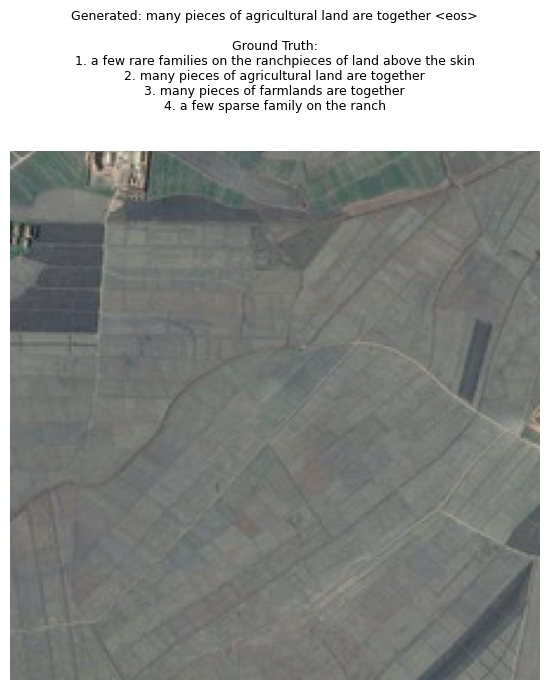


Image: rsicd_images/farmland_95.jpg
Generated: many pieces of agricultural land are together <eos>
Ground Truth:
  1. a few rare families on the ranchpieces of land above the skin
  2. many pieces of agricultural land are together
  3. many pieces of farmlands are together
  4. a few sparse family on the ranch
------------------------------------------------------------


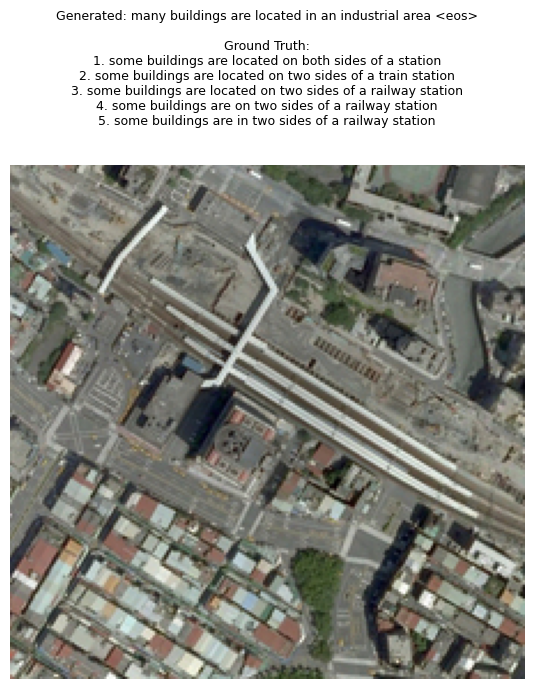


Image: rsicd_images/railwaystation_131.jpg
Generated: many buildings are located in an industrial area <eos>
Ground Truth:
  1. some buildings are located on both sides of a station
  2. some buildings are located on two sides of a train station
  3. some buildings are located on two sides of a railway station
  4. some buildings are on two sides of a railway station
  5. some buildings are in two sides of a railway station
------------------------------------------------------------


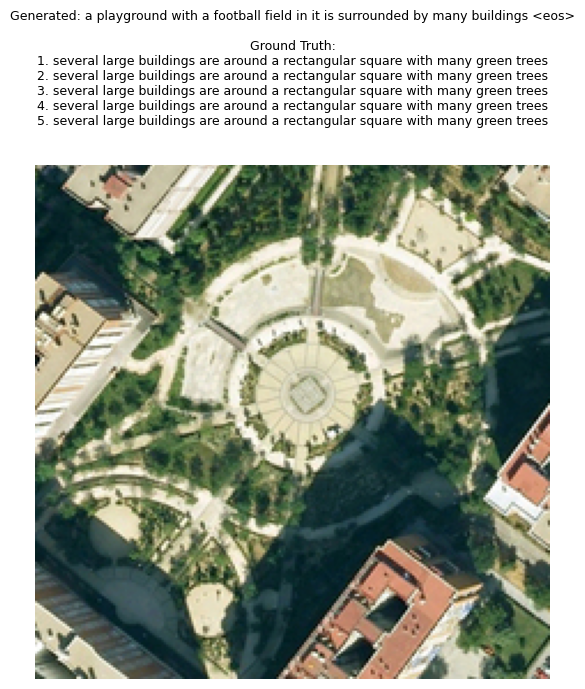


Image: rsicd_images/square_218.jpg
Generated: a playground with a football field in it is surrounded by many buildings <eos>
Ground Truth:
  1. several large buildings are around a rectangular square with many green trees
  2. several large buildings are around a rectangular square with many green trees
  3. several large buildings are around a rectangular square with many green trees
  4. several large buildings are around a rectangular square with many green trees
  5. several large buildings are around a rectangular square with many green trees
------------------------------------------------------------


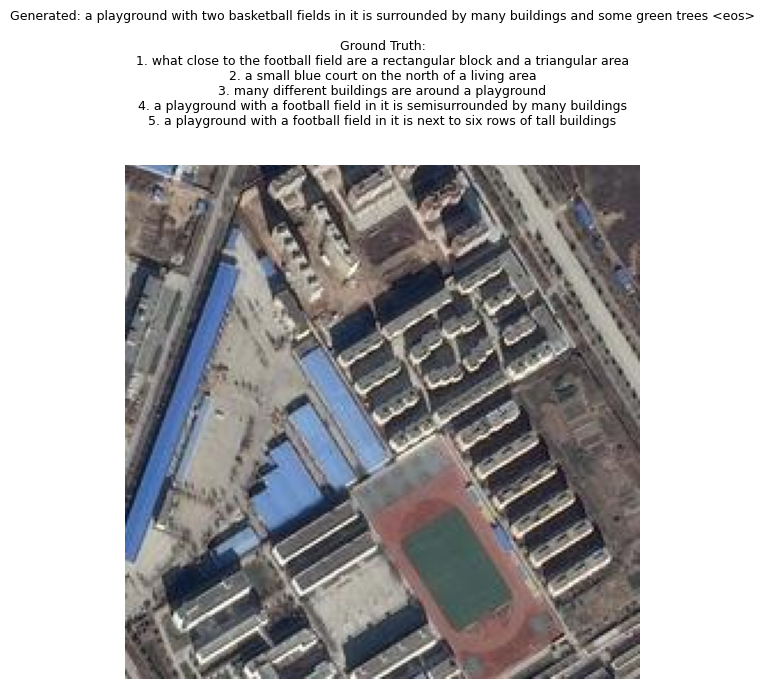


Image: rsicd_images/00096.jpg
Generated: a playground with two basketball fields in it is surrounded by many buildings and some green trees <eos>
Ground Truth:
  1. what close to the football field are a rectangular block and a triangular area
  2. a small blue court on the north of a living area
  3. many different buildings are around a playground
  4. a playground with a football field in it is semisurrounded by many buildings
  5. a playground with a football field in it is next to six rows of tall buildings
------------------------------------------------------------


In [ ]:
"""
LLM Prompt:
----------
Help me view predictions with ground truth values
"""
import matplotlib.pyplot as plt
import random
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
model.eval()

# Create test dataset
test_dataset = CaptionDatasetEndToEnd(data, split="test")
test_indices = random.sample(range(len(test_dataset)), 10)

# ImageNet normalization values
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

with torch.no_grad():
    for idx in test_indices:
        img_id, img_tensor, _ = test_dataset[idx]
        img_tensor = img_tensor.to(DEVICE).unsqueeze(0)  # [1, C, H, W]

        # Generate caption using end-to-end model
        caption_tokens = model.generate_caption(img_tensor, max_len=24)  # [1, T]

        # Convert to words
        tokens = caption_tokens[0].tolist()
        words = [idx2word[t] for t in tokens if t not in (word2idx["<bos>"], word2idx["<pad>"])]
        generated_caption = " ".join(words)

        # --- Fetch Ground Truth Captions ---
        ground_truth_captions = []
        mask = data["filename"] == img_id
        if mask.any():
            img_row_idx = mask.idxmax()
            captions_list = data.loc[img_row_idx, "captions"]

            for cap in captions_list:
                # Ensure it's a list of tokens (handle both string and list formats)
                if isinstance(cap, str):
                    tokens = cap.split()
                else:
                    tokens = cap

                # Remove special tokens and join
                clean_tokens = [t for t in tokens if t not in {"<bos>", "<pad>", "<eos>"}]
                if clean_tokens:  # only add non-empty captions
                    ground_truth_captions.append(" ".join(clean_tokens))

        # Unnormalize image for display
        img_display = img_tensor[0].cpu() * IMAGENET_STD + IMAGENET_MEAN
        img_display = img_display.permute(1, 2, 0).clamp(0, 1).numpy()

        plt.figure(figsize=(10, 7))
        plt.imshow(img_display)
        plt.axis('off')

        # Create title with both generated and ground truth captions
        title_text = f"Generated: {generated_caption}\n\n"
        title_text += "Ground Truth:\n"
        for i, gt_cap in enumerate(ground_truth_captions, 1):
            title_text += f"{i}. {gt_cap}\n"

        plt.title(title_text, fontsize=9, wrap=True, pad=20)
        plt.tight_layout()
        plt.show()

        # Also print to console for better readability
        print(f"\nImage: {img_id}")
        print(f"Generated: {generated_caption}")
        print("Ground Truth:")
        for i, gt_cap in enumerate(ground_truth_captions, 1):
            print(f"  {i}. {gt_cap}")
        print("-" * 60)


#### Scoring Metrics

In [ ]:
"""
LLM Prompt:
----------
5.1 Metrics
BLEU-4 and METEOR (via nltk or torchmetrics).
Caption length stats (mean±std), and % of degenerate repetitions (≥3 identical tokens in a row).
"""
generated_captions = []
reference_captions = []
degenerate_count = 0
all_lengths = []

SPECIAL_TOKENS_SET = {word2idx["<bos>"], word2idx["<pad>"], word2idx["<eos>"]}

# Create test dataset for end-to-end evaluation
test_dataset = CaptionDatasetEndToEnd(data, split="test")

model.eval()
with torch.no_grad():
    for idx in range(len(test_dataset)):
        img_id, img_tensor, _ = test_dataset[idx]
        img_tensor = img_tensor.to(DEVICE).unsqueeze(0)  # [1, C, H, W]

        # --- Generate caption using end-to-end model ---
        caption_tokens_tensor = model.generate_caption(img_tensor, max_len=24)  # [1, T]

        # Convert tensor to list and flatten
        caption_tokens = caption_tokens_tensor.squeeze(0).tolist()  # [T] -> list

        # Remove special tokens
        words = [idx2word[t] for t in caption_tokens if t not in SPECIAL_TOKENS_SET]
        generated_captions.append(words)
        all_lengths.append(len(words))

        # --- References: ensure each ref is a list of tokens ---
        refs = []
        mask = data["filename"] == img_id
        if mask.any():
            img_row_idx = mask.idxmax()
            captions_list = data.loc[img_row_idx, "captions"]

            for cap in captions_list:
                # Ensure it's a list of tokens (handle both string and list formats)
                if isinstance(cap, str):
                    tokens = cap.split()
                else:
                    tokens = cap

                token_list = [t for t in tokens if t not in {"<bos>", "<pad>", "<eos>"}]
                if len(token_list) == 0:
                    token_list = ["<unk>"]  # fallback for empty captions
                refs.append(token_list)
        else:
            # Fallback if image not found
            refs = [["<unk>"]]

        reference_captions.append(refs)

        # Degenerate repetition check
        for i in range(len(words) - 2):
            if words[i] == words[i+1] == words[i+2]:
                degenerate_count += 1
                break

# --- BLEU-4 ---
bleu_score = corpus_bleu(reference_captions, generated_captions)
print(f"BLEU-4: {bleu_score:.4f}")

# --- METEOR ---
meteor_scores = []
for refs, gen in zip(reference_captions, generated_captions):
    # meteor_score expects Iterable[Iterable[str]] for references and Iterable[str] for hypothesis
    score = meteor_score(refs, gen)
    meteor_scores.append(score)

meteor_avg = np.mean(meteor_scores)
print(f"METEOR: {meteor_avg:.4f}")

# --- Caption length stats ---
mean_len = np.mean(all_lengths)
std_len = np.std(all_lengths)
print(f"Caption length: mean={mean_len:.2f}, std={std_len:.2f}")

# --- Degenerate repetition ---
degenerate_pct = 100 * degenerate_count / len(test_dataset)
print(f"Degenerate repetitions (≥3 tokens in a row): {degenerate_pct:.2f}%")

# --- Additional Metrics ---
print(f"\nTotal test samples: {len(test_dataset)}")
print(f"Total generated captions: {len(generated_captions)}")
print(f"Average references per image: {np.mean([len(refs) for refs in reference_captions]):.2f}")

# --- Vocabulary coverage ---
generated_vocab = set()
for caption in generated_captions:
    generated_vocab.update(caption)

reference_vocab = set()
for refs in reference_captions:
    for ref in refs:
        reference_vocab.update(ref)

vocab_coverage = len(generated_vocab.intersection(reference_vocab)) / len(reference_vocab) * 100
print(f"Vocabulary coverage: {vocab_coverage:.2f}%")
print(f"Generated vocabulary size: {len(generated_vocab)}")
print(f"Reference vocabulary size: {len(reference_vocab)}")

BLEU-4: 0.2955
METEOR: 0.4909
Caption length: mean=10.19, std=2.36
Degenerate repetitions (≥3 tokens in a row): 0.00%

Total test samples: 1421
Total generated captions: 1421
Average references per image: 4.88
Vocabulary coverage: 8.68%
Generated vocabulary size: 132
Reference vocabulary size: 1509


### CNN (Fine-tuned) + Transformer

#### Models

In [ ]:
"""
LLM Prompt:[for models and training]
-----------
Remove classifier; use global average pooling
End-to-end (last-layer fine-tune): Freeze all but last block; keep batch size small.
Embedding dim 300–512; 1–2 LSTM layers, hidden 512.
nn.TransformerDecoder with 2–4 layers, 4–8 heads, d_model=512.
Provide causal mask and key padding mask; project image feature to a short “memory” sequence (e.g.,
tile/proj to 1–4 tokens) with LayerNorm. (optional bonus)
Training/inference same loss/decoding policy as LSTM.
Optimizers: Adam (default betas). Try LR (e.g., 2e-4 LSTM/heads; 1e-4 CNN head; 2e-5 for any unfrozenTransformer layers). Try simple LR scheduling, such as decrease LR after a few epochs.
"""
import torch
import torch.nn as nn
from torchvision import models
import math

class CNN_Encoder_FineTune(nn.Module):
    def __init__(self, finetune_last_block=True):
        super().__init__()
        resnet = models.resnet18(pretrained=True)

        # Remove the final classifier
        modules = list(resnet.children())[:-1]  # remove classifier
        self.resnet = nn.Sequential(*modules)

        if finetune_last_block:
            # Freeze all layers except the last block (layer4)
            for name, param in self.resnet.named_parameters():
                if 'layer4' not in name:  # freeze everything except layer4
                    param.requires_grad = False
                else:
                    param.requires_grad = True
        else:
            # Freeze all CNN parameters
            for param in self.resnet.parameters():
                param.requires_grad = False

    def forward(self, x):
        features = self.resnet(x)        # [B, 512, 1, 1]
        features = features.view(x.size(0), -1)  # [B, 512]
        return features

In [ ]:
# Positional encoding (sinusoidal)
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 512, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)  # [T, E]
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)  # [T, 1]
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)  # even
        pe[:, 1::2] = torch.cos(position * div_term)  # odd
        self.register_buffer("pe", pe)  # not a parameter

    def forward(self, x):  # x: [B, T, E]
        T = x.size(1)
        x = x + self.pe[:T].unsqueeze(0)  # [1, T, E]
        return self.dropout(x)

def generate_subsequent_mask(sz: int, device=None, dtype=None):
    # causal mask with 0 on/under diagonal, -inf above diagonal
    mask = torch.triu(torch.ones(sz, sz, device=device, dtype=torch.bool), diagonal=1)
    # use float mask per PyTorch convention for attention masks (additive mask)
    float_mask = torch.zeros(sz, sz, device=device, dtype=torch.float32)
    float_mask = float_mask.masked_fill(mask, float("-inf"))
    return float_mask.to(dtype) if dtype is not None else float_mask

class TransformerDecoder(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        pad_idx: int,
        d_model: int = 512,
        nhead: int = 8,
        num_layers: int = 3,
        dim_ff: int = 2048,
        dropout: float = 0.1,
        max_len: int = 24,
        memory_len: int = 2,  # 1–4 memory tokens
        img_feat_dim: int = 512,
    ):
        super().__init__()
        self.pad_idx = pad_idx
        self.max_len = max_len
        self.d_model = d_model
        self.memory_len = memory_len

        # Token embeddings
        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.pos_enc = PositionalEncoding(d_model, max_len=max_len, dropout=dropout)

        # Image -> memory tokens
        self.img_proj = nn.Linear(img_feat_dim, d_model)
        self.memory_tokens = nn.Parameter(torch.randn(memory_len, d_model))
        self.mem_norm = nn.LayerNorm(d_model)

        # Transformer decoder (batch_first for [B, T, E])
        layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,
        )
        self.decoder = nn.TransformerDecoder(layer, num_layers=num_layers)

        # Output head
        self.fc = nn.Linear(d_model, vocab_size)

    def _make_tgt_mask(self, T, device, dtype=None):
        return generate_subsequent_mask(T, device=device, dtype=dtype)  # [T, T]

    def forward(self, features, captions_in):
        """
        features: [B, img_feat_dim]
        captions_in: [B, T] (teacher forcing input)
        returns: logits [B, T, vocab_size]
        """
        B, T = captions_in.size()
        device = captions_in.device

        # Target embeddings + positions
        tgt = self.embed(captions_in) * math.sqrt(self.d_model)  # [B, T, E]
        tgt = self.pos_enc(tgt)  # [B, T, E]

        # Memory from image features
        mem_vec = self.img_proj(features)  # [B, E]
        mem = mem_vec.unsqueeze(1).expand(B, self.memory_len, self.d_model)  # [B, S_mem, E]
        mem = mem + self.memory_tokens.unsqueeze(0)  # add learned memory tokens
        mem = self.mem_norm(mem)  # [B, S_mem, E]

        # Masks
        tgt_mask = self._make_tgt_mask(T, device=device)  # [T, T], additive mask
        # key padding mask: True indicates positions to ignore
        tgt_key_padding_mask = (captions_in == self.pad_idx)  # [B, T] bool

        # Decode
        dec = self.decoder(
            tgt=tgt,
            memory=mem,
            tgt_mask=tgt_mask,
            tgt_key_padding_mask=tgt_key_padding_mask,
            memory_key_padding_mask=None,
        )  # [B, T, E]
        logits = self.fc(dec)  # [B, T, V]
        return logits


In [ ]:
class CNN_Transformer_Captioner(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        pad_idx: int,
        bos_idx: int,
        eos_idx: int,
        d_model: int = 512,
        nhead: int = 8,
        num_layers: int = 3,
        dim_ff: int = 2048,
        dropout: float = 0.1,
        max_len: int = 24,
        memory_len: int = 2,
        finetune_cnn: bool = True
    ):
        super().__init__()
        self.pad_idx = pad_idx
        self.bos_idx = bos_idx
        self.eos_idx = eos_idx
        self.max_len = max_len

        # CNN Encoder
        self.encoder = CNN_Encoder_FineTune(finetune_last_block=finetune_cnn)

        # Transformer Decoder
        self.decoder = TransformerDecoder(
            vocab_size=vocab_size,
            pad_idx=pad_idx,
            d_model=d_model,
            nhead=nhead,
            num_layers=num_layers,
            dim_ff=dim_ff,
            dropout=dropout,
            max_len=max_len,
            memory_len=memory_len,
            img_feat_dim=512,  # ResNet-18 feature size
        )

    def forward(self, images, captions):
        """
        images: [B, C, H, W] raw images
        captions: [B, T] caption tokens (teacher forcing)
        """
        features = self.encoder(images)  # [B, 512]
        logits = self.decoder(features, captions)  # [B, T, vocab_size]
        return logits

    @torch.no_grad()
    def generate(self, images, max_len=None):
        """
        Greedy decoding for a batch of images.
        images: [B, C, H, W]
        returns: token indices [B, T_out]
        """
        self.eval()
        max_len = max_len or self.max_len
        B = images.size(0)
        device = images.device

        # Extract features
        features = self.encoder(images)  # [B, 512]

        # Init sequences with <bos>
        ys = torch.full((B, 1), self.bos_idx, dtype=torch.long, device=device)  # [B, 1]

        # Precompute memory
        mem_vec = self.decoder.img_proj(features)  # [B, E]
        mem = mem_vec.unsqueeze(1).expand(B, self.decoder.memory_len, self.decoder.d_model)  # [B, S_mem, E]
        mem = mem + self.decoder.memory_tokens.unsqueeze(0)
        mem = self.decoder.mem_norm(mem)

        for _ in range(max_len - 1):
            tgt = self.decoder.embed(ys) * math.sqrt(self.decoder.d_model)
            tgt = self.decoder.pos_enc(tgt)
            T = ys.size(1)
            tgt_mask = self.decoder._make_tgt_mask(T, device=device)

            dec = self.decoder.decoder(
                tgt=tgt,
                memory=mem,
                tgt_mask=tgt_mask,
                tgt_key_padding_mask=None,
                memory_key_padding_mask=None,
            )
            logits = self.decoder.fc(dec[:, -1:, :])  # [B, 1, V]
            next_token = logits.argmax(dim=-1)  # [B, 1]
            ys = torch.cat([ys, next_token], dim=1)

            # Early stop if all ended
            if torch.all(next_token.squeeze(1) == self.eos_idx):
                break
        return ys

#### Training

In [ ]:
from tqdm.auto import tqdm
import torch.optim as optim

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

# Model parameters
pad_idx = word2idx["<pad>"]
bos_idx = word2idx["<bos>"]
eos_idx = word2idx["<eos>"]
MAX_LEN = 24

# Create model
model = CNN_Transformer_Captioner(
    vocab_size=len(word2idx),
    pad_idx=pad_idx,
    bos_idx=bos_idx,
    eos_idx=eos_idx,
    d_model=512,
    nhead=8,
    num_layers=3,
    dim_ff=2048,
    dropout=0.1,
    max_len=MAX_LEN,
    memory_len=2,
    finetune_cnn=True
).to(DEVICE)

# Loss function
criterion = nn.CrossEntropyLoss(ignore_index=pad_idx)

# Optimizer with different learning rates
cnn_params = list(model.encoder.parameters())
transformer_params = list(model.decoder.parameters())

optimizer = torch.optim.Adam([
    {"params": cnn_params, "lr": 1e-5},           # Lower LR for CNN fine-tuning
    {"params": transformer_params, "lr": 2e-5},   # Lower LR for Transformer layers
])

# Learning rate scheduler
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.7)

# Smaller batch size for memory efficiency
BATCH_SIZE = 8

# Create datasets and dataloaders
train_dataset = CaptionDatasetEndToEnd(data, split="train")
val_dataset = CaptionDatasetEndToEnd(data, split="val")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn_end_to_end)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn_end_to_end)

NUM_EPOCHS = 5

for epoch in range(NUM_EPOCHS):
    # --- Training ---
    model.train()
    train_loss = 0.0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]", leave=True)

    for step, (img_ids, images, captions_batch) in enumerate(pbar, start=1):
        images = images.to(DEVICE)
        captions_batch = captions_batch.to(DEVICE)

        # Forward pass
        logits = model(images, captions_batch[:, :-1])  # [B, T-1, V]
        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            captions_batch[:, 1:].reshape(-1),
        )

        # Backward pass
        optimizer.zero_grad()
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)

        optimizer.step()

        train_loss += float(loss)
        avg_train = train_loss / step

        # Show learning rates
        lr_cnn = optimizer.param_groups[0]["lr"]
        lr_transformer = optimizer.param_groups[1]["lr"]
        pbar.set_postfix(
            loss=f"{float(loss):.4f}",
            avg=f"{avg_train:.4f}",
            lr_cnn=f"{lr_cnn:.2e}",
            lr_tr=f"{lr_transformer:.2e}"
        )

    avg_train_loss = train_loss / max(1, len(train_loader))

    # --- Validation ---
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for img_ids, images, captions_batch in tqdm(val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]", leave=False):
            images = images.to(DEVICE)
            captions_batch = captions_batch.to(DEVICE)

            logits = model(images, captions_batch[:, :-1])
            loss = criterion(
                logits.reshape(-1, logits.size(-1)),
                captions_batch[:, 1:].reshape(-1),
            )
            val_loss += float(loss)

    avg_val_loss = val_loss / max(1, len(val_loader))

    print(f"Epoch {epoch+1}: Train Loss = {avg_train_loss:.4f}, Val Loss = {avg_val_loss:.4f}")

    # Step scheduler
    scheduler.step()

    # Save checkpoint
    if (epoch + 1) % 5 == 0:
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_loss': avg_train_loss,
            'val_loss': avg_val_loss,
        }, f'cnn_transformer_checkpoint_epoch_{epoch+1}.pth')


Using device: cuda


Epoch 1/5 [Train]: 100%|█| 1000/1000 [01:32<00:00, 10.76it/s, avg=3.8634, loss=3.3168, lr_cnn=1.00e-05, lr_tr=2.00e-05]
                                                                                                                       

Epoch 1: Train Loss = 3.8634, Val Loss = 2.9674


Epoch 2/5 [Train]: 100%|█| 1000/1000 [01:31<00:00, 10.91it/s, avg=2.7563, loss=3.2035, lr_cnn=1.00e-05, lr_tr=2.00e-05]
                                                                                                                       

Epoch 2: Train Loss = 2.7563, Val Loss = 2.6105


Epoch 3/5 [Train]: 100%|█| 1000/1000 [01:35<00:00, 10.49it/s, avg=2.5112, loss=3.1790, lr_cnn=1.00e-05, lr_tr=2.00e-05]
                                                                                                                       

Epoch 3: Train Loss = 2.5112, Val Loss = 2.4454


Epoch 4/5 [Train]: 100%|█| 1000/1000 [01:38<00:00, 10.16it/s, avg=2.3588, loss=3.0081, lr_cnn=7.00e-06, lr_tr=1.40e-05]
                                                                                                                       

Epoch 4: Train Loss = 2.3588, Val Loss = 2.3280


Epoch 5/5 [Train]: 100%|█| 1000/1000 [01:33<00:00, 10.75it/s, avg=2.2739, loss=2.1371, lr_cnn=7.00e-06, lr_tr=1.40e-05]
                                                                                                                       

Epoch 5: Train Loss = 2.2739, Val Loss = 2.2268


#### Predicting

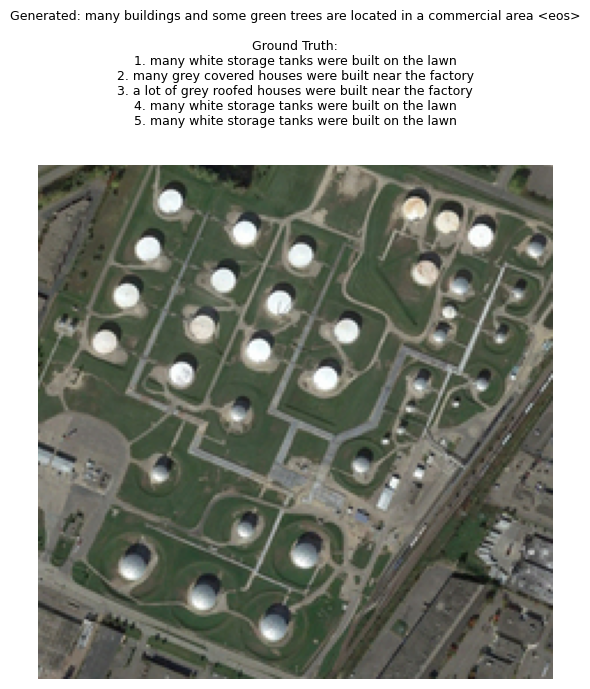


Image: rsicd_images/storagetanks_53.jpg
Generated: many buildings and some green trees are located in a commercial area <eos>
Ground Truth:
  1. many white storage tanks were built on the lawn
  2. many grey covered houses were built near the factory
  3. a lot of grey roofed houses were built near the factory
  4. many white storage tanks were built on the lawn
  5. many white storage tanks were built on the lawn
------------------------------------------------------------


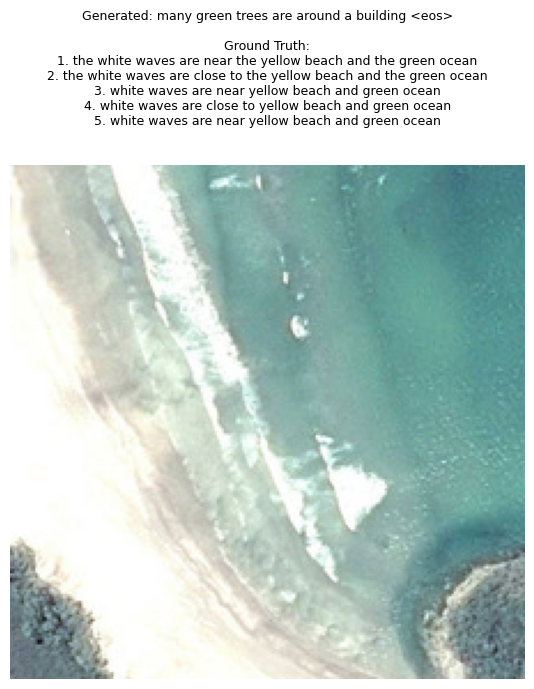


Image: rsicd_images/beach_108.jpg
Generated: many green trees are around a building <eos>
Ground Truth:
  1. the white waves are near the yellow beach and the green ocean
  2. the white waves are close to the yellow beach and the green ocean
  3. white waves are near yellow beach and green ocean
  4. white waves are close to yellow beach and green ocean
  5. white waves are near yellow beach and green ocean
------------------------------------------------------------


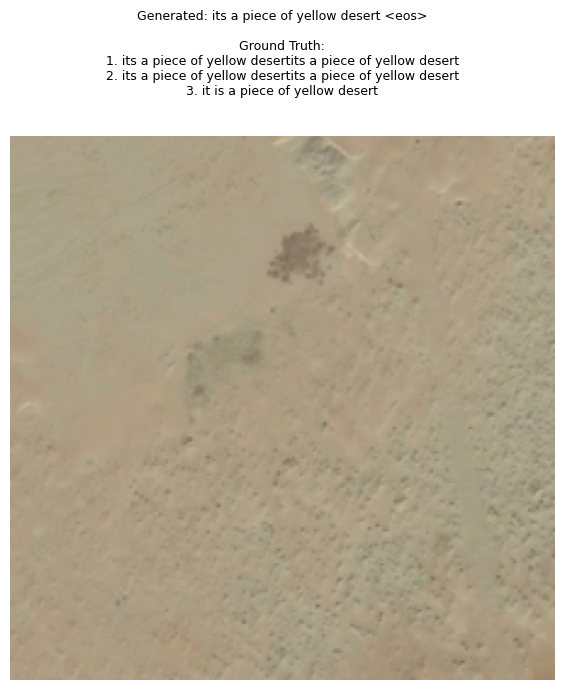


Image: rsicd_images/desert_242.jpg
Generated: its a piece of yellow desert <eos>
Ground Truth:
  1. its a piece of yellow desertits a piece of yellow desert
  2. its a piece of yellow desertits a piece of yellow desert
  3. it is a piece of yellow desert
------------------------------------------------------------


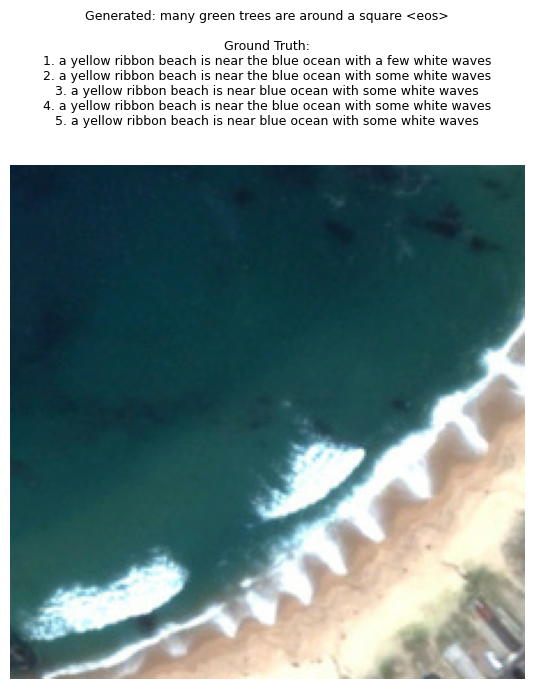


Image: rsicd_images/beach_270.jpg
Generated: many green trees are around a square <eos>
Ground Truth:
  1. a yellow ribbon beach is near the blue ocean with a few white waves
  2. a yellow ribbon beach is near the blue ocean with some white waves
  3. a yellow ribbon beach is near blue ocean with some white waves
  4. a yellow ribbon beach is near the blue ocean with some white waves
  5. a yellow ribbon beach is near blue ocean with some white waves
------------------------------------------------------------


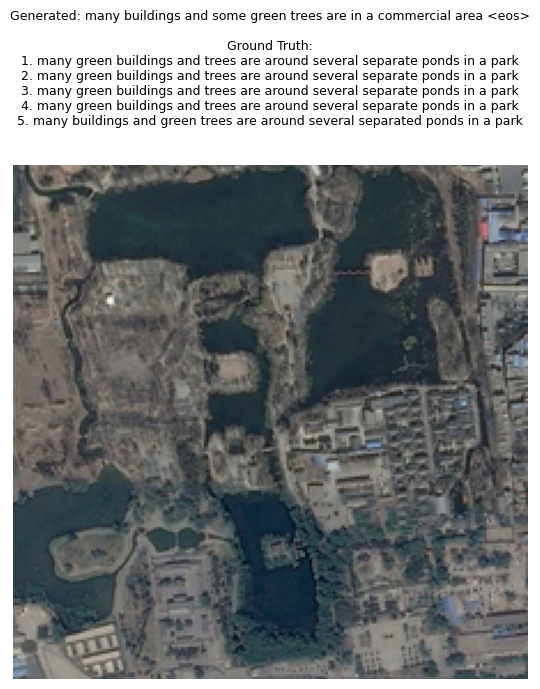


Image: rsicd_images/park_264.jpg
Generated: many buildings and some green trees are in a commercial area <eos>
Ground Truth:
  1. many green buildings and trees are around several separate ponds in a park
  2. many green buildings and trees are around several separate ponds in a park
  3. many green buildings and trees are around several separate ponds in a park
  4. many green buildings and trees are around several separate ponds in a park
  5. many buildings and green trees are around several separated ponds in a park
------------------------------------------------------------


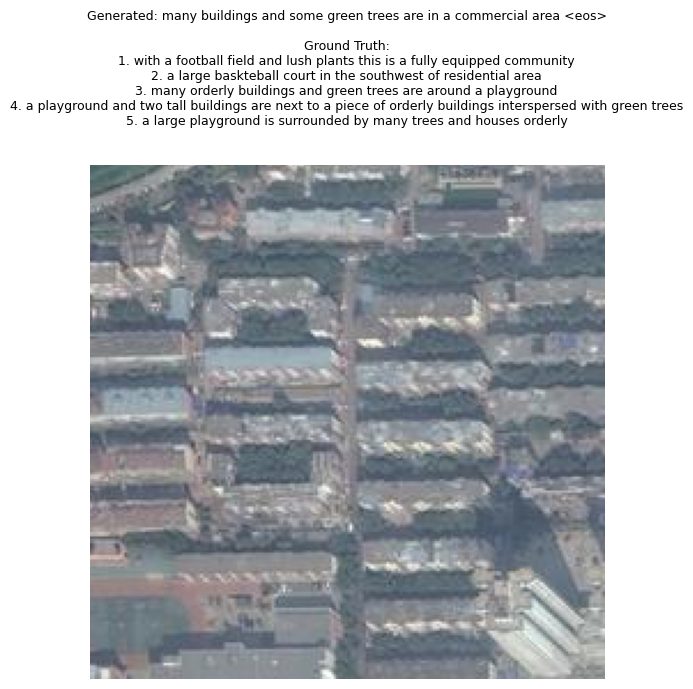


Image: rsicd_images/00062.jpg
Generated: many buildings and some green trees are in a commercial area <eos>
Ground Truth:
  1. with a football field and lush plants this is a fully equipped community
  2. a large baskteball court in the southwest of residential area
  3. many orderly buildings and green trees are around a playground
  4. a playground and two tall buildings are next to a piece of orderly buildings interspersed with green trees
  5. a large playground is surrounded by many trees and houses orderly
------------------------------------------------------------


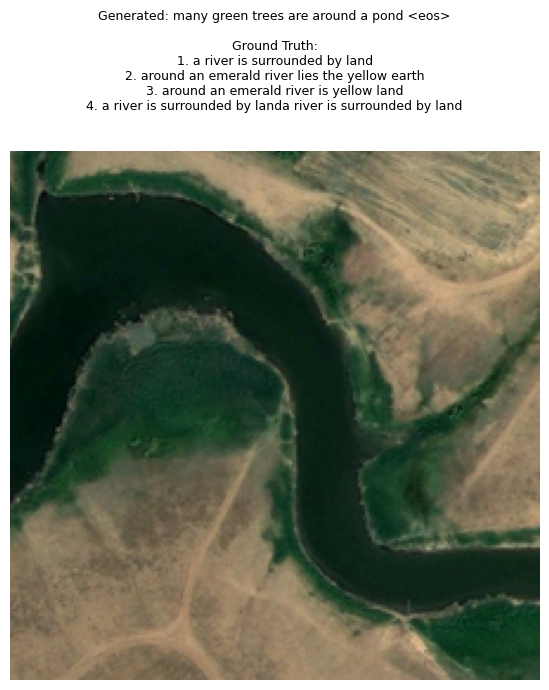


Image: rsicd_images/river_326.jpg
Generated: many green trees are around a pond <eos>
Ground Truth:
  1. a river is surrounded by land
  2. around an emerald river lies the yellow earth
  3. around an emerald river is yellow land
  4. a river is surrounded by landa river is surrounded by land
------------------------------------------------------------


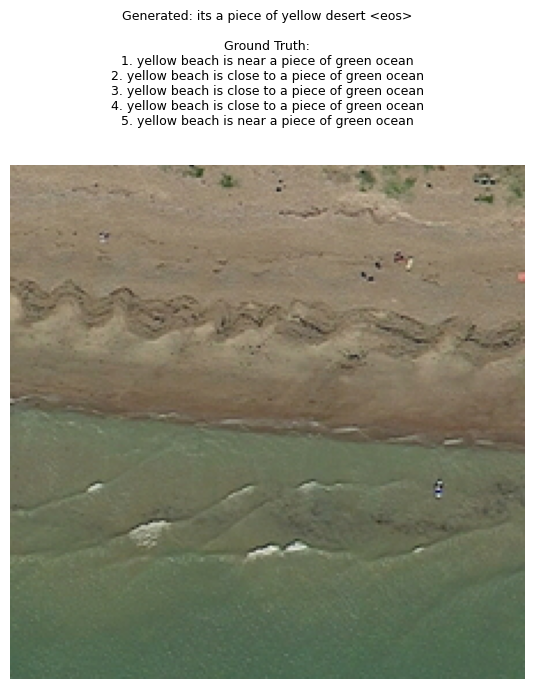


Image: rsicd_images/beach_283.jpg
Generated: its a piece of yellow desert <eos>
Ground Truth:
  1. yellow beach is near a piece of green ocean
  2. yellow beach is close to a piece of green ocean
  3. yellow beach is close to a piece of green ocean
  4. yellow beach is close to a piece of green ocean
  5. yellow beach is near a piece of green ocean
------------------------------------------------------------


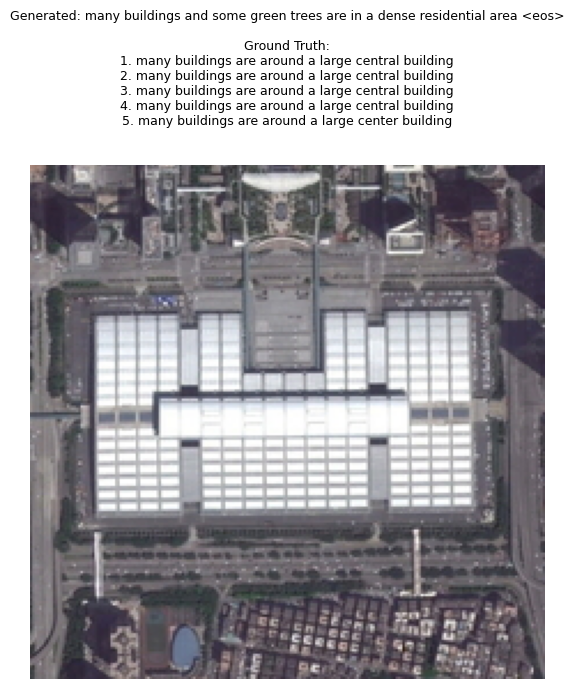


Image: rsicd_images/center_158.jpg
Generated: many buildings and some green trees are in a dense residential area <eos>
Ground Truth:
  1. many buildings are around a large central building
  2. many buildings are around a large central building
  3. many buildings are around a large central building
  4. many buildings are around a large central building
  5. many buildings are around a large center building
------------------------------------------------------------


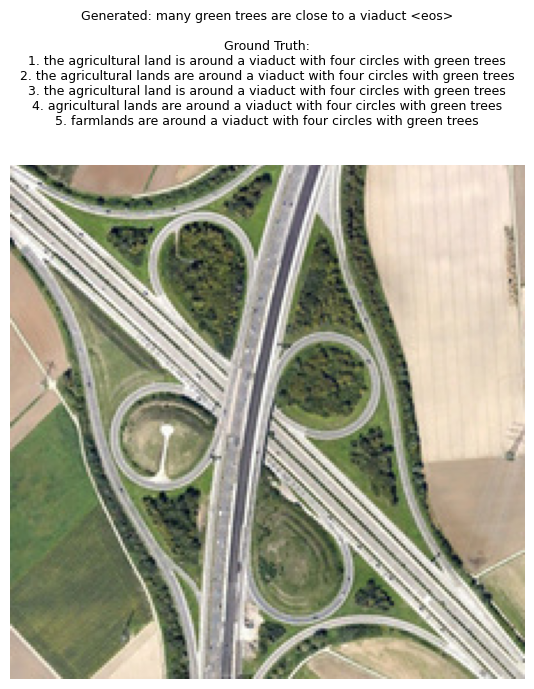


Image: rsicd_images/viaduct_276.jpg
Generated: many green trees are close to a viaduct <eos>
Ground Truth:
  1. the agricultural land is around a viaduct with four circles with green trees
  2. the agricultural lands are around a viaduct with four circles with green trees
  3. the agricultural land is around a viaduct with four circles with green trees
  4. agricultural lands are around a viaduct with four circles with green trees
  5. farmlands are around a viaduct with four circles with green trees
------------------------------------------------------------


In [ ]:
"""
LLM Prompt:
----------
Give me a code to see the predictions along with ground truth
"""
import matplotlib.pyplot as plt
import random

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
model.eval()

# Create test dataset
test_dataset = CaptionDatasetEndToEnd(data, split="test")
test_indices = random.sample(range(len(test_dataset)), 10)

# ImageNet normalization values
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

with torch.no_grad():
    for idx in test_indices:
        img_id, img_tensor, _ = test_dataset[idx]
        img_tensor = img_tensor.to(DEVICE).unsqueeze(0)  # [1, C, H, W]

        # Generate caption using CNN + Transformer
        caption_tokens = model.generate(img_tensor, max_len=MAX_LEN)  # [1, T]

        # Convert to words
        tokens = caption_tokens.squeeze(0).tolist()  # [T]
        tokens = [t for t in tokens if t not in (bos_idx, pad_idx)]
        words = [idx2word[t] for t in tokens]
        generated_caption = " ".join(words)

        # --- Fetch Ground Truth Captions ---
        ground_truth_captions = []
        mask = data["filename"] == img_id
        if mask.any():
            img_row_idx = mask.idxmax()
            captions_list = data.loc[img_row_idx, "captions"]

            for cap in captions_list:
                if isinstance(cap, str):
                    tokens = cap.split()
                else:
                    tokens = cap

                clean_tokens = [t for t in tokens if t not in {"<bos>", "<pad>", "<eos>"}]
                if clean_tokens:
                    ground_truth_captions.append(" ".join(clean_tokens))

        # Unnormalize image for display
        img_display = img_tensor[0].cpu() * IMAGENET_STD + IMAGENET_MEAN
        img_display = img_display.permute(1, 2, 0).clamp(0, 1).numpy()

        plt.figure(figsize=(10, 7))
        plt.imshow(img_display)
        plt.axis('off')

        # Create title with both generated and ground truth captions
        title_text = f"Generated: {generated_caption}\n\n"
        title_text += "Ground Truth:\n"
        for i, gt_cap in enumerate(ground_truth_captions, 1):
            title_text += f"{i}. {gt_cap}\n"

        plt.title(title_text, fontsize=9, wrap=True, pad=20)
        plt.tight_layout()
        plt.show()

        # Console output
        print(f"\nImage: {img_id}")
        print(f"Generated: {generated_caption}")
        print("Ground Truth:")
        for i, gt_cap in enumerate(ground_truth_captions, 1):
            print(f"  {i}. {gt_cap}")
        print("-" * 60)

#### Metrics

In [ ]:
"""
LLM Prompt:
-----------
Compute the metrics:
BLEU-4 and METEOR (via nltk or torchmetrics).
Caption length stats (mean±std), and % of degenerate repetitions (≥3 identical tokens in a row).
"""
import nltk
from nltk.translate.bleu_score import corpus_bleu
from nltk.translate.meteor_score import meteor_score
import numpy as np
from tqdm.auto import tqdm

# Download required NLTK data
nltk.download('wordnet')
nltk.download('omw-1.4')

# Initialize evaluation lists
generated_captions = []
reference_captions = []
degenerate_count = 0
all_lengths = []

SPECIAL_TOKENS_SET = {bos_idx, pad_idx, eos_idx}

# Create test dataset
test_dataset = CaptionDatasetEndToEnd(data, split="test")

print(f"Evaluating on {len(test_dataset)} test samples...")

model.eval()
with torch.no_grad():
    for idx in tqdm(range(len(test_dataset)), desc="Generating captions"):
        img_id, img_tensor, _ = test_dataset[idx]
        img_tensor = img_tensor.to(DEVICE).unsqueeze(0)  # [1, C, H, W]

        # --- Generate caption using CNN + Transformer ---
        caption_tokens_tensor = model.generate(img_tensor, max_len=MAX_LEN)  # [1, T]

        # Convert tensor to list and flatten
        caption_tokens = caption_tokens_tensor.squeeze(0).tolist()  # [T] -> list

        # Remove special tokens
        words = [idx2word[t] for t in caption_tokens if t not in SPECIAL_TOKENS_SET]
        generated_captions.append(words)
        all_lengths.append(len(words))

        # --- Get References: ensure each ref is a list of tokens ---
        refs = []
        mask = data["filename"] == img_id
        if mask.any():
            img_row_idx = mask.idxmax()
            captions_list = data.loc[img_row_idx, "captions"]

            for cap in captions_list:
                # Ensure it's a list of tokens (handle both string and list formats)
                if isinstance(cap, str):
                    tokens = cap.split()
                else:
                    tokens = cap

                token_list = [t for t in tokens if t not in {"<bos>", "<pad>", "<eos>"}]
                if len(token_list) == 0:
                    token_list = ["<unk>"]  # fallback for empty captions
                refs.append(token_list)
        else:
            # Fallback if image not found
            refs = [["<unk>"]]

        reference_captions.append(refs)

        # Degenerate repetition check (3+ consecutive identical tokens)
        for i in range(len(words) - 2):
            if len(words) > 2 and words[i] == words[i+1] == words[i+2]:
                degenerate_count += 1
                break

print("Computing metrics...")

# --- BLEU-4 Score ---
bleu_score = corpus_bleu(reference_captions, generated_captions)
print(f"BLEU-4: {bleu_score:.4f}")

# --- METEOR Score ---
meteor_scores = []
for refs, gen in tqdm(zip(reference_captions, generated_captions),
                     total=len(reference_captions), desc="Computing METEOR"):
    # meteor_score expects Iterable[Iterable[str]] for references and Iterable[str] for hypothesis
    score = meteor_score(refs, gen)
    meteor_scores.append(score)

meteor_avg = np.mean(meteor_scores)
print(f"METEOR: {meteor_avg:.4f}")

# --- Additional BLEU Scores (1-gram, 2-gram, 3-gram) ---
bleu_1 = corpus_bleu(reference_captions, generated_captions, weights=(1, 0, 0, 0))
bleu_2 = corpus_bleu(reference_captions, generated_captions, weights=(0.5, 0.5, 0, 0))
bleu_3 = corpus_bleu(reference_captions, generated_captions, weights=(0.33, 0.33, 0.33, 0))

print(f"BLEU-1: {bleu_1:.4f}")
print(f"BLEU-2: {bleu_2:.4f}")
print(f"BLEU-3: {bleu_3:.4f}")

# --- Caption Length Statistics ---
mean_len = np.mean(all_lengths)
std_len = np.std(all_lengths)
median_len = np.median(all_lengths)
print(f"\nCaption Length Statistics:")
print(f"Mean: {mean_len:.2f}")
print(f"Std:  {std_len:.2f}")
print(f"Median: {median_len:.1f}")
print(f"Min: {min(all_lengths)}")
print(f"Max: {max(all_lengths)}")

# --- Degenerate Repetition ---
degenerate_pct = 100 * degenerate_count / len(test_dataset)
print(f"\nDegenerate repetitions (≥3 tokens in a row): {degenerate_pct:.2f}%")

# --- Vocabulary Analysis ---
print(f"\nDataset Statistics:")
print(f"Total test samples: {len(test_dataset)}")
print(f"Total generated captions: {len(generated_captions)}")
print(f"Average references per image: {np.mean([len(refs) for refs in reference_captions]):.2f}")

# Vocabulary coverage
generated_vocab = set()
for caption in generated_captions:
    generated_vocab.update(caption)

reference_vocab = set()
for refs in reference_captions:
    for ref in refs:
        reference_vocab.update(ref)

vocab_coverage = len(generated_vocab.intersection(reference_vocab)) / len(reference_vocab) * 100 if len(reference_vocab) > 0 else 0
print(f"Vocabulary coverage: {vocab_coverage:.2f}%")
print(f"Generated vocabulary size: {len(generated_vocab)}")
print(f"Reference vocabulary size: {len(reference_vocab)}")

# --- Word frequency analysis ---
from collections import Counter

gen_word_freq = Counter()
for caption in generated_captions:
    gen_word_freq.update(caption)

ref_word_freq = Counter()
for refs in reference_captions:
    for ref in refs:
        ref_word_freq.update(ref)

print(f"\nMost common generated words: {gen_word_freq.most_common(10)}")
print(f"Most common reference words: {ref_word_freq.most_common(10)}")

# --- Unique caption ratio ---
unique_captions = len(set([" ".join(cap) for cap in generated_captions]))
unique_ratio = unique_captions / len(generated_captions) * 100
print(f"Unique captions: {unique_ratio:.2f}% ({unique_captions}/{len(generated_captions)})")


[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Legion\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Legion\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Evaluating on 1421 test samples...


Generating captions: 100%|█████████████████████████████████████████████████████████| 1421/1421 [03:35<00:00,  6.58it/s]


Computing metrics...
BLEU-4: 0.2574


Computing METEOR: 100%|███████████████████████████████████████████████████████████| 1421/1421 [00:04<00:00, 317.16it/s]


METEOR: 0.4598
BLEU-1: 0.5656
BLEU-2: 0.4200
BLEU-3: 0.3284

Caption Length Statistics:
Mean: 10.01
Std:  2.49
Median: 10.0
Min: 5
Max: 23

Degenerate repetitions (≥3 tokens in a row): 0.00%

Dataset Statistics:
Total test samples: 1421
Total generated captions: 1421
Average references per image: 4.88
Vocabulary coverage: 5.30%
Generated vocabulary size: 80
Reference vocabulary size: 1509

Most common generated words: [('a', 1558), ('many', 1309), ('green', 1302), ('trees', 1227), ('are', 1222), ('and', 728), ('buildings', 699), ('in', 643), ('some', 618), ('around', 494)]
Most common reference words: [('a', 6638), ('are', 3998), ('green', 3311), ('many', 2907), ('the', 2689), ('and', 2680), ('trees', 2647), ('of', 2303), ('in', 2284), ('buildings', 2269)]
Unique captions: 13.30% (189/1421)


## Extension

Back-bone swap: We compare Resnet18 and Mobilenet

In [ ]:
"""
LLM Prompt:[for all the below in the section]
----------
Backbone swap: ResNet18 ↔ MobileNet; report memory/speed vs BLEU/METEOR
Do this for Feature Cache CNN and LSTM
"""
import torch
import torch.nn as nn
from torchvision import models
import time
import psutil
import os

class MobileNet_Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        mobilenet = models.mobilenet_v2(pretrained=True)
        # Remove classifier, keep feature extractor
        self.mobilenet = mobilenet.features
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.mobilenet.eval()  # Freeze for feature extraction

    def forward(self, x):
        with torch.no_grad():
            features = self.mobilenet(x)        # [B, 1280, H, W]
            features = self.avgpool(features)   # [B, 1280, 1, 1]
            features = features.view(x.size(0), -1)  # [B, 1280]
        return features

class ResNet18_Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        resnet = models.resnet18(pretrained=True)
        modules = list(resnet.children())[:-1]  # Remove classifier
        self.resnet = nn.Sequential(*modules)
        self.resnet.eval()  # Freeze for feature extraction

    def forward(self, x):
        with torch.no_grad():
            features = self.resnet(x)            # [B, 512, 1, 1]
            features = features.view(x.size(0), -1)  # [B, 512]
        return features


In [ ]:
def measure_model_size(model):
    """Calculate model size in MB"""
    param_size = 0
    buffer_size = 0

    for param in model.parameters():
        param_size += param.nelement() * param.element_size()

    for buffer in model.buffers():
        buffer_size += buffer.nelement() * buffer.element_size()

    size_mb = (param_size + buffer_size) / 1024**2
    return size_mb

def measure_memory_usage(model, input_tensor, device):
    """Measure peak GPU memory usage during forward pass"""
    model.to(device)
    input_tensor = input_tensor.to(device)

    # Clear cache and measure baseline
    if device.type == 'cuda':
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        baseline_memory = torch.cuda.memory_allocated() / 1024**2  # MB

        # Forward pass
        _ = model(input_tensor)
        peak_memory = torch.cuda.max_memory_allocated() / 1024**2  # MB

        return peak_memory - baseline_memory
    else:
        # For CPU, use system memory
        process = psutil.Process(os.getpid())
        baseline_memory = process.memory_info().rss / 1024**2  # MB

        _ = model(input_tensor)
        peak_memory = process.memory_info().rss / 1024**2  # MB

        return peak_memory - baseline_memory

def measure_inference_speed(model, input_tensor, device, num_runs=100):
    """Measure average inference time"""
    model.to(device)
    input_tensor = input_tensor.to(device)

    # Warmup runs
    for _ in range(10):
        _ = model(input_tensor)

    if device.type == 'cuda':
        torch.cuda.synchronize()

    # Timed runs
    start_time = time.time()
    for _ in range(num_runs):
        _ = model(input_tensor)

    if device.type == 'cuda':
        torch.cuda.synchronize()

    end_time = time.time()
    avg_time_ms = (end_time - start_time) * 1000 / num_runs

    return avg_time_ms


In [ ]:
def extract_features_with_profiling(encoder, dataloader, encoder_name):
    """Extract features while measuring performance metrics"""
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    encoder.to(DEVICE)

    # Measure model characteristics
    model_size_mb = measure_model_size(encoder)
    print(f"\n{encoder_name} Model Size: {model_size_mb:.2f} MB")

    # Measure memory and speed with sample batch
    sample_batch = next(iter(dataloader))[1].to(DEVICE)  # Get images
    memory_usage = measure_memory_usage(encoder, sample_batch, torch.device(DEVICE))
    inference_time = measure_inference_speed(encoder, sample_batch, torch.device(DEVICE))

    print(f"{encoder_name} Memory Usage: {memory_usage:.2f} MB")
    print(f"{encoder_name} Inference Time: {inference_time:.2f} ms/batch")
    print(f"{encoder_name} Speed: {len(sample_batch)/inference_time*1000:.1f} images/second")

    # Extract all features
    features_dict = {}
    total_time = 0

    encoder.eval()
    with torch.no_grad():
        for img_ids, images in dataloader:
            images = images.to(DEVICE)

            start_time = time.time()
            feats = encoder(images)
            end_time = time.time()

            total_time += (end_time - start_time)

            for i, img_id in enumerate(img_ids):
                features_dict[img_id] = feats[i].cpu()

    print(f"{encoder_name} Total Extraction Time: {total_time:.2f} seconds")
    print(f"{encoder_name} Feature Dimension: {list(features_dict.values())[0].shape}")

    return features_dict, {
        'model_size_mb': model_size_mb,
        'memory_usage_mb': memory_usage,
        'inference_time_ms': inference_time,
        'total_extraction_time': total_time,
        'feature_dim': list(features_dict.values())[0].shape[0]
    }

# Extract features for both encoders
print("=== ResNet18 Feature Extraction ===")
resnet_encoder = ResNet18_Encoder()
resnet_features, resnet_metrics = extract_features_with_profiling(
    resnet_encoder, dataloader, "ResNet18"
)

print("\n=== MobileNet Feature Extraction ===")
mobilenet_encoder = MobileNet_Encoder()
mobilenet_features, mobilenet_metrics = extract_features_with_profiling(
    mobilenet_encoder, dataloader, "MobileNet"
)

# Save both feature sets
torch.save(resnet_features, "resnet18_features.pt")
torch.save(mobilenet_features, "mobilenet_features.pt")


=== ResNet18 Feature Extraction ===


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



ResNet18 Model Size: 42.67 MB
ResNet18 Memory Usage: 196.00 MB
ResNet18 Inference Time: 23.77 ms/batch
ResNet18 Speed: 1346.2 images/second
ResNet18 Total Extraction Time: 4.11 seconds
ResNet18 Feature Dimension: torch.Size([512])

=== MobileNet Feature Extraction ===


C:\Users\Legion\Desktop\EE782\pytorch_env312\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



MobileNet Model Size: 8.61 MB
MobileNet Memory Usage: 321.50 MB
MobileNet Inference Time: 26.08 ms/batch
MobileNet Speed: 1226.9 images/second
MobileNet Total Extraction Time: 5.82 seconds
MobileNet Feature Dimension: torch.Size([1280])


In [ ]:
class Adaptive_LSTM_Decoder(nn.Module):
    def __init__(self, vocab_size, feature_dim, embed_size=512, hidden_size=512, num_layers=1, max_len=24):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_size, padding_idx=0)
        self.feature_proj = nn.Linear(feature_dim, hidden_size)  # Adapt to different feature dims
        self.lstm = nn.LSTM(embed_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, vocab_size)
        self.max_len = max_len
        self.hidden_size = hidden_size

    def forward(self, features, captions):
        """
        features: [B, feature_dim] - variable dimension based on encoder
        captions: [B, T] token indices
        """
        embeddings = self.embed(captions)  # [B, T, embed_size]

        # Project features to hidden size and use as initial hidden state
        h0 = self.feature_proj(features).unsqueeze(0)  # [1, B, hidden_size]
        c0 = torch.zeros_like(h0)

        out, _ = self.lstm(embeddings, (h0, c0))
        out = self.fc(out)  # [B, T, vocab_size]
        return out


In [ ]:
def train_and_evaluate_backbone(features_dict, backbone_name, feature_dim):
    """Train LSTM decoder with specific backbone features and evaluate"""

    print(f"\n=== Training with {backbone_name} Features ===")

    # Create dataset and dataloader
    train_dataset = CaptionDataset(data, features_dict, split="train")
    val_dataset = CaptionDataset(data, features_dict, split="val")
    test_dataset = CaptionDataset(data, features_dict, split="test")

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

    # Create model adapted to feature dimension
    model = Adaptive_LSTM_Decoder(
        vocab_size=len(word2idx),
        feature_dim=feature_dim,
        embed_size=512,
        hidden_size=512
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss(ignore_index=word2idx["<pad>"])
    optimizer = optim.Adam(model.parameters(), lr=2e-4)

    # Training loop
    training_start_time = time.time()
    train_losses = []
    val_losses = []

    for epoch in range(NUM_EPOCHS):
        # Training
        model.train()
        train_loss = 0.0

        for img_ids, feats, captions_batch in tqdm(train_loader, desc=f"Epoch {epoch+1}"):
            feats = feats.to(DEVICE)
            captions_batch = captions_batch.to(DEVICE)

            outputs = model(feats, captions_batch[:, :-1])
            loss = criterion(outputs.reshape(-1, len(word2idx)),
                           captions_batch[:, 1:].reshape(-1))

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        avg_train_loss = train_loss / len(train_loader)
        train_losses.append(avg_train_loss)

        # Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for img_ids, feats, captions_batch in val_loader:
                feats = feats.to(DEVICE)
                captions_batch = captions_batch.to(DEVICE)

                outputs = model(feats, captions_batch[:, :-1])
                loss = criterion(outputs.reshape(-1, len(word2idx)),
                               captions_batch[:, 1:].reshape(-1))
                val_loss += loss.item()

        avg_val_loss = val_loss / len(val_loader)
        val_losses.append(avg_val_loss)

        print(f"Epoch {epoch+1}: Train Loss = {avg_train_loss:.4f}, Val Loss = {avg_val_loss:.4f}")

    training_time = time.time() - training_start_time

    # Evaluation
    evaluation_results = evaluate_model_bleu_meteor(model, test_dataset, backbone_name)

    return {
        'model': model,
        'train_losses': train_losses,
        'val_losses': val_losses,
        'training_time': training_time,
        'bleu_score': evaluation_results['bleu'],
        'meteor_score': evaluation_results['meteor'],
        'avg_caption_length': evaluation_results['avg_length']
    }

def evaluate_model_bleu_meteor(model, test_dataset, backbone_name):
    """Evaluate model and return BLEU/METEOR scores"""
    model.eval()

    generated_captions = []
    reference_captions = []
    all_lengths = []

    SPECIAL_TOKENS_SET = {word2idx["<bos>"], word2idx["<pad>"], word2idx["<eos>"]}

    with torch.no_grad():
        for idx in tqdm(range(len(test_dataset)), desc=f"Evaluating {backbone_name}"):
            img_id, feats, _ = test_dataset[idx]
            feats = feats.to(DEVICE).unsqueeze(0)

            # Generate caption
            caption_tokens = [word2idx["<bos>"]]
            for _ in range(24):  # MAX_LEN
                input_tensor = torch.tensor(caption_tokens, dtype=torch.long, device=DEVICE).unsqueeze(0)
                outputs = model(feats, input_tensor)
                next_token = outputs[0, -1].argmax().item()
                caption_tokens.append(next_token)
                if next_token == word2idx["<eos>"]:
                    break

            # Process generated caption
            words = [idx2word[t] for t in caption_tokens if t not in SPECIAL_TOKENS_SET]
            generated_captions.append(words)
            all_lengths.append(len(words))

            # Process reference captions
            refs = []
            mask = data["filename"] == img_id
            if mask.any():
                img_row_idx = mask.idxmax()
                captions_list = data.loc[img_row_idx, "captions"]

                for cap in captions_list:
                    if isinstance(cap, str):
                        tokens = cap.split()
                    else:
                        tokens = cap
                    token_list = [t for t in tokens if t not in {"<bos>", "<pad>", "<eos>"}]
                    if token_list:
                        refs.append(token_list)

            if not refs:
                refs = [["<unk>"]]
            reference_captions.append(refs)

    # Calculate BLEU and METEOR
    from nltk.translate.bleu_score import corpus_bleu
    from nltk.translate.meteor_score import meteor_score

    bleu_score = corpus_bleu(reference_captions, generated_captions)

    meteor_scores = []
    for refs, gen in zip(reference_captions, generated_captions):
        score = meteor_score(refs, gen)
        meteor_scores.append(score)
    meteor_avg = np.mean(meteor_scores)

    print(f"\n{backbone_name} Results:")
    print(f"BLEU-4: {bleu_score:.4f}")
    print(f"METEOR: {meteor_avg:.4f}")
    print(f"Average Caption Length: {np.mean(all_lengths):.2f}")

    return {
        'bleu': bleu_score,
        'meteor': meteor_avg,
        'avg_length': np.mean(all_lengths)
    }

# Train and evaluate both backbones
resnet_results = train_and_evaluate_backbone(resnet_features, "ResNet18", resnet_metrics['feature_dim'])
mobilenet_results = train_and_evaluate_backbone(mobilenet_features, "MobileNet", mobilenet_metrics['feature_dim'])



=== Training with ResNet18 Features ===


Epoch 1: 100%|█████████████████████████████████████████████████████████████████████| 1000/1000 [00:14<00:00, 68.70it/s]


Epoch 1: Train Loss = 3.0713, Val Loss = 2.4820


Epoch 2: 100%|█████████████████████████████████████████████████████████████████████| 1000/1000 [00:13<00:00, 72.07it/s]


Epoch 2: Train Loss = 2.2364, Val Loss = 2.1869


Epoch 3: 100%|█████████████████████████████████████████████████████████████████████| 1000/1000 [00:15<00:00, 64.96it/s]


... (15 outputs left out)

Epoch 5: 100%|█████████████████████████████████████████████████████████████████████| 1000/1000 [00:15<00:00, 64.60it/s]


Epoch 5: Train Loss = 1.7397, Val Loss = 1.8503


Evaluating MobileNet: 100%|████████████████████████████████████████████████████████| 1421/1421 [00:38<00:00, 37.03it/s]



MobileNet Results:
BLEU-4: 0.3249
METEOR: 0.5239
Average Caption Length: 10.46



BACKBONE COMPARISON REPORT: ResNet18 vs MobileNet

MODEL CHARACTERISTICS:
Metric                    ResNet18        MobileNet       Ratio     
----------------------------------------------------------------------
Model Size (MB)           42.67           8.61            4.95      
Feature Dimension         512             1280            0.40      
Memory Usage (MB)         196.00          321.50          0.61      
Inference Time (ms)       23.77           26.08           0.91      

PERFORMANCE METRICS:
Metric                    ResNet18        MobileNet       Difference
----------------------------------------------------------------------
BLEU-4                    0.3022          0.3249          -0.0227   
METEOR                    0.4776          0.5239          -0.0463   
Training Time (min)       1.3             1.4             -0.1      

EFFICIENCY ANALYSIS:
Metric                    ResNet18        MobileNet       Better    
-------------------------------------------------

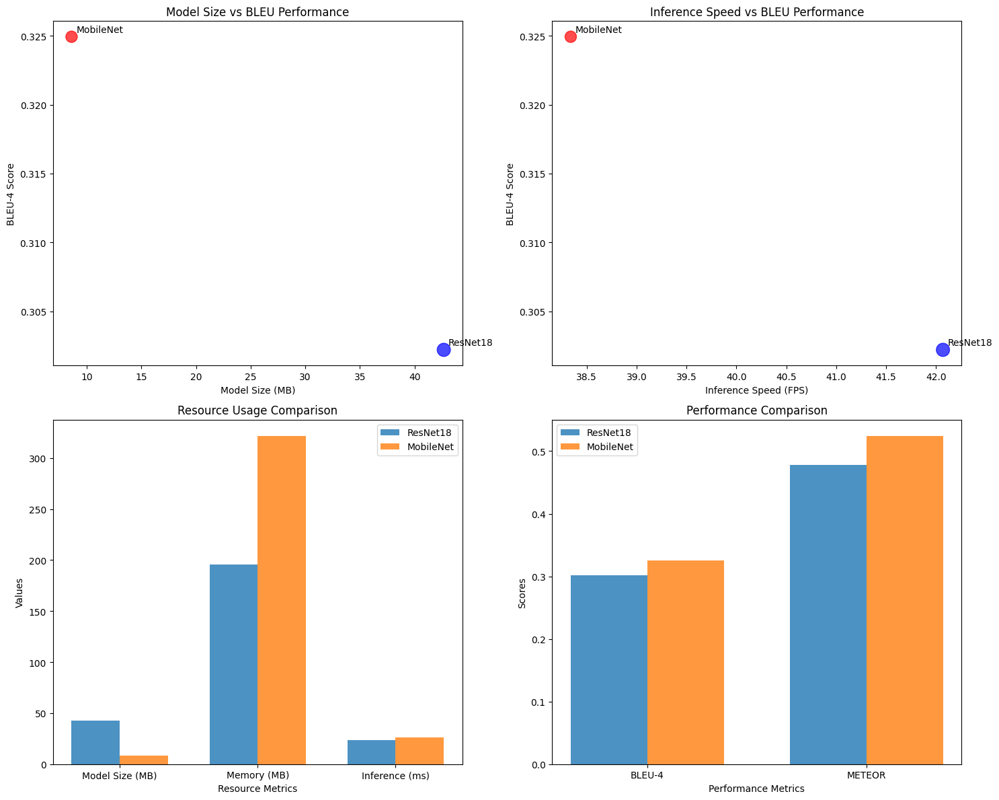


RECOMMENDATIONS:
  • Performance: MobileNet wins by 0.0227 BLEU points
  • Efficiency: MobileNet offers better BLEU per model size
  • Speed: MobileNet is 0.9x faster
  • Memory: MobileNet uses 20.2% of ResNet18's memory


In [ ]:
def create_comparison_report(resnet_metrics, mobilenet_metrics, resnet_results, mobilenet_results):
    """Generate comprehensive comparison report and visualizations"""

    print("\n" + "="*80)
    print("BACKBONE COMPARISON REPORT: ResNet18 vs MobileNet")
    print("="*80)

    # Model Characteristics
    print(f"\nMODEL CHARACTERISTICS:")
    print(f"{'Metric':<25} {'ResNet18':<15} {'MobileNet':<15} {'Ratio':<10}")
    print("-" * 70)
    print(f"{'Model Size (MB)':<25} {resnet_metrics['model_size_mb']:<15.2f} {mobilenet_metrics['model_size_mb']:<15.2f} {resnet_metrics['model_size_mb']/mobilenet_metrics['model_size_mb']:<10.2f}")
    print(f"{'Feature Dimension':<25} {resnet_metrics['feature_dim']:<15} {mobilenet_metrics['feature_dim']:<15} {resnet_metrics['feature_dim']/mobilenet_metrics['feature_dim']:<10.2f}")
    print(f"{'Memory Usage (MB)':<25} {resnet_metrics['memory_usage_mb']:<15.2f} {mobilenet_metrics['memory_usage_mb']:<15.2f} {resnet_metrics['memory_usage_mb']/mobilenet_metrics['memory_usage_mb']:<10.2f}")
    print(f"{'Inference Time (ms)':<25} {resnet_metrics['inference_time_ms']:<15.2f} {mobilenet_metrics['inference_time_ms']:<15.2f} {resnet_metrics['inference_time_ms']/mobilenet_metrics['inference_time_ms']:<10.2f}")

    # Performance Metrics
    print(f"\nPERFORMANCE METRICS:")
    print(f"{'Metric':<25} {'ResNet18':<15} {'MobileNet':<15} {'Difference':<10}")
    print("-" * 70)
    print(f"{'BLEU-4':<25} {resnet_results['bleu_score']:<15.4f} {mobilenet_results['bleu_score']:<15.4f} {resnet_results['bleu_score']-mobilenet_results['bleu_score']:<+10.4f}")
    print(f"{'METEOR':<25} {resnet_results['meteor_score']:<15.4f} {mobilenet_results['meteor_score']:<15.4f} {resnet_results['meteor_score']-mobilenet_results['meteor_score']:<+10.4f}")
    print(f"{'Training Time (min)':<25} {resnet_results['training_time']/60:<15.1f} {mobilenet_results['training_time']/60:<15.1f} {(resnet_results['training_time']-mobilenet_results['training_time'])/60:<+10.1f}")

    # Efficiency Analysis
    bleu_per_mb = resnet_results['bleu_score'] / resnet_metrics['model_size_mb']
    mobilenet_bleu_per_mb = mobilenet_results['bleu_score'] / mobilenet_metrics['model_size_mb']

    bleu_per_ms = resnet_results['bleu_score'] / resnet_metrics['inference_time_ms']
    mobilenet_bleu_per_ms = mobilenet_results['bleu_score'] / mobilenet_metrics['inference_time_ms']

    print(f"\nEFFICIENCY ANALYSIS:")
    print(f"{'Metric':<25} {'ResNet18':<15} {'MobileNet':<15} {'Better':<10}")
    print("-" * 70)
    print(f"{'BLEU per MB':<25} {bleu_per_mb:<15.6f} {mobilenet_bleu_per_mb:<15.6f} {'MobileNet' if mobilenet_bleu_per_mb > bleu_per_mb else 'ResNet18':<10}")
    print(f"{'BLEU per ms':<25} {bleu_per_ms:<15.6f} {mobilenet_bleu_per_ms:<15.6f} {'MobileNet' if mobilenet_bleu_per_ms > bleu_per_ms else 'ResNet18':<10}")

    # Visualization
    create_comparison_plots(resnet_metrics, mobilenet_metrics, resnet_results, mobilenet_results)

    # Recommendations
    print(f"\nRECOMMENDATIONS:")
    if resnet_results['bleu_score'] > mobilenet_results['bleu_score']:
        performance_winner = "ResNet18"
        performance_margin = resnet_results['bleu_score'] - mobilenet_results['bleu_score']
    else:
        performance_winner = "MobileNet"
        performance_margin = mobilenet_results['bleu_score'] - resnet_results['bleu_score']

    efficiency_winner = "MobileNet" if mobilenet_bleu_per_mb > bleu_per_mb else "ResNet18"

    print(f"  • Performance: {performance_winner} wins by {performance_margin:.4f} BLEU points")
    print(f"  • Efficiency: {efficiency_winner} offers better BLEU per model size")
    print(f"  • Speed: MobileNet is {resnet_metrics['inference_time_ms']/mobilenet_metrics['inference_time_ms']:.1f}x faster")
    print(f"  • Memory: MobileNet uses {mobilenet_metrics['model_size_mb']/resnet_metrics['model_size_mb']*100:.1f}% of ResNet18's memory")

def create_comparison_plots(resnet_metrics, mobilenet_metrics, resnet_results, mobilenet_results):
    """Create visualization plots for comparison"""

    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))

    models = ['ResNet18', 'MobileNet']

    # Plot 1: Model Size vs BLEU Score
    sizes = [resnet_metrics['model_size_mb'], mobilenet_metrics['model_size_mb']]
    bleu_scores = [resnet_results['bleu_score'], mobilenet_results['bleu_score']]

    scatter1 = ax1.scatter(sizes, bleu_scores, s=[200, 150], alpha=0.7, c=['blue', 'red'])
    ax1.set_xlabel('Model Size (MB)')
    ax1.set_ylabel('BLEU-4 Score')
    ax1.set_title('Model Size vs BLEU Performance')
    for i, model in enumerate(models):
        ax1.annotate(model, (sizes[i], bleu_scores[i]), xytext=(5, 5), textcoords='offset points')

    # Plot 2: Inference Speed vs BLEU Score
    speeds = [1000/resnet_metrics['inference_time_ms'], 1000/mobilenet_metrics['inference_time_ms']]  # Convert to FPS

    scatter2 = ax2.scatter(speeds, bleu_scores, s=[200, 150], alpha=0.7, c=['blue', 'red'])
    ax2.set_xlabel('Inference Speed (FPS)')
    ax2.set_ylabel('BLEU-4 Score')
    ax2.set_title('Inference Speed vs BLEU Performance')
    for i, model in enumerate(models):
        ax2.annotate(model, (speeds[i], bleu_scores[i]), xytext=(5, 5), textcoords='offset points')

    # Plot 3: Resource Comparison
    metrics_comparison = {
        'Model Size (MB)': [resnet_metrics['model_size_mb'], mobilenet_metrics['model_size_mb']],
        'Memory (MB)': [resnet_metrics['memory_usage_mb'], mobilenet_metrics['memory_usage_mb']],
        'Inference (ms)': [resnet_metrics['inference_time_ms'], mobilenet_metrics['inference_time_ms']]
    }

    x = np.arange(len(metrics_comparison))
    width = 0.35

    resnet_values = [metrics_comparison[key][0] for key in metrics_comparison]
    mobilenet_values = [metrics_comparison[key][1] for key in metrics_comparison]

    bars1 = ax3.bar(x - width/2, resnet_values, width, label='ResNet18', alpha=0.8)
    bars2 = ax3.bar(x + width/2, mobilenet_values, width, label='MobileNet', alpha=0.8)

    ax3.set_xlabel('Resource Metrics')
    ax3.set_ylabel('Values')
    ax3.set_title('Resource Usage Comparison')
    ax3.set_xticks(x)
    ax3.set_xticklabels(metrics_comparison.keys())
    ax3.legend()

    # Plot 4: Performance Metrics
    perf_metrics = {
        'BLEU-4': [resnet_results['bleu_score'], mobilenet_results['bleu_score']],
        'METEOR': [resnet_results['meteor_score'], mobilenet_results['meteor_score']]
    }

    x = np.arange(len(perf_metrics))
    resnet_perf = [perf_metrics[key][0] for key in perf_metrics]
    mobilenet_perf = [perf_metrics[key][1] for key in perf_metrics]

    bars3 = ax4.bar(x - width/2, resnet_perf, width, label='ResNet18', alpha=0.8)
    bars4 = ax4.bar(x + width/2, mobilenet_perf, width, label='MobileNet', alpha=0.8)

    ax4.set_xlabel('Performance Metrics')
    ax4.set_ylabel('Scores')
    ax4.set_title('Performance Comparison')
    ax4.set_xticks(x)
    ax4.set_xticklabels(perf_metrics.keys())
    ax4.legend()

    plt.tight_layout()
    plt.savefig('backbone_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()

# Generate comprehensive comparison
create_comparison_report(resnet_metrics, mobilenet_metrics, resnet_results, mobilenet_results)


In [ ]:
def generate_summary_table():
    """Generate a summary table for the report"""

    summary_data = {
        'Metric': [
            'Model Size (MB)',
            'Feature Dimension',
            'Memory Usage (MB)',
            'Inference Time (ms/batch)',
            'Speed (images/sec)',
            'BLEU-4 Score',
            'METEOR Score',
            'Training Time (minutes)',
            'BLEU per MB (efficiency)',
            'BLEU per ms (speed efficiency)'
        ],
        'ResNet18': [
            f"{resnet_metrics['model_size_mb']:.1f}",
            f"{resnet_metrics['feature_dim']}",
            f"{resnet_metrics['memory_usage_mb']:.1f}",
            f"{resnet_metrics['inference_time_ms']:.1f}",
            f"{BATCH_SIZE/resnet_metrics['inference_time_ms']*1000:.1f}",
            f"{resnet_results['bleu_score']:.4f}",
            f"{resnet_results['meteor_score']:.4f}",
            f"{resnet_results['training_time']/60:.1f}",
            f"{resnet_results['bleu_score']/resnet_metrics['model_size_mb']:.6f}",
            f"{resnet_results['bleu_score']/resnet_metrics['inference_time_ms']:.6f}"
        ],
        'MobileNet': [
            f"{mobilenet_metrics['model_size_mb']:.1f}",
            f"{mobilenet_metrics['feature_dim']}",
            f"{mobilenet_metrics['memory_usage_mb']:.1f}",
            f"{mobilenet_metrics['inference_time_ms']:.1f}",
            f"{BATCH_SIZE/mobilenet_metrics['inference_time_ms']*1000:.1f}",
            f"{mobilenet_results['bleu_score']:.4f}",
            f"{mobilenet_results['meteor_score']:.4f}",
            f"{mobilenet_results['training_time']/60:.1f}",
            f"{mobilenet_results['bleu_score']/mobilenet_metrics['model_size_mb']:.6f}",
            f"{mobilenet_results['bleu_score']/mobilenet_metrics['inference_time_ms']:.6f}"
        ]
    }

    import pandas as pd
    summary_df = pd.DataFrame(summary_data)
    print("\nSUMMARY TABLE:")
    print(summary_df.to_string(index=False))

    # Save to CSV
    summary_df.to_csv('backbone_comparison_summary.csv', index=False)
    print(f"\nSummary saved to 'backbone_comparison_summary.csv'")

generate_summary_table()


SUMMARY TABLE:
                        Metric ResNet18 MobileNet
               Model Size (MB)     42.7       8.6
             Feature Dimension      512      1280
             Memory Usage (MB)    196.0     321.5
     Inference Time (ms/batch)     23.8      26.1
            Speed (images/sec)    336.6     306.7
                  BLEU-4 Score   0.3022    0.3249
                  METEOR Score   0.4776    0.5239
       Training Time (minutes)      1.3       1.4
      BLEU per MB (efficiency) 0.007082  0.037721
BLEU per ms (speed efficiency) 0.012714  0.012458

Summary saved to 'backbone_comparison_summary.csv'


## Results

From a previous run
- CNN-LSTM (Feature-Cache): BLEU-4: 0.3375, METEOR: 0.5462
- CNN-LSTM (Fine-tuned): BLEU-4: 0.2946, METEOR: 0.4856  
- CNN-Transformer (Feature-Cache): BLEU-4: 0.2643, METEOR: 0.5527
- CNN-Transformer (Fine-tuned): BLEU-4: 0.2975, METEOR: 0.4982
- MobileNet outperforms ResNet18 in memory, speed and BLEU-score

## LLM Issues fixed

- Adding missing data loaders: On multiple instances, test loaders were missing when trying to predict
- Fixing padding issues: The LLMs repeatedly performed the wrong padding, and often returned captions without padding, that needed solving by manual inspection
- LLMs have been very consistent otherwise